# F1 Podium – Milestone 1

## Executive summary

**Data and cleaning**
- **Data:** the Ergast Formula 1 dataset, 14 relational tables, 1950–2024 (`results`: 26,759 rows). The audit found 85 duplicate `(raceId, driverId)` groups, 1,638 rows with `grid == 0` and 22/46 empty strings hidden in `qualifying.q2`/`q3`; all keys and foreign keys are intact.
- **Cleaning:** placeholders to missing, dates and durations typed (one tested parser), no row removed by the generic cleaning. The entries table drops the duplicate groups completely (ADR 0002) and the Indianapolis 500 (ADR 0003): 26,759 → 26,223 rows.
- **Modeling Table:** 8,970 Entries in 428 races, 2003–2024, split by season: train 2003–2019 (6,831), validation 2020–2021 (780), test 2022–2024 (1,359); podium rate 14–15 %.

**Data-engineering questions**
- **Question 1 (front-row conversion):** a front-row start became a podium more often after 2014, 68.0 % → 76.0 % (+8.0 points, 95 % interval +2.0 to +14.0); no single circuit changed detectably.
- **Question 2 (home advantage):** raw, home races look like a disadvantage (11.7 % vs. 13.7 %); controlled for grid and decade there is no evidence of a home advantage (odds ratio 0.92, 0.75–1.13).
- **Question 3 (mechanical retirements):** rarer under the 2022 regulations, 9.1 % → 5.6 % of starts (−3.5 points, −5.1 to −1.9); McLaren and Red Bull improved, Alfa Romeo got worse.

**Model:** logistic regression on 15 pre-race features, chosen on validation (PR-AUC 0.736 vs. 0.639 for the grid-only baseline). On test (2022–2024, used once): **PR-AUC 0.706** (baseline 0.647), F1 0.675 at the validation threshold.

**Explainability, top three findings** (associations in the model, not causes)
1. Grid and qualifying carry most of the signal: Grid Position and Qualifying Position have the largest permutation importance (PR-AUC drop 0.118 and 0.113) and SHAP contributions.
2. The championship standings before the race are the second strongest group (group permutation 0.127, close to the grid group's 0.132).
3. Recent form adds little on top: driver form 0.036, constructor form 0.021; in the ablation only the qualifying group is needed, because grid and qualifying largely substitute for each other.

## Contents

- [Loading the raw data](#sec-load)
- [Audit of the raw data (baseline before cleaning)](#sec-audit)
- [0. Base table](#sec-0)
- [1. Seasons](#sec-1)
- [2. Status and non-Starters](#sec-2)
- [3. grid == 0](#sec-3)
- [4. Duplicate groups](#sec-4)
- [5. Races without exactly three podium rows](#sec-5)
- [6. Indianapolis 500](#sec-6)
- [7. Sprints](#sec-7)
- [8. Cleaning to data/clean/](#sec-8)
- [9. Entries table](#sec-9)
- [10. Modeling Table skeleton](#sec-10)
- [11. Before/after: raw vs. cleaned data](#sec-11)
- [12. Reference data and Starters for the data-engineering questions](#sec-12)
- [13. Question 1: front-row conversion by circuit, before and after 2014](#sec-13)
- [14. Question 2: home advantage, controlled for grid](#sec-14)
- [15. Question 3: mechanical retirements, 2014–2021 vs. 2022–2024](#sec-15)
- [16. Feature engineering](#sec-16)
- [17. Feature EDA (train only, 2003–2019)](#sec-17)
- [18. Preprocessing pipeline](#sec-18)
- [19. Models](#sec-19)
- [20. Evaluation on validation and model choice](#sec-20)
- [21. Test evaluation (2022–2024), once](#sec-21)
- [22. Experiments: ablation and preprocessing order (E1, E2)](#sec-22)
- [23. Explainability of the chosen model](#sec-23)
- [24. Inference function predict_podium](#sec-24)
- [25. Limitations](#sec-25)
- [Closing: raw protection](#sec-closing)

<a id="sec-load"></a>
## Loading the raw data

All CSVs from `data/raw/` (Ergast format: `\N` marks missing values).

`load_tables` treats **only** `\N` as missing (`keep_default_na=False`). With the pandas
defaults, empty strings would also silently become NaN; the audit could then no longer
show which gaps are really stored as `\N` in the raw data and which are coded
differently (see "Empty strings" below).

In [1]:
import hashlib
import os
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import keras  # noqa: E402  (after the TensorFlow log level is set)
import shap  # noqa: E402
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator, PercentFormatter

plt.rcParams["figure.max_open_warning"] = 0  # the notebook keeps its figures open for display

KAGGLE_INPUT = Path("/kaggle/input")
if KAGGLE_INPUT.exists():
    # On Kaggle: raw CSVs and data/reference come from an attached dataset (read-only),
    # every output goes to the writable working directory.
    RAW = next(KAGGLE_INPUT.rglob("races.csv")).parent
    REFERENCE = next(KAGGLE_INPUT.rglob("raw_sha256.txt")).parent
    OUTPUT = Path("/kaggle/working")
    FIGURES, CLEAN = OUTPUT / "figures", OUTPUT / "clean"
else:
    # In the repository: the kernel runs in notebooks/.
    RAW, REFERENCE = Path("../data/raw"), Path("../data/reference")
    FIGURES, CLEAN = Path("../reports/figures"), Path("../data/clean")
FIGURES.mkdir(parents=True, exist_ok=True)  # every report figure is also saved here as PNG
CLEAN.mkdir(parents=True, exist_ok=True)
RAW_CHECKSUMS = REFERENCE / "raw_sha256.txt"


BLUE = "#2a78d6"
ORANGE = "#eb6834"
MUTED = "#52514e"


def style_axes(ax):
    """Recessive axes: horizontal grid lines only, no top/right spine."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)


def save_figure(fig, name):
    """Save a figure as `reports/figures/<name>.png` and return it for display."""
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    return fig


def file_checksums(folder):
    """SHA-256 of every CSV in a folder as {file name: hex digest}."""
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(folder.glob("*.csv"))}


def read_checksum_list(path):
    """Checksum list in `shasum` format (`<digest>  <file>`) as {file name: hex digest}."""
    lines = path.read_text().splitlines()
    return {name: digest for digest, name in (line.split(maxsplit=1) for line in lines if line.strip())}


def load_tables(folder):
    """All CSVs of a folder as {table name: DataFrame}; only `\\N` counts as missing."""
    return {
        p.stem: pd.read_csv(p, na_values=[r"\N"], keep_default_na=False)
        for p in sorted(folder.glob("*.csv"))
    }

### Raw protection

`data/raw/` is read-only. The versioned list `data/reference/raw_sha256.txt` holds the
SHA-256 checksum of each of the 14 CSVs (`shasum -a 256` format). The notebook checks it
here, before any raw table is loaded, and again in the last cell: a changed or replaced
raw file stops the run instead of being used silently.

In [2]:
expected_checksums = read_checksum_list(RAW_CHECKSUMS)
assert len(expected_checksums) == 14
assert file_checksums(RAW) == expected_checksums

raw = load_tables(RAW)

### `\N` check

`load_tables` should turn exactly the literal `\N` into missing values, nothing more and
nothing less. The check reads every file again as plain strings, without any NA
conversion, and compares per column the count of literal `\N` with the missing count
after loading. It fails if loading turns any other value into a missing one, or misses a
`\N`.

In [3]:
def literal_na_counts(folder):
    """Count of literal `\\N` per (table, column), read as plain strings without NA conversion."""
    return pd.concat({p.stem: pd.read_csv(p, dtype=str, na_filter=False).eq(r"\N").sum()
                      for p in sorted(folder.glob("*.csv"))})


def missing_counts(tables):
    """Missing values per (table, column)."""
    return pd.concat({name: df.isna().sum() for name, df in tables.items()})


pd.testing.assert_series_equal(literal_na_counts(RAW), missing_counts(raw))
print(f"{int(missing_counts(raw).sum()):,} missing values after loading, each a literal \\N in the raw files")

160,076 missing values after loading, each a literal \N in the raw files


In [4]:
for name, df in raw.items():
    print(f"{name}: {', '.join(df.columns)}")

circuits: circuitId, circuitRef, name, location, country, lat, lng, alt, url
constructor_results: constructorResultsId, raceId, constructorId, points, status
constructor_standings: constructorStandingsId, raceId, constructorId, points, position, positionText, wins
constructors: constructorId, constructorRef, name, nationality, url
driver_standings: driverStandingsId, raceId, driverId, points, position, positionText, wins
drivers: driverId, driverRef, number, code, forename, surname, dob, nationality, url
lap_times: raceId, driverId, lap, position, time, milliseconds
pit_stops: raceId, driverId, stop, lap, time, duration, milliseconds
qualifying: qualifyId, raceId, driverId, constructorId, number, position, q1, q2, q3
races: raceId, year, round, circuitId, name, date, time, url, fp1_date, fp1_time, fp2_date, fp2_time, fp3_date, fp3_time, quali_date, quali_time, sprint_date, sprint_time
results: resultId, raceId, driverId, constructorId, number, grid, position, positionText, positionOrde

<a id="sec-audit"></a>
## Audit of the raw data (baseline before cleaning)

For each of the 14 tables: row count, share of `\N` per column, uniqueness and
completeness of the primary key, and a foreign-key check. All checks are functions over a
`{name: DataFrame}` dict, so the same audit can later run on `data/clean/` and we can
compare before and after.

**Keys** follow the Ergast schema. `pk` is the technical primary key, `nk` the natural key
(what a row means, e.g. an Entry = `(raceId, driverId)` in `results`). `lap_times` and
`pit_stops` have no ID column; their primary key is composite.

In [5]:
RACE = ("races", "raceId")
DRIVER = ("drivers", "driverId")
CONSTRUCTOR = ("constructors", "constructorId")
STATUS = ("status", "statusId")

KEYS = {
    "circuits": {"pk": ["circuitId"], "nk": ["circuitRef"], "fk": {}},
    "constructor_results": {
        "pk": ["constructorResultsId"],
        "nk": ["raceId", "constructorId"],
        "fk": {"raceId": RACE, "constructorId": CONSTRUCTOR},
    },
    "constructor_standings": {
        "pk": ["constructorStandingsId"],
        "nk": ["raceId", "constructorId"],
        "fk": {"raceId": RACE, "constructorId": CONSTRUCTOR},
    },
    "constructors": {"pk": ["constructorId"], "nk": ["constructorRef"], "fk": {}},
    "driver_standings": {
        "pk": ["driverStandingsId"],
        "nk": ["raceId", "driverId"],
        "fk": {"raceId": RACE, "driverId": DRIVER},
    },
    "drivers": {"pk": ["driverId"], "nk": ["driverRef"], "fk": {}},
    "lap_times": {
        "pk": ["raceId", "driverId", "lap"],
        "nk": ["raceId", "driverId", "lap"],
        "fk": {"raceId": RACE, "driverId": DRIVER},
    },
    "pit_stops": {
        "pk": ["raceId", "driverId", "stop"],
        "nk": ["raceId", "driverId", "stop"],
        "fk": {"raceId": RACE, "driverId": DRIVER},
    },
    "qualifying": {
        "pk": ["qualifyId"],
        "nk": ["raceId", "driverId"],
        "fk": {"raceId": RACE, "driverId": DRIVER, "constructorId": CONSTRUCTOR},
    },
    "races": {
        "pk": ["raceId"],
        "nk": ["year", "round"],
        "fk": {"year": ("seasons", "year"), "circuitId": ("circuits", "circuitId")},
    },
    "results": {
        "pk": ["resultId"],
        "nk": ["raceId", "driverId"],
        "fk": {"raceId": RACE, "driverId": DRIVER, "constructorId": CONSTRUCTOR, "statusId": STATUS},
    },
    "seasons": {"pk": ["year"], "nk": ["year"], "fk": {}},
    "sprint_results": {
        "pk": ["resultId"],
        "nk": ["raceId", "driverId"],
        "fk": {"raceId": RACE, "driverId": DRIVER, "constructorId": CONSTRUCTOR, "statusId": STATUS},
    },
    "status": {"pk": ["statusId"], "nk": ["status"], "fk": {}},
}

assert set(KEYS) == set(raw), "The audit must cover every table in data/raw"

### Rows and keys

`pk_duplicates` / `nk_duplicates`: rows whose key already occurs in an earlier row.
`pk_nulls`: rows with a missing value in a key column.

In [6]:
def key_audit(tables, keys):
    """Rows, columns, missing cells and key checks per table."""
    rows = []
    for name, df in tables.items():
        pk, nk = keys[name]["pk"], keys[name]["nk"]
        rows.append(
            {
                "table": name,
                "rows": len(df),
                "cols": df.shape[1],
                "missing_cells_%": round(df.isna().mean().mean() * 100, 1),
                "pk": ", ".join(pk),
                "pk_duplicates": int(df.duplicated(pk).sum()),
                "pk_nulls": int(df[pk].isna().any(axis=1).sum()),
                "nk": ", ".join(nk),
                "nk_duplicates": int(df.duplicated(nk).sum()),
            }
        )
    return pd.DataFrame(rows).set_index("table")


key_audit(raw, KEYS)

,rows,cols,missing_cells_%,pk,pk_duplicates,pk_nulls,nk,nk_duplicates
table,,,,,,,,
circuits,77,9,0.0,circuitId,0,0,circuitRef,0
constructor_results,12625,5,20.0,constructorResultsId,0,0,"raceId, constructorId",0
constructor_standings,13391,7,0.0,constructorStandingsId,0,0,"raceId, constructorId",0
constructors,212,5,0.0,constructorId,0,0,constructorRef,0
driver_standings,34863,7,0.0,driverStandingsId,0,0,"raceId, driverId",0
drivers,861,9,20.1,driverId,0,0,driverRef,0
lap_times,589081,6,0.0,"raceId, driverId, lap",0,0,"raceId, driverId, lap",0
pit_stops,11371,7,0.0,"raceId, driverId, stop",0,0,"raceId, driverId, stop",0
qualifying,10494,9,12.3,qualifyId,0,0,"raceId, driverId",0


**Observation (keys):**
- All 14 primary keys are unique and complete.
- All natural keys are unique, except `results (raceId, driverId)`: 91 surplus rows (`nk_duplicates` counts every row of a key from the second one on). They belong to 85 affected keys, called **duplicate groups** from here on, with 176 rows in total: 176 − 85 = 91. Group sizes and details: section 4.
- `qualifying`, `driver_standings` and `sprint_results` have at most one row per `(raceId, driverId)`.

### Missing values (`\N`) per column

One row per table, one cell per column: share of `\N` **within that table**. Grey = 0%,
blue = share missing (lighter = little, darker = much).

Not included: missing *rows* (e.g. races without qualifying data, see the foreign-key
check) and other placeholders (empty strings, `grid == 0`, see below).

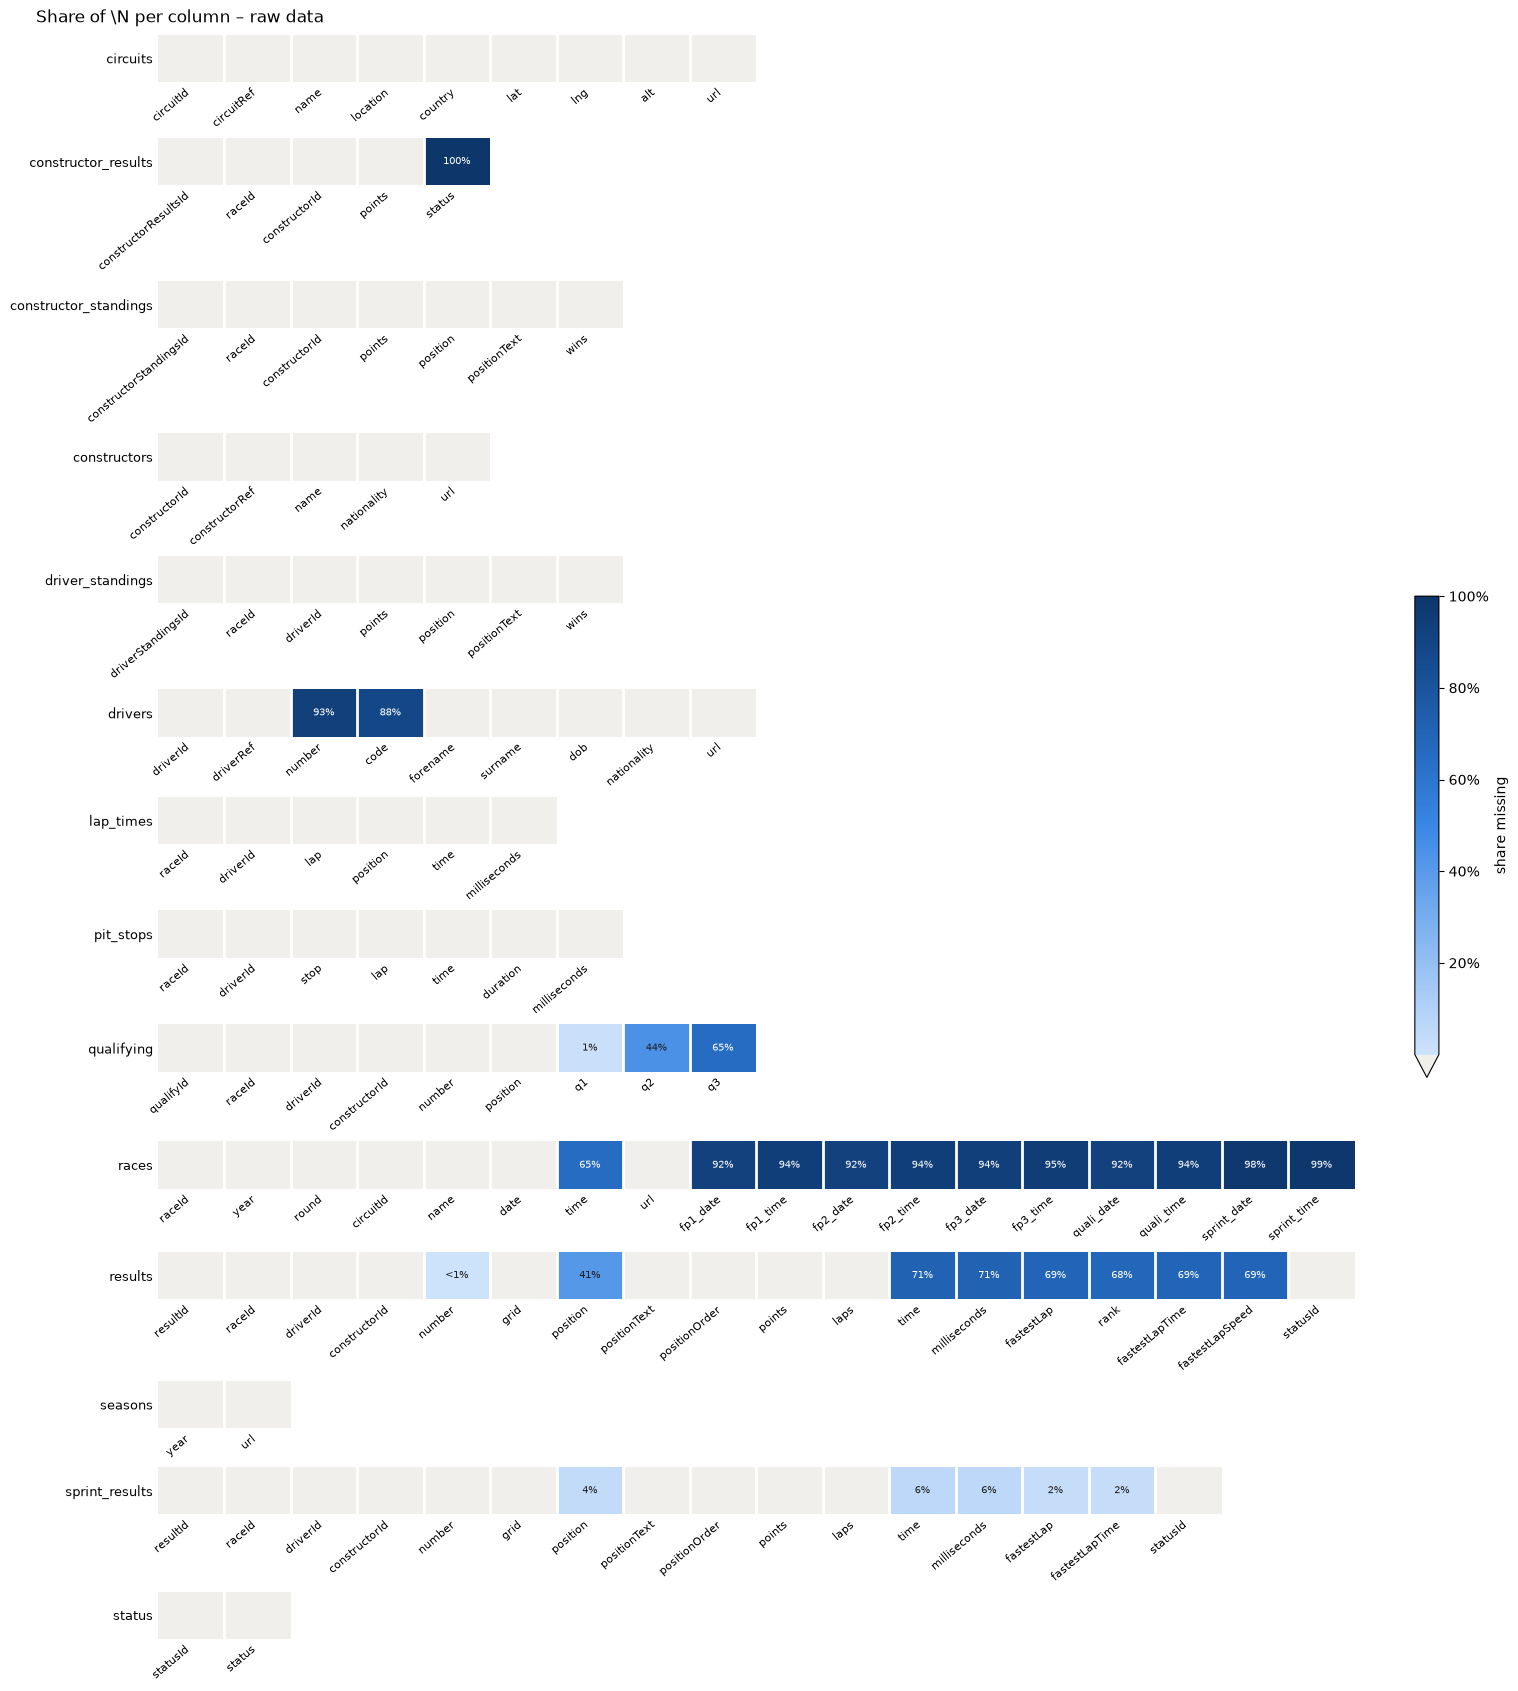

In [7]:
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
NO_MISSING = "#f0efec"
INK = "#1f1f1f"


def plot_missing(tables, title):
    """Heatmap of the share of missing values per column, one row per table."""
    cmap = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)
    cmap.set_under(NO_MISSING)
    width = max(df.shape[1] for df in tables.values())
    fig, axes = plt.subplots(
        len(tables), 1, figsize=(0.7 * width + 2.5, 1.2 * len(tables)), constrained_layout=True
    )
    for ax, (name, df) in zip(axes, tables.items()):
        share = df.isna().mean().to_numpy()
        image = ax.imshow(
            share[None, :],
            cmap=cmap,
            vmin=1e-9,
            vmax=1,
            aspect="auto",
            extent=(-0.5, len(share) - 0.5, 0.5, -0.5),
        )
        ax.set_xlim(-0.5, width - 0.5)
        ax.set_xticks(range(len(share)), df.columns, rotation=40, ha="right", fontsize=8)
        ax.set_yticks([0], [name], fontsize=9)
        ax.set_xticks([i + 0.5 for i in range(len(share) - 1)], minor=True)
        ax.grid(which="minor", axis="x", color="white", linewidth=2)
        ax.tick_params(which="both", length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
        for i, value in enumerate(share):
            if value > 0:
                label = "<1%" if value < 0.01 else f"{value:.0%}"
                ax.text(i, 0, label, ha="center", va="center", fontsize=7,
                        color="white" if value >= 0.45 else INK)
    fig.colorbar(image, ax=axes, extend="min", shrink=0.3, label="share missing",
                 format=lambda v, _: f"{v:.0%}")
    fig.suptitle(title, x=0.02, ha="left", fontsize=12)
    return fig


save_figure(plot_missing(raw, "Share of \\N per column – raw data"), "audit_missing_heatmap_raw");

**Observation (missing values), grouped by cause.** Anything not shown by the data is marked *Assumption*; F1 knowledge from the project brief is marked *Context (project brief)*, each next to the data evidence.

*Structural: the value does not exist for this row:*
- `results.position` (41%): missing exactly for rows with a non-numeric `positionText` (R, F, W, N, D, E), plus 2 rows with `positionText` 11 and 14 but no `position` (an anomaly, not yet explained).
- `qualifying.q2` / `q3` (44% / 65%): almost entirely empty up to 2005, filled for part of the field from 2006 (data evidence). *Context (project brief):* since 2006 qualifying is a knockout with Q1/Q2/Q3; whoever is knocked out early has no later times.
- `qualifying.q1` (1%): single rows scattered across all seasons.
- `races.time` (65%): filled only from 2005, then complete.
- `races.fp*`, `quali_*` (92–95%): filled only from 2021, then complete. `sprint_*` (98–99%): only sprint weekends from 2021.
- `drivers.number` (93%): filled only for drivers whose first race is in 2000 or later. `drivers.code` (88%): filled irregularly.

*From the race itself, off-limits as a feature anyway (Prediction Cutoff):*
- `results.time`, `milliseconds` (71%): only for drivers on the lead lap; 8,131 classified drivers have no time. `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed` (68–69%).
- `sprint_results.position`, `time`, `fastestLap*` (2–6%).

*Completely empty:*
- `constructor_results.status` (100%): carries no information.

*Without `\N`:* all key columns, and in `results` `grid`, `positionOrder`, `points`, `laps`, `statusId`.

### Empty strings

Gaps that are not coded as `\N` and are therefore missing from the heatmap.

In [8]:
def text_columns(df):
    """Columns that are neither numeric nor datetime, i.e. hold text."""
    return [col for col in df.columns
            if not pd.api.types.is_numeric_dtype(df[col]) and not pd.api.types.is_datetime64_any_dtype(df[col])]


def empty_strings(tables):
    """Count of empty or whitespace-only strings per text column."""
    rows = [
        {"table": name, "column": col, "empty_strings": int((df[col].astype(str).str.strip() == "").sum())}
        for name, df in tables.items()
        for col in text_columns(df)
    ]
    out = pd.DataFrame(rows)
    return out[out.empty_strings > 0].reset_index(drop=True)


empty_strings(raw)

,table,column,empty_strings
0,qualifying,q2,22
1,qualifying,q3,46


**Observation:** only `qualifying.q2` (22) and `qualifying.q3` (46) contain empty strings: extra gaps besides `\N` that would have silently become NaN with the pandas defaults. All other text columns are free of them.

### Foreign-key check

Per foreign key: `orphan_rows` = rows whose value is missing from the referenced table
(violates the reference). `parent_keys_unused` = keys of the referenced table that never
occur in this table (no violation; shows coverage, e.g. races without qualifying rows).

In [9]:
def fk_audit(tables, keys):
    """Orphan rows and unused parent keys per foreign key."""
    rows = []
    for name, spec in keys.items():
        for col, (parent, parent_col) in spec["fk"].items():
            values = tables[name][col]
            parent_keys = tables[parent][parent_col]
            orphan = values.notna() & ~values.isin(parent_keys)
            rows.append(
                {
                    "table": name,
                    "column": col,
                    "references": f"{parent}.{parent_col}",
                    "nulls": int(values.isna().sum()),
                    "orphan_rows": int(orphan.sum()),
                    "orphan_keys": int(values[orphan].nunique()),
                    "parent_keys": int(parent_keys.nunique()),
                    "parent_keys_unused": int((~parent_keys.isin(values)).sum()),
                }
            )
    return pd.DataFrame(rows).set_index(["table", "column"])


fk_audit(raw, KEYS)

references  nulls  \
table                 column                                             
constructor_results   raceId                       races.raceId      0   
                      constructorId  constructors.constructorId      0   
constructor_standings raceId                       races.raceId      0   
                      constructorId  constructors.constructorId      0   
driver_standings      raceId                       races.raceId      0   
                      driverId                 drivers.driverId      0   
lap_times             raceId                       races.raceId      0   
                      driverId                 drivers.driverId      0   
pit_stops             raceId                       races.raceId      0   
                      driverId                 drivers.driverId      0   
qualifying            raceId                       races.raceId      0   
                      driverId                 drivers.driverId      0   
                      constructorId  constructors.constructorId      0   
races                 year                         seasons.year      0   
                      circuitId              circuits.circuitId      0   
results               raceId                       races.raceId      0   
                      driverId                 drivers.driverId      0   
                      constructorId  constructors.constructorId      0   
                      statusId                  status.statusId      0   
sprint_results        raceId                       races.raceId      0   
                      driverId                 drivers.driverId      0   
                      constructorId  constructors.constructorId      0   
                      statusId                  status.statusId      0   

                                     orphan_rows  orphan_keys  parent_keys  \
table                 column                                                 
constructor_results   raceId                   0            0         1125   
                      constructorId            0            0          212   
constructor_standings raceId                   0            0         1125   
                      constructorId            0            0          212   
driver_standings      raceId                   0            0         1125   
                      driverId                 0            0          861   
lap_times             raceId                   0            0         1125   
                      driverId                 0            0          861   
pit_stops             raceId                   0            0         1125   
                      driverId                 0            0          861   
qualifying            raceId                   0            0         1125   
                      driverId                 0            0          861   
                      constructorId            0            0          212   
races                 year                     0            0           75   
                      circuitId                0            0           77   
results               raceId                   0            0         1125   
                      driverId                 0            0          861   
                      constructorId            0            0          212   
                      statusId                 0            0          139   
sprint_results        raceId                   0            0         1125   
                      driverId                 0            0          861   
                      constructorId            0            0          212   
                      statusId                 0            0          139   

                                     parent_keys_unused  
table                 column                             
constructor_results   raceId                         65  
                      constructorId                  37  
constructor_standin

**Observation (foreign keys):**
- **Result: no orphan row and no missing foreign key. No row has to be removed for integrity reasons.**
- `results` covers all 1,125 races and all 861 drivers.
- Coverage of the side tables (races with at least one row, of 1,125): `qualifying` 494, `lap_times` 544, `pit_stops` 285, `sprint_results` 18, `constructor_standings` 1,061, `constructor_results` 1,060, `driver_standings` 1,125.
- The qualifying gap (631 races without a row) matters for the split and the Training Window (ADR 0001); section 1 shows how it spreads over the seasons.

### Unused parent keys

Which keys exactly are behind the small numbers in `parent_keys_unused`.

In [10]:
def unused_parent_keys(tables, child, column, parent, parent_column):
    """Rows of the parent table whose key never occurs in the child table."""
    parent_df = tables[parent]
    return parent_df[~parent_df[parent_column].isin(tables[child][column])]


unused_parent_keys(raw, "results", "constructorId", "constructors", "constructorId")[
    ["constructorId", "constructorRef", "name"]
]

,constructorId,constructorRef,name
86,88,eagle,Eagle


In [11]:
unused_parent_keys(raw, "results", "statusId", "status", "statusId")

,statusId,status
130,133,+49 Laps
131,134,+38 Laps


In [12]:
drivers_without_standings = unused_parent_keys(raw, "driver_standings", "driverId", "drivers", "driverId")
(
    raw["results"][raw["results"].driverId.isin(drivers_without_standings.driverId)]
    .merge(raw["races"][["raceId", "year", "name"]], on="raceId")
    .merge(raw["status"], on="statusId")
    .merge(raw["drivers"][["driverId", "driverRef"]], on="driverId")
    .groupby(["driverRef"])
    .agg(entries=("raceId", "size"), seasons=("year", lambda y: sorted(set(y))), points=("points", "sum"),
         statuses=("status", lambda s: s.value_counts().to_dict()))
)

,entries,seasons,points,statuses
driverRef,,,,
amati,3,[1992],0.0,{'Did not qualify': 3}
apicella,1,[1993],0.0,{'Collision': 1}
chiesa,10,[1992],0.0,"{'Did not qualify': 7, 'Spun off': 2, 'Acciden..."
markus_winkelhock,1,[2007],0.0,{'Hydraulics': 1}
mccarthy,7,[1992],0.0,"{'Did not prequalify': 5, 'Excluded': 1, 'Did ..."
sarrazin,1,[1999],0.0,{'Spun off': 1}
sospiri,1,[1997],0.0,{'Did not qualify': 1}


In [13]:
races_without = {
    table: set(unused_parent_keys(raw, table, "raceId", "races", "raceId").raceId)
    for table in ["constructor_standings", "constructor_results"]
}
seasons_1950_1957 = set(raw["races"].query("year <= 1957").raceId)
print("without constructor_standings == all races 1950–1957:",
      races_without["constructor_standings"] == seasons_1950_1957)
raw["races"][raw["races"].raceId.isin(races_without["constructor_results"] - races_without["constructor_standings"])][
    ["raceId", "year", "round", "name"]
]

without constructor_standings == all races 1950–1957: True


,raceId,year,round,name
767,768,1958,4,Indianapolis 500


**Observation (unused parent keys):**
- Constructor `eagle` (ID 88) occurs in no table except `constructors`.
- The statuses `+49 Laps` and `+38 Laps` are never used.
- The 7 drivers without a `driver_standings` row have 24 Entries in total (1992–2007), all without points; many of them are "Did not qualify" / "Did not prequalify". *Assumption:* standings only contain drivers who took part in at least one race of the season; to be checked if standings are used as a feature.
- The 64 races without `constructor_standings` are **exactly all races 1950–1957** (data evidence: the check above returns `True`). *Context (project brief):* the constructors' championship only exists since 1958.
- `constructor_results` is also missing for the **1958 Indianapolis 500** (raceId 768), hence 65 instead of 64.

### Other placeholders (not `\N`)

Values that look present but could be placeholders: 0, negative or implausible.

In [14]:
def value_profile(tables, columns):
    """Figures per column: value range, zeros, negative and missing values."""
    rows = []
    for table, col in columns:
        values = tables[table][col]
        rows.append({"column": f"{table}.{col}", "min": values.min(), "max": values.max(),
                     "zeros": int((values == 0).sum()), "negative": int((values < 0).sum()),
                     "missing": int(values.isna().sum()), "rows": len(values)})
    return pd.DataFrame(rows).set_index("column")


value_profile(raw, [("results", "grid"), ("results", "number"), ("qualifying", "position"),
                    ("qualifying", "number"), ("circuits", "alt")])

,min,max,zeros,negative,missing,rows
column,,,,,,
results.grid,0.0,34.0,1638,0,0,26759
results.number,0.0,208.0,34,0,6,26759
qualifying.position,1.0,28.0,0,0,0,10494
qualifying.number,0.0,99.0,15,0,0,10494
circuits.alt,-7.0,2227.0,2,1,0,77


In [15]:
def zero_rows_by_season(tables, table, column):
    """Seasons of the rows in which `column` is 0."""
    df = tables[table].merge(tables["races"][["raceId", "year"]], on="raceId")
    return df[df[column] == 0].groupby("year").size().rename(f"{table}.{column} == 0")


pd.concat([zero_rows_by_season(raw, "results", "number"), zero_rows_by_season(raw, "qualifying", "number")],
          axis=1).fillna(0).astype(int)

,results.number == 0,qualifying.number == 0
year,,
1973,2,0
1993,16,0
1994,16,15


In [16]:
raw["circuits"].query("alt <= 0")[["circuitRef", "name", "country", "alt"]]

,circuitRef,name,country,alt
34,yeongam,Korean International Circuit,Korea,0
71,baku,Baku City Circuit,Azerbaijan,-7
76,miami,Miami International Autodrome,USA,0


**Observation (placeholders):**
- `results.grid`: 0 to 34, **1,638 zeros**, no negative or missing values. The meaning of `grid == 0` is deliberately not interpreted here; section 3 decides it.
- `results.number`: 34 zeros (2 in 1973, 16 each in 1993 and 1994) and 6 missing values (1961–1963). `qualifying.number`: 15 zeros, all in 1994. *Assumption:* a real car number 0 (in 1993/94 there was a car with number 0), not a placeholder.
- `qualifying.position`: 1 to 28, no zeros or gaps.
- `circuits.alt`: two circuits at 0 m (Korea, Miami), one at −7 m (Baku). *Assumption:* plausible values (coast, Caspian Sea), not placeholders.

### `grid == 0` breakdown

For inspection only, no decision (decided in section 3): which of the 1,638 rows look like non-Starters, which like Pit-Lane Starts? Split by status text and `laps == 0` / `laps > 0`, and by decade.

In [17]:
def grid_zero_rows(tables):
    """Results rows with grid == 0, with season, status text and lap class."""
    rows = (
        tables["results"].query("grid == 0")
        .merge(tables["races"][["raceId", "year"]], on="raceId")
        .merge(tables["status"], on="statusId")
    )
    return rows.assign(laps_class=rows.laps.gt(0).map({True: "laps > 0", False: "laps == 0"}),
                       decade=rows.year // 10 * 10)


grid_zero = grid_zero_rows(raw)
pd.crosstab(grid_zero.status, grid_zero.laps_class, margins=True).sort_values("All", ascending=False)

laps_class,laps == 0,laps > 0,All
status,,,
All,1566,72,1638
Did not qualify,1013,0,1013
Did not prequalify,331,0,331
Withdrew,164,0,164
+1 Lap,0,27,27
Finished,0,22,22
Accident,18,2,20
Injury,8,0,8
+2 Laps,0,7,7


In [18]:
pd.crosstab(grid_zero.decade, grid_zero.laps_class, margins=True)

laps_class,laps == 0,laps > 0,All
decade,,,
1950,68,0,68
1960,198,0,198
1970,351,0,351
1980,571,0,571
1990,357,0,357
2000,8,0,8
2010,9,19,28
2020,4,53,57
All,1566,72,1638


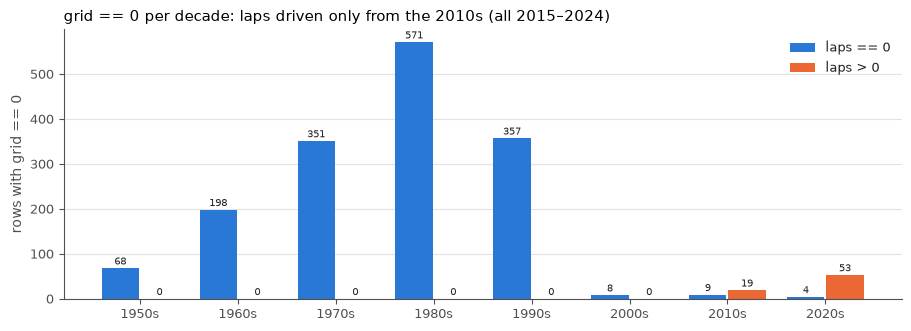

In [19]:
def plot_grid_zero_by_decade(rows, title):
    """grid == 0 rows per decade, split by laps == 0 / laps > 0."""
    table = pd.crosstab(rows.decade, rows.laps_class).reindex(columns=["laps == 0", "laps > 0"], fill_value=0)
    fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
    x = np.arange(len(table))
    for offset, column, color in [(-0.2, "laps == 0", BLUE), (0.2, "laps > 0", ORANGE)]:
        bars = ax.bar(x + offset, table[column], width=0.38, color=color, label=column)
        ax.bar_label(bars, fontsize=7, color=INK, padding=1)
    ax.set_xticks(x, [f"{d}s" for d in table.index])
    style_axes(ax)
    ax.set_ylabel("rows with grid == 0", color=MUTED)
    ax.legend(frameon=False, fontsize=9, labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_grid_zero_by_decade(grid_zero, "grid == 0 per decade: laps driven only from the 2010s (all 2015–2024)"),
            "audit_grid_zero_by_decade");

**Observation (`grid == 0`):**
- 1,566 rows have `laps == 0`, across all decades. Of these, 1,508 carry a status that looks like a non-start: "Did not qualify" (1,013), "Did not prequalify" (331), "Withdrew" (164).
- The other 58 `laps == 0` rows have other statuses (e.g. Accident 18, Injury 8, Disqualified 6, Engine 6, Excluded 6); whether non-start or retirement before the first lap is open.
- 72 rows have `laps > 0`, **all 2015–2024**, mostly "+n Lap" and "Finished". These drivers did race; the pattern fits Pit-Lane Starts.
- Up to 2014 there is not a single `grid == 0` row with `laps > 0`.

### Qualifying ↔ results check

Per `(raceId, driverId)`: does every qualifying row have a results row, and does the constructor match?

In [20]:
def qualifying_vs_results(tables):
    """Qualifying rows without a results row, and constructor mismatches."""
    merged = tables["qualifying"].merge(tables["results"], on=["raceId", "driverId"], how="left",
                                        suffixes=("_quali", "_result"), indicator=True)
    matched = merged[merged._merge == "both"]
    mismatch = matched[matched.constructorId_quali != matched.constructorId_result]
    print("qualifying rows:", len(tables["qualifying"]),
          "| without results row:", int((merged._merge == "left_only").sum()),
          "| constructor differs:", len(mismatch))
    names = tables["constructors"].set_index("constructorId").name
    return (mismatch.merge(tables["races"][["raceId", "year", "name"]], on="raceId")
            .assign(quali_constructor=lambda d: d.constructorId_quali.map(names),
                    result_constructor=lambda d: d.constructorId_result.map(names))
            [["year", "name", "driverId", "quali_constructor", "result_constructor"]])


qualifying_vs_results(raw)

qualifying rows: 10494 | without results row: 0 | constructor differs: 10


,year,name,driverId,quali_constructor,result_constructor
0,2015,Belgian Grand Prix,829,Marussia,Manor Marussia
1,2015,Belgian Grand Prix,833,Marussia,Manor Marussia
2,2015,Russian Grand Prix,829,Marussia,Manor Marussia
3,2015,Russian Grand Prix,833,Marussia,Manor Marussia
4,2015,United States Grand Prix,834,Marussia,Manor Marussia
5,2015,United States Grand Prix,829,Marussia,Manor Marussia
6,2015,Mexican Grand Prix,834,Marussia,Manor Marussia
7,2015,Mexican Grand Prix,829,Marussia,Manor Marussia
8,2015,Brazilian Grand Prix,834,Marussia,Manor Marussia
9,2015,Brazilian Grand Prix,829,Marussia,Manor Marussia


**Observation:** every one of the 10,494 qualifying rows has a results row. The constructor differs in 10 rows, all in 2015 (five races from Belgium on): qualifying says "Marussia", results says "Manor Marussia". *Assumption:* the same team under a new name, maintained differently in the two tables. Conversely, in races with qualifying data 59 results rows have no qualifying row (handled in section 2; section 1 shows them per season).

### Seasons of the duplicate groups

The 85 `(raceId, driverId)` groups with more than one row in `results` (decided in section 4), counted per season.

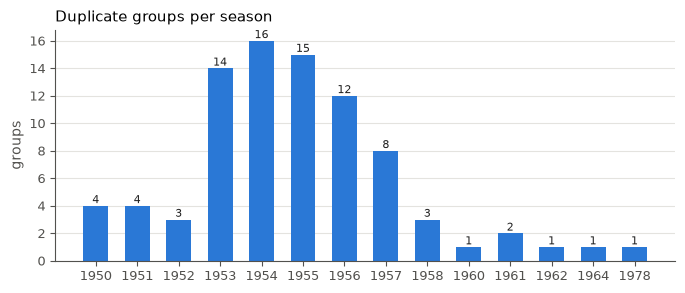

In [21]:
def duplicate_groups_by_season(tables):
    """Number of (raceId, driverId) groups with more than one row, per season."""
    results = tables["results"].merge(tables["races"][["raceId", "year"]], on="raceId")
    groups = results[results.duplicated(["raceId", "driverId"], keep=False)].drop_duplicates(["raceId", "driverId"])
    return groups.groupby("year").size().rename("duplicate_groups")


dup_seasons = duplicate_groups_by_season(raw)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(dup_seasons.index.astype(str), dup_seasons.values, color=BLUE, width=0.6)
ax.bar_label(ax.containers[0], fontsize=8, color=INK)
style_axes(ax)
ax.set_ylabel("groups", color=MUTED)
ax.set_title("Duplicate groups per season", loc="left", fontsize=11);

**Observation:** 79 of the 85 groups fall in 1950–1958, concentrated in 1953–1956 (12–16 per season). After that only single cases (1960, 1961, 1962, 1964, 1978).

<a id="sec-0"></a>
## 0. Base table

All EDA sections work on the same table: `results` plus season and race from `races`,
status text from `status`, and a few flags. One row per results row, so **not yet** one
per Entry, because 85 Entries have several rows. Nothing is removed or recoded,
nothing is written to `data/clean/`.

Flags:
- `has_qualifying_row`: there is a qualifying row for this `(raceId, driverId)`
- `race_has_qualifying`: the race has any qualifying rows at all
- `grid_zero`: `grid == 0` (meaning decided in section 3)
- `podium_row`: `positionOrder <= 3`
- `duplicate_group`: the row belongs to a `(raceId, driverId)` group with more than one row
- `indy_500`: the race is called "Indianapolis 500"
- `did_not_start_status`: status in `DID_NOT_START`; for exploration only, since the status is only known after the race (section 2)

In [22]:
KEY = ["raceId", "driverId"]
DID_NOT_START = ["Did not qualify", "Did not prequalify", "Withdrew", "107% Rule"]


def build_base_table(tables):
    """results + season/race + status text + flags; one row per results row."""
    races = tables["races"][["raceId", "year", "round", "name", "date"]].rename(columns={"name": "race_name"})
    base = (
        tables["results"]
        .merge(races, on="raceId", how="left", validate="many_to_one")
        .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
    )
    entry_key = pd.MultiIndex.from_frame(base[["raceId", "driverId"]])
    quali_key = pd.MultiIndex.from_frame(tables["qualifying"][["raceId", "driverId"]])
    return base.assign(
        has_qualifying_row=entry_key.isin(quali_key),
        race_has_qualifying=base.raceId.isin(tables["qualifying"].raceId),
        grid_zero=base.grid.eq(0),
        podium_row=base.positionOrder.le(3),
        duplicate_group=base.duplicated(["raceId", "driverId"], keep=False),
        indy_500=base.race_name.eq("Indianapolis 500"),
        did_not_start_status=base.status.isin(DID_NOT_START),
    )


base = build_base_table(raw)

assert len(base) == len(raw["results"]), "Joins must neither create nor lose rows"
assert base[["year", "status"]].notna().all().all(), "Every row has a season and a status text"
assert base[base.duplicate_group].groupby(["raceId", "driverId"]).ngroups == 85

FLAGS = [
    "has_qualifying_row", "race_has_qualifying", "grid_zero", "podium_row", "duplicate_group", "indy_500",
    "did_not_start_status",
]
base[FLAGS].sum().rename("rows").to_frame().assign(share=lambda d: (d.rows / len(base)).round(3))

,rows,share
has_qualifying_row,10494,0.392
race_has_qualifying,10553,0.394
grid_zero,1638,0.061
podium_row,3397,0.127
duplicate_group,176,0.007
indy_500,405,0.015
did_not_start_status,1613,0.060


In [23]:
base.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,race_name,date,status,has_qualifying_row,race_has_qualifying,grid_zero,podium_row,duplicate_group,indy_500,did_not_start_status
0,1,18,1,1,22.0,1,1.0,1,1,10.0,...,Australian Grand Prix,2008-03-16,Finished,True,True,False,True,False,False,False
1,2,18,2,2,3.0,5,2.0,2,2,8.0,...,Australian Grand Prix,2008-03-16,Finished,True,True,False,True,False,False,False
2,3,18,3,3,7.0,7,3.0,3,3,6.0,...,Australian Grand Prix,2008-03-16,Finished,True,True,False,True,False,False,False
3,4,18,4,4,5.0,11,4.0,4,4,5.0,...,Australian Grand Prix,2008-03-16,Finished,True,True,False,False,False,False,False
4,5,18,5,1,23.0,3,5.0,5,5,4.0,...,Australian Grand Prix,2008-03-16,Finished,True,True,False,False,False,False,False


**Observation:** 26,759 rows, as in `results`; each has a season and a status text. 10,494 rows (39%) have a qualifying row, 10,553 are in races with qualifying data; the difference of 59 are results rows without a qualifying row in such races. 3,397 podium rows, 1,638 rows with `grid == 0`, 405 rows from the Indianapolis 500, 176 rows in duplicate groups, 1,613 rows with a did-not-start status.

<a id="sec-1"></a>
## 1. Seasons

Per season: races, rows, Entries, podium rows and qualifying coverage. Basis for the split and
the Training Window (ADR 0001). All figures refer to the raw data; they change once
Entries vs. Starters, `grid == 0`, duplicates and the Indy 500 are decided (sections 2–6).

- `entries`: distinct `(raceId, driverId)` keys; `rows` counts duplicate groups with all their rows.
- `podium_rows`: rows with `positionOrder <= 3` (counted per row for duplicates).
- `podium_share`: `podium_rows / rows`, the base rate of the target.

In [24]:
def season_summary(base, tables):
    """Figures per season from the base table."""
    entries = base.drop_duplicates(["raceId", "driverId"])
    by_year = base.groupby("year")
    summary = pd.DataFrame(
        {
            "races": tables["races"].groupby("year").size(),
            "races_with_qualifying": base[base.race_has_qualifying].groupby("year").raceId.nunique(),
            "rows": by_year.size(),
            "entries": entries.groupby("year").size(),
            "entries_with_qualifying": entries.groupby("year").has_qualifying_row.sum(),
            "podium_rows": by_year.podium_row.sum(),
        }
    ).fillna(0).astype(int)
    return summary.assign(
        entries_per_race=lambda d: (d.entries / d.races).round(1),
        share_races_with_qualifying=lambda d: (d.races_with_qualifying / d.races).round(3),
        share_entries_with_qualifying=lambda d: (d.entries_with_qualifying / d.entries).round(3),
        podium_share=lambda d: (d.podium_rows / d.rows).round(3),
    )


seasons = season_summary(base, raw)
# the plot below shows every season; the table shows the seasons cited in the text and the 1988–2004 transition
display(seasons.loc[[1951, 1969] + list(range(1988, 2005))])

,races,races_with_qualifying,rows,entries,entries_with_qualifying,podium_rows,entries_per_race,share_races_with_qualifying,share_entries_with_qualifying,podium_share
year,,,,,,,,,,
1951,8,0,179,175,0,28,21.9,0.000,0.000,0.156
1969,11,0,177,177,0,33,16.1,0.000,0.000,0.186
1988,16,0,495,495,0,48,30.9,0.000,0.000,0.097
1989,16,0,620,620,0,48,38.8,0.000,0.000,0.077
1990,16,0,542,542,0,48,33.9,0.000,0.000,0.089
1991,16,0,539,539,0,48,33.7,0.000,0.000,0.089
1992,16,0,478,478,0,48,29.9,0.000,0.000,0.100
1993,16,0,412,412,0,48,25.8,0.000,0.000,0.117
1994,16,15,444,444,392,48,27.8,0.938,0.883,0.108


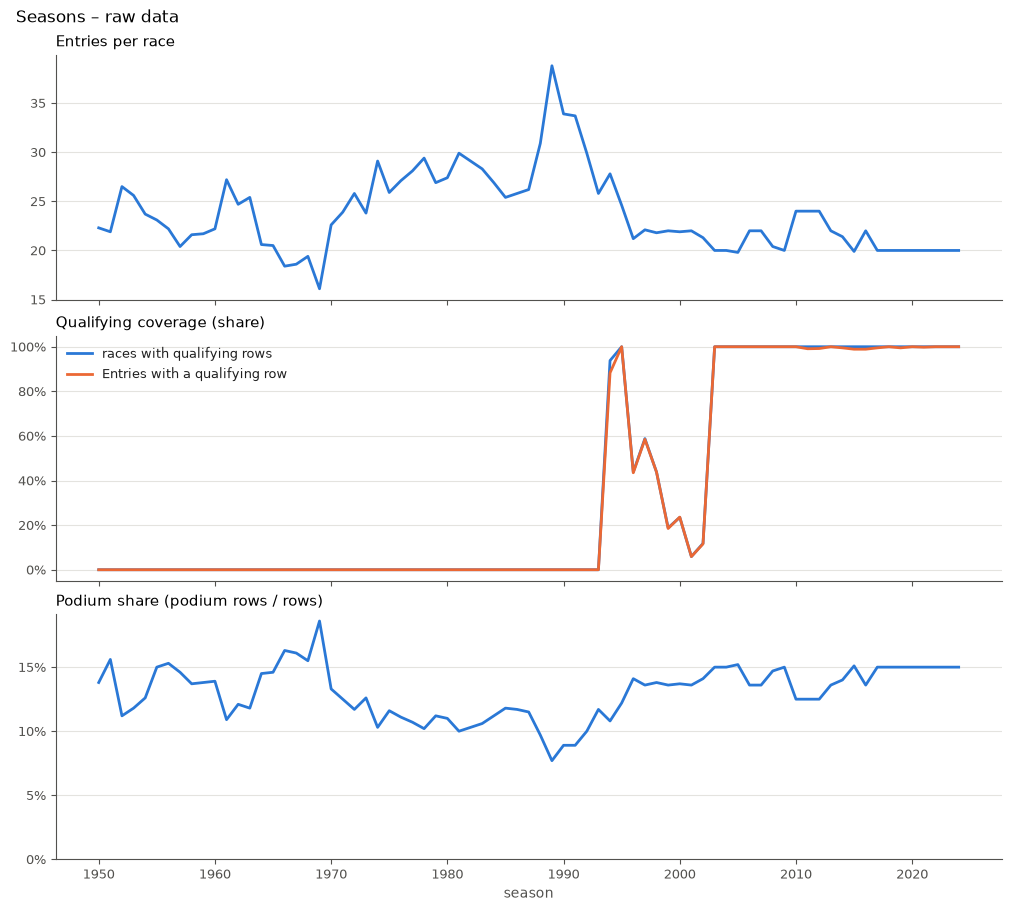

In [25]:
def plot_seasons(seasons, title):
    """Field size, qualifying coverage and podium share per season, stacked."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)
    years = seasons.index

    axes[0].plot(years, seasons.entries_per_race, color=BLUE, linewidth=2)
    axes[0].set_title("Entries per race", loc="left", fontsize=11)

    axes[1].plot(years, seasons.share_races_with_qualifying, color=BLUE, linewidth=2,
                 label="races with qualifying rows")
    axes[1].plot(years, seasons.share_entries_with_qualifying, color=ORANGE, linewidth=2,
                 label="Entries with a qualifying row")
    axes[1].set_title("Qualifying coverage (share)", loc="left", fontsize=11)
    axes[1].legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK)
    axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

    axes[2].plot(years, seasons.podium_share, color=BLUE, linewidth=2)
    axes[2].set_title("Podium share (podium rows / rows)", loc="left", fontsize=11)
    axes[2].yaxis.set_major_locator(MultipleLocator(0.05))
    axes[2].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    axes[2].set_ylim(bottom=0)

    for ax in axes:
        style_axes(ax)
    axes[2].set_xlabel("season", color=MUTED)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return fig


plot_seasons(seasons, "Seasons – raw data");

**Observation (seasons):**
- **Field size:** mostly 20–30 Entries per race; peak 1989–1991 with 34–39 (these seasons also have the most non-Starters, see section 2). Constant 20 since 2017; once 19 in 2024 (Australia).
- **Qualifying coverage:** zero up to 1993. 1994 and 1995 nearly and fully complete, 1996–2002 patchy (6–59% of races), all races from 2003. The 59 results rows without a qualifying row in races with qualifying data are spread over 1994 (26), 1996–1999 (9) and 2011–2021 (24, 1–5 per season); most frequent statuses: "Did not qualify" (28), "107% Rule" (6), but also 5 × "Finished".
- **Podium share:** varies with field size, between 8% (1989) and 19% (1969); constant 15% (3 of 20) since 2017. Large fields lower the base rate.
- `podium_rows` is exactly 3 × races in most seasons. Deviations occur mainly in the 1950s (e.g. 1951: 28 instead of 24); section 5 explains them per race.

### 2024 Australia: 19 instead of 20 Entries

Check of the explanation "Williams entered only one car": rows per team in this race, and whether the season's second Williams driver has a results or qualifying row.

In [26]:
def entries_per_constructor(tables, race_id):
    """Rows per constructor in one race."""
    names = tables["constructors"].set_index("constructorId").name
    return tables["results"].query("raceId == @race_id").constructorId.map(names).value_counts()


AUSTRALIA_2024 = raw["races"].query("year == 2024 and name == 'Australian Grand Prix'").raceId.item()
print(entries_per_constructor(raw, AUSTRALIA_2024).to_dict())

drivers = raw["drivers"].set_index("driverId").driverRef
williams = raw["constructors"].query("name == 'Williams'").constructorId.item()
williams_2024 = base.query("year == 2024 and constructorId == @williams")
print("Williams drivers 2024 (races):", williams_2024.driverId.map(drivers).value_counts().to_dict())
for table in ["results", "qualifying"]:
    in_race = raw[table].query("raceId == @AUSTRALIA_2024").driverId.map(drivers)
    print(f"{table}: Williams drivers 2024 with a row in Australia:",
          sorted(set(williams_2024.driverId.map(drivers)) & set(in_race)))

{'Ferrari': 2, 'McLaren': 2, 'Red Bull': 2, 'Aston Martin': 2, 'RB F1 Team': 2, 'Haas F1 Team': 2, 'Alpine F1 Team': 2, 'Sauber': 2, 'Mercedes': 2, 'Williams': 1}
Williams drivers 2024 (races): {'albon': 24, 'sargeant': 14, 'colapinto': 9}
results: Williams drivers 2024 with a row in Australia: ['albon']
qualifying: Williams drivers 2024 with a row in Australia: ['albon']


**Observation:** every team has two rows, Williams one (Albon). Sargeant drives 14 other races for Williams in 2024 but has neither a results nor a qualifying row in Australia. The data supports the explanation: Williams entered only one car in this race. No effect on the target.

### Split candidates

Entries and podium rows per part for every combination of training start
(1950 / 1994 / 2003) and validation window (2020–2021 / 2019–2021); test always from
2022. Counts only, no decision.

In [27]:
def split_candidates(seasons, train_starts, validation_windows, test_start):
    """Entries and podium rows per part for every split variant."""
    rows = []
    for train_start in train_starts:
        for val_start, val_end in validation_windows:
            parts = {
                "train": (train_start, val_start - 1),
                "validation": (val_start, val_end),
                "test": (test_start, seasons.index.max()),
            }
            row = {"train_start": train_start, "validation": f"{val_start}–{val_end}"}
            for part, (start, end) in parts.items():
                window = seasons.loc[start:end]
                row[f"{part}_entries"] = window.entries.sum()
                row[f"{part}_podium_rows"] = window.podium_rows.sum()
            rows.append(row)
    return pd.DataFrame(rows).set_index(["train_start", "validation"])


split_candidates(seasons, train_starts=[1950, 1994, 2003], validation_windows=[(2020, 2021), (2019, 2021)],
                 test_start=2022)

train_entries  train_podium_rows  validation_entries  \
train_start validation                                                         
1950        2020–2021           24529               3076                 780   
            2019–2021           24109               3013                1200   
1994        2020–2021           10219               1410                 780   
            2019–2021            9799               1347                1200   
2003        2020–2021            6831                963                 780   
            2019–2021            6411                900                1200   

                        validation_podium_rows  test_entries  test_podium_rows  
train_start validation                                                          
1950        2020–2021                      117          1359               204  
            2019–2021                      180          1359               204  
1994        2020–2021                      117          1359               204  
            2019–2021                      180          1359               204  
2003        2020–2021                      117          1359               204  
            2019–2021                      180          1359               204

**Observation (split candidates):**
- Test from 2022: 1,359 Entries, 204 podium rows.
- Validation 2020–2021: 780 Entries / 117 podiums; 2019–2021: 1,200 / 180.
- Training from 1950: about 24,100–24,500 Entries; from 1994: about 9,800–10,200; from 2003: about 6,400–6,800. From 2003 every training row would have qualifying data; from 1994, 1996–2002 would be patchy.
- All figures are raw counts before the decisions of sections 2–6 and only serve to compare the variants.

<a id="sec-2"></a>
## 2. Status and non-Starters

Status and laps are only known after the race. Here they serve only as a **reference**,
to check whether non-Starters can be recognised from fields already known at the
Prediction Cutoff.

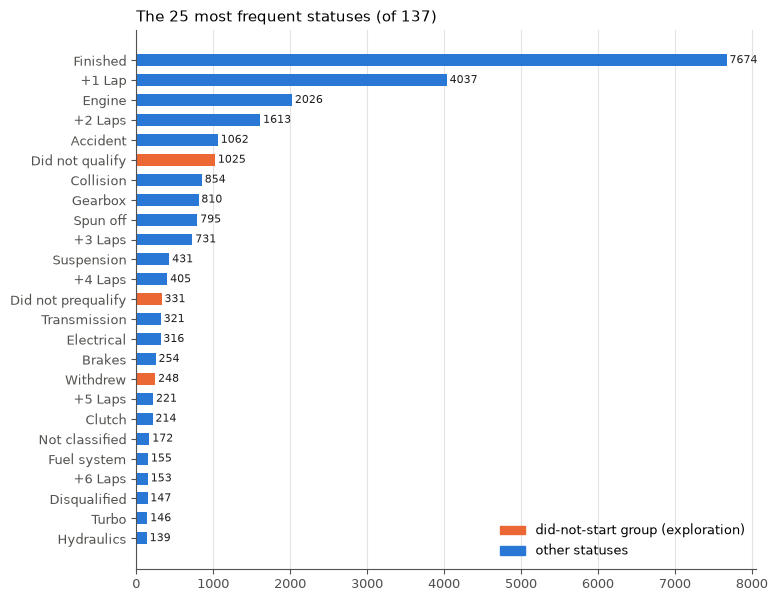

In [28]:
def top_statuses(base, n):
    """The n most frequent status texts with counts."""
    return base.status.value_counts().head(n)


top = top_statuses(base, 25)
colors = [ORANGE if status in DID_NOT_START else BLUE for status in top.index]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1], height=0.6)
ax.bar_label(ax.containers[0], fontsize=8, color=INK, padding=2)
style_axes(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=["did-not-start group (exploration)", "other statuses"], frameon=False, fontsize=9, loc="lower right")
ax.set_title(f"The 25 most frequent statuses (of {base.status.nunique()})", loc="left", fontsize=11);

**Did-not-start group (exploration only):** "Did not qualify", "Did not prequalify",
"Withdrew" and "107% Rule" (qualifying time outside 107% of the fastest time). Not
included: "Not classified" (started, too little distance) and "Disqualified" (137 of 147
rows with `laps > 0`, so mostly raced). Rare statuses such as "Injury", "Safety concerns"
or "Driver unwell" are also left out; they mix Starters and non-Starters.

Check: how many rows of the group still have `laps > 0`?

In [29]:
pd.crosstab(base[base.did_not_start_status].status, base[base.did_not_start_status].laps.gt(0).rename("laps > 0"),
            margins=True)

laps > 0,False,True,All
status,,,
107% Rule,9,0,9
Did not prequalify,331,0,331
Did not qualify,1024,1,1025
Withdrew,225,23,248
All,1589,24,1613


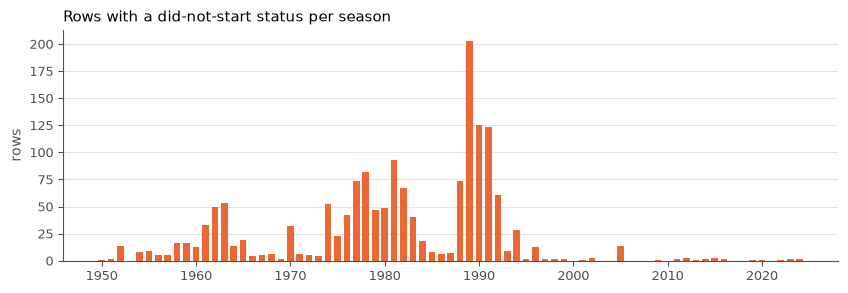

In [30]:
dns_by_season = base[base.did_not_start_status].groupby("year").size().reindex(seasons.index, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(dns_by_season.index, dns_by_season.values, color=ORANGE, width=0.7)
style_axes(ax)
ax.set_ylabel("rows", color=MUTED)
ax.set_title("Rows with a did-not-start status per season", loc="left", fontsize=11);

In [31]:
print("did-not-start status with a podium row:", int((base.did_not_start_status & base.podium_row).sum()))
assert not (base.did_not_start_status & base.podium_row).any(), "No non-Starter may be on the podium"

did-not-start status with a podium row: 0


### Can non-Starters be recognised before the race?

Three candidate rules from fields known at the Prediction Cutoff; each says "Starter" or
"non-Starter":
- **R1** `grid > 0`
- **R2** qualifying row present
- **R3** `grid > 0` or qualifying row present

The reference is the did-not-start group from the status. Split by eras that follow from
section 1 and the audit: no qualifying data up to 1993, patchy 1994–2002, complete from
2003, and from 2015 `grid == 0` occurs with laps driven (Pit-Lane Starts; audit,
"`grid == 0` breakdown").

In [32]:
ERAS = {"1950–1993": (1950, 1993), "1994–2002": (1994, 2002), "2003–2014": (2003, 2014), "2015–2024": (2015, 2024)}


def era_of(years):
    """Era per season according to ERAS."""
    bins = [start - 1 for start, _ in ERAS.values()] + [max(end for _, end in ERAS.values())]
    return pd.cut(years, bins=bins, labels=list(ERAS))


def rule_confusion(base, rules, reference):
    """Per era and rule: non-Starters detected/missed, Starters correct/wrongly excluded."""
    eras = era_of(base.year)
    rows = []
    for rule_name, predicted_starter in rules.items():
        for era in ERAS:
            in_era = eras == era
            ref, pred = reference[in_era], predicted_starter[in_era]
            rows.append({"era": era, "rule": rule_name,
                         "non_starters_detected": int((ref & ~pred).sum()),
                         "non_starters_missed": int((ref & pred).sum()),
                         "starters_wrongly_excluded": int((~ref & ~pred).sum()),
                         "starters_correct": int((~ref & pred).sum())})
    return pd.DataFrame(rows).set_index(["era", "rule"])


RULES = {
    "R1 grid > 0": base.grid.gt(0),
    "R2 qualifying row": base.has_qualifying_row,
    "R3 grid > 0 or qualifying row": base.grid.gt(0) | base.has_qualifying_row,
}
confusion = rule_confusion(base, RULES, base.did_not_start_status)
confusion

,,non_starters_detected,non_starters_missed,starters_wrongly_excluded,starters_correct
era,rule,,,,
1950–1993,R1 grid > 0,1467,58,41,12835
1994–2002,R1 grid > 0,34,19,10,3325
2003–2014,R1 grid > 0,6,17,1,4727
2015–2024,R1 grid > 0,3,9,76,4131
1950–1993,R2 qualifying row,1525,0,12876,0
1994–2002,R2 qualifying row,47,6,1793,1542
2003–2014,R2 qualifying row,1,22,9,4719
2015–2024,R2 qualifying row,0,12,14,4193
1950–1993,R3 grid > 0 or qualifying row,1467,58,41,12835


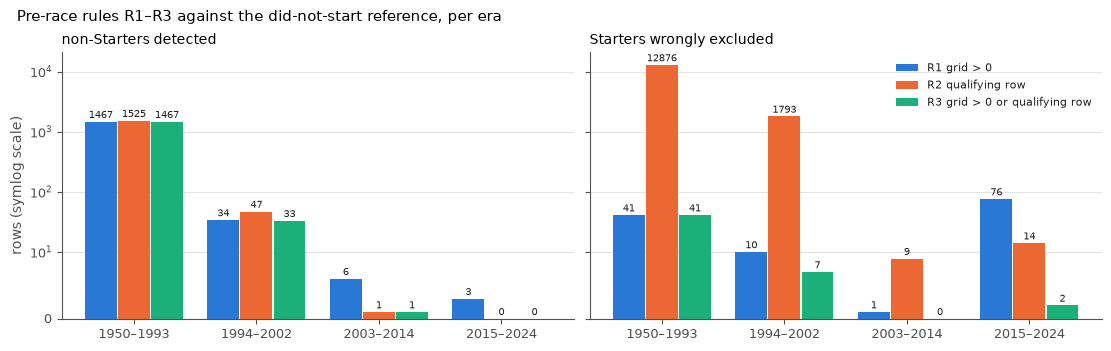

In [33]:
def plot_rules_by_era(confusion, title):
    """Per era and rule: non-Starters detected (left) and Starters wrongly excluded (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, constrained_layout=True)
    eras, rules = list(ERAS), list(RULES)
    x = np.arange(len(eras))
    colors = [BLUE, ORANGE, "#1baf7a"]
    for ax, column, label in [(axes[0], "non_starters_detected", "non-Starters detected"),
                              (axes[1], "starters_wrongly_excluded", "Starters wrongly excluded")]:
        for i, (rule, color) in enumerate(zip(rules, colors)):
            values = [confusion.loc[(era, rule), column] for era in eras]
            bars = ax.bar(x + (i - 1) * 0.27, values, width=0.26, color=color, label=rule)
            ax.bar_label(bars, fontsize=7, color=INK, padding=1)
        ax.set_xticks(x, eras)
        ax.set_yscale("symlog", linthresh=10)
        style_axes(ax)
        ax.set_title(label, loc="left", fontsize=10)
    axes[0].set_ylabel("rows (symlog scale)", color=MUTED)
    axes[1].legend(frameon=False, fontsize=8, labelcolor=INK)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    return fig


save_figure(plot_rules_by_era(confusion, "Pre-race rules R1–R3 against the did-not-start reference, per era"),
            "section2_rules_by_era");

From 2003 the rules hardly detect any non-Starters. Which statuses do the non-Starters
have there, and how many have a qualifying row and a grid slot?

In [34]:
late_dns = base[base.did_not_start_status & base.year.ge(2003)]
display(late_dns.groupby(["status", "year"]).size().unstack(fill_value=0))
late_dns.assign(era=era_of(late_dns.year)).groupby("era", observed=True).agg(
    rows=("raceId", "size"), with_qualifying_row=("has_qualifying_row", "sum"),
    grid_gt_0=("grid", lambda g: int(g.gt(0).sum())))

year,2005,2009,2011,2012,2013,2014,2015,2016,2019,2020,2022,2023,2024
status,,,,,,,,,,,,,
Did not qualify,0,0,2,2,0,0,0,0,0,0,0,0,0
Withdrew,14,1,0,1,1,2,3,2,1,1,1,2,2


,rows,with_qualifying_row,grid_gt_0
era,,,
2003–2014,23,22,17
2015–2024,12,12,9


### Results rows without a qualifying row in races with qualifying data

In [35]:
q8 = base[base.race_has_qualifying & ~base.has_qualifying_row]
print("rows:", len(q8))
q8.assign(era=era_of(q8.year)).groupby(["era", "did_not_start_status"], observed=True).agg(
    rows=("raceId", "size"), laps_gt_0=("laps", lambda s: int(s.gt(0).sum())),
    grid_zero=("grid_zero", "sum"), statuses=("status", lambda s: s.value_counts().to_dict()))

rows: 59


rows  laps_gt_0  grid_zero  \
era       did_not_start_status                               
1994–2002 False                    1          0          1   
          True                    34          0         24   
2003–2014 False                    9          9          0   
          True                     1          0          1   
2015–2024 False                   14         12          2   

                                                                         statuses  
era       did_not_start_status                                                     
1994–2002 False                                                     {'Injury': 1}  
          True                            {'Did not qualify': 28, '107% Rule': 6}  
2003–2014 False                 {'Finished': 4, '+1 Lap': 3, 'Brakes': 1, '+2 ...  
          True                                                    {'Withdrew': 1}  
2015–2024 False                 {'+1 Lap': 4, '+2 Laps': 2, 'Power Unit': 2, '...

In [36]:
q8[q8.year >= 2003][["year", "race_name", "driverId", "grid", "laps", "positionOrder", "status"]]

,year,race_name,driverId,grid,laps,positionOrder,status
20855,2011,Turkish Grand Prix,155,24,58,10,Finished
20877,2011,Spanish Grand Prix,2,24,65,8,+1 Lap
21041,2011,Belgian Grand Prix,30,24,44,5,Finished
21192,2011,Abu Dhabi Grand Prix,22,24,54,12,+1 Lap
21359,2012,Monaco Grand Prix,815,23,77,11,+1 Lap
21420,2012,European Grand Prix,10,0,0,24,Withdrew
21537,2012,Italian Grand Prix,807,24,50,21,Brakes
21608,2012,Korean Grand Prix,39,23,53,20,+2 Laps
22517,2014,Abu Dhabi Grand Prix,817,20,55,4,Finished
22521,2014,Abu Dhabi Grand Prix,20,19,55,8,Finished


**Observation (section 2):**
- 137 distinct statuses. The did-not-start group has 1,613 rows: "Did not qualify" 1,025, "Did not prequalify" 331, "Withdrew" 248, "107% Rule" 9. It lies almost entirely before 1996; peaks 1988–1991 (74–203 per season), matching the large fields from section 1. From 1996 mostly 0–3 per season, except 2005 (14).
- The reference itself is not entirely clean: 23 "Withdrew" rows and 1 "Did not qualify" row have `laps > 0`.
- **No** non-Starter has a podium row (assert).

*Recognisability before the race (table above):*
- **1950–1993:** no qualifying data, R2 is useless, R3 = R1. R1 detects 1,467 of 1,525 non-Starters, misses 58 and wrongly excludes 41 Starters.
- **1994–2002:** R1 detects 34 of 53 and excludes 10 Starters. R2 detects 47 but excludes 1,793 Starters (patchy qualifying data). R3 detects 33 and excludes 7 Starters.
- **2003–2014:** R1 detects 6 of 23 non-Starters and excludes 1 Starter. R2 and R3 detect 1 each (R2 excludes 9 Starters, R3 none).
- **2015–2024:** R1 detects 3 of 12 but excludes 76 Starters (Pit-Lane Starts, section 3). R2 and R3 detect none; R3 excludes 2 Starters.
- The 35 non-Starters from 2003: in 2003–2014 they are 19 × "Withdrew" (14 of them on one weekend in 2005) and 4 × "Did not qualify" (2011/2012), 22 of them with a qualifying row, 17 with a grid slot; in 2015–2024 they are 12 × "Withdrew", all with a qualifying row, 9 with a grid slot. Before the race they mostly look like Starters.

*No qualifying row (59 rows without a qualifying row in races with qualifying data):*
- 35 rows from 1994–1999 are non-Starters ("Did not qualify", "107% Rule") plus one "Injury". *Assumption:* the qualifying table of these years partly omits drivers who did not qualify.
- Of the 24 rows from 2011–2021, one is "Withdrew" (2012). 21 of the other 23 drive laps, so they are **Starters**, mostly from the back (`grid` 19–24); two (2015, "Fuel system" and "ERS") have `laps == 0`, so whether they started is open. *Assumption:* drivers without a valid qualifying time who were still allowed to start. So these are not late entries but a gap in the qualifying table.

<a id="sec-3"></a>
## 3. `grid == 0`

Builds on the breakdown in the audit, now with podium rate and qualifying row. Three
groups: `laps == 0` with a did-not-start status, `laps == 0` with another status
("unclear"), `laps > 0`.

In [37]:
def grid_zero_groups(base):
    """grid == 0 rows with a group by laps and did-not-start status."""
    rows = base[base.grid_zero]
    group = pd.Series("laps > 0", index=rows.index)
    group[rows.laps.eq(0) & rows.did_not_start_status] = "laps == 0, did-not-start status"
    group[rows.laps.eq(0) & ~rows.did_not_start_status] = "laps == 0, other status (unclear)"
    return rows.assign(grid_zero_group=group)


gz = grid_zero_groups(base)
gz.groupby("grid_zero_group").agg(
    rows=("raceId", "size"), seasons=("year", lambda y: f"{y.min()}–{y.max()}"),
    podium_rows=("podium_row", "sum"), with_qualifying_row=("has_qualifying_row", "sum"),
).assign(podium_rate=lambda d: (d.podium_rows / d.rows).round(3))

,rows,seasons,podium_rows,with_qualifying_row,podium_rate
grid_zero_group,,,,,
"laps == 0, did-not-start status",1510,1952–2023,0,9,0.0
"laps == 0, other status (unclear)",56,1954–2023,0,7,0.0
laps > 0,72,2015–2024,0,71,0.0


In [38]:
pit_lane = gz[gz.grid_zero_group.eq("laps > 0")]
print("laps > 0, seasons:", pit_lane.year.min(), "–", pit_lane.year.max(), "| with qualifying row:",
      int(pit_lane.has_qualifying_row.sum()), "of", len(pit_lane))
pit_lane[~pit_lane.has_qualifying_row][["year", "race_name", "driverId", "laps", "status"]]

laps > 0, seasons: 2015 – 2024 | with qualifying row: 71 of 72


,year,race_name,driverId,laps,status
24246,2019,Chinese Grand Prix,848,55,+1 Lap


From 2003: rows with `grid == 0`, a did-not-start status and whether a qualifying row
exists, by era (section 2). From 2015 there are Pit-Lane Starts; there, non-Starters with
`grid == 0` and a qualifying row look exactly like a Pit-Lane Start before the race.

In [39]:
late_gz = gz[gz.year.ge(2003) & gz.did_not_start_status]
late_gz.assign(era=era_of(late_gz.year)).groupby(["era", "status", "has_qualifying_row"], observed=True).agg(
    rows=("raceId", "size"), seasons=("year", lambda y: sorted(set(y))))

rows             seasons
era       status          has_qualifying_row                          
2003–2014 Did not qualify True                   4        [2011, 2012]
          Withdrew        False                  1              [2012]
                          True                   1              [2009]
2015–2024 Withdrew        True                   3  [2015, 2022, 2023]

The unclear rows (`laps == 0`, other status) by decade and status:

In [40]:
unclear = gz[gz.grid_zero_group.eq("laps == 0, other status (unclear)")]
pd.crosstab(unclear.status, unclear.year // 10 * 10, margins=True)

year,1950,1960,1970,1980,1990,2000,2010,2020,All
status,,,,,,,,,
Accident,2,3,6,4,3,0,0,0,18
Battery,0,0,0,0,0,0,1,0,1
Brakes,0,0,0,0,0,0,0,1,1
Disqualified,0,0,0,4,2,0,0,0,6
Engine,4,1,0,0,0,0,0,1,6
Excluded,0,0,0,5,1,0,0,0,6
Fatal accident,0,0,1,0,0,0,0,0,1
Fuel system,0,1,0,0,0,0,1,0,2
Injured,0,0,0,1,1,0,0,0,2


**Observation (section 3):**
- **None** of the 1,638 `grid == 0` rows has a podium row (podium rate 0 in all three groups; overall it is 12.7%).
- `laps == 0` with a did-not-start status: 1,510 rows (1952–2023), only 9 of them with a qualifying row. Compared with the audit (1,508), the 2 "107% Rule" rows are added, because the did-not-start group from section 2 includes them.
- `laps > 0`: 72 rows, all 2015–2024; **71 have a qualifying row**. The one exception is China 2019 (driver 848, "+1 Lap"). *Assumption:* did not take part in qualifying and started from the pit lane.
- In 2011/2012 there are 4 rows with `grid == 0`, "Did not qualify" **and** a qualifying row (107% cases), i.e. in the era 2003–2014, in which every `grid == 0` row has `laps == 0`. In the era of Pit-Lane Starts (2015–2024) there are 3 "Withdrew" rows with a qualifying row (2015, 2022, 2023): with `grid` and the qualifying row alone they cannot be told apart from Pit-Lane Starts.
- The 56 unclear rows (1954–2023, 7 with a qualifying row) are spread over all decades (mostly 1–5 per season); most frequent statuses: Accident 18, Injury 8, Disqualified 6, Engine 6, Excluded 6.

<a id="sec-4"></a>
## 4. Duplicate groups

A **duplicate group** is a `(raceId, driverId)` key with more than one row in `results`.
Reconciliation with the audit: there `nk_duplicates` counts the *surplus* rows (each from
the second on); here we count the groups themselves.

In [41]:
def duplicate_groups(base):
    """All rows of the duplicate groups with group size and rows with grid > 0 per group."""
    rows = base[base.duplicate_group]
    by_group = rows.groupby(KEY)
    return rows.assign(group_size=by_group.raceId.transform("size"),
                       group_rows_on_grid=by_group.grid.transform(lambda g: int((g > 0).sum())),
                       group_podium_rows=by_group.podium_row.transform("sum"))


dups = duplicate_groups(base)
groups = dups.drop_duplicates(KEY)
print("affected keys (groups):", len(groups))
print("rows in groups:", len(dups), "| surplus rows:", len(dups) - len(groups))
groups.group_size.value_counts().sort_index().rename_axis("rows per group").rename("groups").to_frame()

affected keys (groups): 85
rows in groups: 176 | surplus rows: 91


,groups
rows per group,
2,79
3,6


**Observation (reconciliation):** 85 affected keys (groups), 79 with 2 and 6 with 3 rows → 176 rows, 91 of them surplus. This matches `nk_duplicates = 91` from the audit and the assert in section 0 (85 groups).

### Which columns differ within a group?

In [42]:
COMPARE = ["constructorId", "number", "grid", "positionOrder", "points", "laps", "status"]
dups.groupby(KEY)[COMPARE].nunique(dropna=False).gt(1).sum().rename("groups with a difference").to_frame()

,groups with a difference
constructorId,16
number,85
grid,81
positionOrder,85
points,35
laps,82
status,79


**Observation:** in **all** 85 groups the car number and `positionOrder` differ, in almost all also `grid` (81), `laps` (82) and status (79); points only in 35, constructor in 16. The rows of a group are therefore not copies but different cars of the same driver in the same race.

### Grid slot and podium per group

How many rows of a group have a grid slot (`grid > 0`), and how many podium rows does it
have?

In [43]:
pd.crosstab(groups.group_rows_on_grid.rename("rows with grid > 0"),
            groups.group_podium_rows.rename("podium rows"), margins=True)

podium rows,0,1,2,All
rows with grid > 0,,,,
0,3,0,0,3
2,55,20,1,76
3,5,0,1,6
All,63,20,2,85


**Observation:** **no** group has exactly one row with `grid > 0`: 76 groups have two, 6 have three, 3 have none. The assumption "one row is the car the driver started in" therefore cannot be supported via `grid`. 63 groups have no podium row, 20 exactly one, 2 two.

### The 22 groups with a podium row

The first rows for reading, then all cases in numbers.

In [44]:
SHOW = ["year", "race_name", "driverId", "constructorId", "number", "grid", "positionOrder", "points", "laps", "status"]
podium_groups = dups[dups.group_podium_rows > 0].sort_values(["year", "raceId", "driverId", "positionOrder"])
print(f"{len(podium_groups)} rows in {podium_groups[KEY].drop_duplicates().shape[0]} groups; first 12 rows shown, "
      "the numbers below summarise all of them")
display(podium_groups[SHOW].head(12))

45 rows in 22 groups; first 12 rows shown, the numbers below summarise all of them


,year,race_name,driverId,constructorId,number,grid,positionOrder,points,laps,status
20182,1950,Italian Grand Prix,647,6,48.0,6,2,3.0,80,Finished
20165,1950,Italian Grand Prix,647,6,16.0,2,17,0.0,21,Engine
20185,1951,French Grand Prix,579,51,8.0,7,1,5.0,77,Finished
19927,1951,French Grand Prix,579,51,24.0,1,11,0.0,55,+22 Laps
19918,1951,French Grand Prix,647,6,14.0,6,2,3.0,77,Finished
19934,1951,French Grand Prix,647,6,12.0,3,18,0.0,10,Gearbox
19917,1951,French Grand Prix,786,51,8.0,7,1,4.0,77,Finished
20187,1951,French Grand Prix,786,51,24.0,1,11,0.0,55,+22 Laps
20188,1951,Italian Grand Prix,642,51,40.0,7,3,3.0,79,+1 Lap
19997,1951,Italian Grand Prix,642,51,34.0,2,16,0.0,6,Engine


In [45]:
def shares_position_with_other_driver(rows, base):
    """True if another driver in the same race has the same positionOrder."""
    drivers_per_position = base.groupby(["raceId", "positionOrder"]).driverId.nunique()
    return rows.set_index(["raceId", "positionOrder"]).index.map(drivers_per_position).to_numpy() > 1


podium_rows_in_groups = podium_groups[podium_groups.podium_row]
pd.Series(
    {
        "groups with a podium row": podium_groups[KEY].drop_duplicates().shape[0],
        "of which with 2 podium rows": int((podium_groups.drop_duplicates(KEY).group_podium_rows == 2).sum()),
        "podium rows in these groups": len(podium_rows_in_groups),
        "podium rows with grid > 0": int(podium_rows_in_groups.grid.gt(0).sum()),
        "podium rows with points > 0": int(podium_rows_in_groups.points.gt(0).sum()),
        "podium rows with status Finished": int(podium_rows_in_groups.status.eq("Finished").sum()),
        "podium rows whose positionOrder another driver shares": int(
            shares_position_with_other_driver(podium_rows_in_groups, base).sum()
        ),
    }
).rename("count").to_frame()

,count
groups with a podium row,22
of which with 2 podium rows,2
podium rows in these groups,24
podium rows with grid > 0,24
podium rows with points > 0,23
podium rows with status Finished,15
podium rows whose positionOrder another driver shares,24


**Observation (podium groups in numbers):**
- 22 groups with 24 podium rows in total (2 groups have two).
- All 24 podium rows have `grid > 0`, 23 have points, 15 the status "Finished".
- **All 24** share their `positionOrder` with another driver in the same race. A podium row in a group is therefore always a Shared Car: two drivers are credited with the same placing (e.g. 1957 British GP: drivers 475 and 479 both in 1st place, with 5 and 4 points).

<a id="sec-5"></a>
## 5. Races without exactly three podium rows

Per race with ≠ 3 rows `positionOrder <= 3`: how many distinct podium positions, how many
distinct drivers, and how many of the podium rows belong to a duplicate group.

"Explained by duplicate" means: if every duplicate group is merged into one driver,
exactly three drivers remain on the podium.

In [46]:
def podium_count_check(base):
    """Races with != 3 podium rows and their breakdown."""
    podium = base[base.podium_row]
    per_race = podium.groupby("raceId").agg(
        year=("year", "first"),
        race_name=("race_name", "first"),
        podium_rows=("podium_row", "size"),
        podium_positions=("positionOrder", "nunique"),
        podium_drivers=("driverId", "nunique"),
        podium_rows_in_duplicate_group=("duplicate_group", "sum"),
    )
    off = per_race[per_race.podium_rows != 3]
    return off.assign(
        shared_position=off.podium_rows > off.podium_positions,
        explained_by_duplicate=off.podium_drivers == 3,
    )


podium_check = podium_count_check(base)
podium_check

,year,race_name,podium_rows,podium_positions,podium_drivers,podium_rows_in_duplicate_group,shared_position,explained_by_duplicate
raceId,,,,,,,,
746,1960,Argentine Grand Prix,4,3,4,1,True,False
780,1957,British Grand Prix,4,3,4,2,True,False
784,1956,Argentine Grand Prix,4,3,4,1,True,False
785,1956,Monaco Grand Prix,4,3,4,1,True,False
787,1956,Belgian Grand Prix,4,3,4,1,True,False
789,1956,British Grand Prix,4,3,4,2,True,False
791,1956,Italian Grand Prix,4,3,4,1,True,False
792,1955,Argentine Grand Prix,7,3,5,4,True,False
793,1955,Monaco Grand Prix,4,3,4,2,True,False


In [47]:
pd.Series(
    {
        "races with ≠ 3 podium rows": len(podium_check),
        "of which with exactly 3 podium positions": int((podium_check.podium_positions == 3).sum()),
        "of which with a shared position": int(podium_check.shared_position.sum()),
        "of which with a podium row in a duplicate group": int((podium_check.podium_rows_in_duplicate_group > 0).sum()),
        "of which explained by duplicate (3 drivers)": int(podium_check.explained_by_duplicate.sum()),
        "races with a shared positionOrder (any position)": base[base.duplicated(["raceId", "positionOrder"], keep=False)].raceId.nunique(),
    }
).rename("count").to_frame()

,count
races with ≠ 3 podium rows,18
of which with exactly 3 podium positions,18
of which with a shared position,18
of which with a podium row in a duplicate group,16
of which explained by duplicate (3 drivers),0
races with a shared positionOrder (any position),46


The two races without a duplicate group on the podium, row by row:

In [48]:
no_dup = podium_check.query("podium_rows_in_duplicate_group == 0").index
base[base.raceId.isin(no_dup) & base.podium_row].sort_values(["raceId", "positionOrder"])[SHOW]

,year,race_name,driverId,constructorId,number,grid,positionOrder,points,laps,status
19100,1955,Indianapolis 500,628,113,6.0,14,1,8.0,200,Finished
19101,1955,Indianapolis 500,529,113,10.0,2,2,3.0,200,Finished
20260,1955,Indianapolis 500,555,113,10.0,2,2,3.0,200,Finished
19102,1955,Indianapolis 500,653,113,15.0,10,3,4.0,200,Finished
19871,1951,Indianapolis 500,766,113,99.0,2,1,9.0,200,Finished
19872,1951,Indianapolis 500,673,113,83.0,7,2,6.0,200,Finished
19873,1951,Indianapolis 500,658,113,9.0,3,3,2.0,200,Finished
20184,1951,Indianapolis 500,675,113,9.0,3,3,2.0,200,Finished


**Observation (section 5):**
- All 18 races (1950–1960) have **exactly three** podium positions but 4–7 podium rows: several drivers share a position (Shared Car).
- 16 of the 18 races have a podium row in a duplicate group. The two without are the 1951 and 1955 Indianapolis 500: there, two drivers without another row of their own share a position (1951: 3rd place, 1955: 2nd place).
- **No** race is "explained by duplicate": even if every duplicate group is merged into one driver, 4–5 distinct drivers stand on the podium. The cause is the Shared Car, not the duplicated row.
- Overall, several drivers share a `positionOrder` in 46 races (1950–1964), not only on the podium.
- For the target this means (observation, no decision): with `positionOrder <= 3` per row, a race can have more than three podium Entries. Section 4 (duplicate groups, Shared Cars) decides whether that stays so.

<a id="sec-6"></a>
## 6. Indianapolis 500

Identified by the race name "Indianapolis 500", **not** by the circuit: the regular
United States Grand Prix took place on the same circuit in 2000–2007.

In [49]:
indy_races = raw["races"][raw["races"].name.eq("Indianapolis 500")]
same_circuit = raw["races"][raw["races"].circuitId.isin(indy_races.circuitId) & ~raw["races"].name.eq("Indianapolis 500")]

assert len(indy_races) == 11, "Expected: 11 Indianapolis 500 races"
assert indy_races.year.between(1950, 1960).all(), "Indianapolis 500 only 1950–1960"
assert not base[base.year.between(2000, 2007)].indy_500.any(), "US GP 2000–2007 must not be flagged"

print("Indy races:", sorted(indy_races.year))
print("Other races on the same circuit:", same_circuit[["year", "name"]].values.tolist())

Indy races: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]
Other races on the same circuit: [[2007, 'United States Grand Prix'], [2006, 'United States Grand Prix'], [2005, 'United States Grand Prix'], [2004, 'United States Grand Prix'], [2003, 'United States Grand Prix'], [2002, 'United States Grand Prix'], [2001, 'United States Grand Prix'], [2000, 'United States Grand Prix']]


In [50]:
indy = base[base.indy_500]
indy_seasons = base[base.year.le(1960)].groupby("year").agg(
    rows=("raceId", "size"), indy_rows=("indy_500", "sum"),
    podium_rows=("podium_row", "sum"), indy_podium_rows=("podium_row", lambda s: int((s & base.loc[s.index, "indy_500"]).sum())),
).assign(indy_row_share=lambda d: (d.indy_rows / d.rows).round(3),
         indy_podium_share=lambda d: (d.indy_podium_rows / d.podium_rows).round(3))
print("Indy: rows", len(indy), "| Entries", indy.drop_duplicates(KEY).shape[0], "| podium rows", int(indy.podium_row.sum()))
indy_seasons

Indy: rows 405 | Entries 381 | podium rows 36


,rows,indy_rows,podium_rows,indy_podium_rows,indy_row_share,indy_podium_share
year,,,,,,
1950,160,35,22,3,0.219,0.136
1951,179,34,28,4,0.190,0.143
1952,215,33,24,3,0.153,0.125
1953,246,47,29,4,0.191,0.138
1954,230,55,29,3,0.239,0.103
1955,180,35,27,4,0.194,0.148
1956,190,34,29,3,0.179,0.103
1957,171,33,25,3,0.193,0.120
1958,241,33,33,3,0.137,0.091


In [51]:
def field_overlap(base, mask):
    """Field size and overlap of drivers/constructors between flagged and other races."""
    marked, rest = base[mask], base[~mask]
    same_era = rest[rest.year.between(marked.year.min(), marked.year.max())]
    return pd.Series({
        "field size flagged (mean)": marked.groupby("raceId").size().mean().round(1),
        "field size other races of the same seasons (mean)": same_era.groupby("raceId").size().mean().round(1),
        "drivers flagged": marked.driverId.nunique(),
        "drivers also in other races": len(set(marked.driverId) & set(rest.driverId)),
        "constructors flagged": marked.constructorId.nunique(),
        "constructors also in other races": len(set(marked.constructorId) & set(rest.constructorId)),
    }).to_frame("value")


field_overlap(base, base.indy_500)

,value
field size flagged (mean),36.8
field size other races of the same seasons (mean),22.0
drivers flagged,107.0
drivers also in other races,4.0
constructors flagged,34.0
constructors also in other races,3.0


**Observation (section 6):**
- 11 races (every year 1950–1960), 405 rows, 381 Entries, 36 podium rows. The asserts confirm that the US GP 2000–2007 on the same circuit is not affected.
- Per season the Indy 500 makes up 14–24% of the rows.
- The field is larger (mean 36.8 rows against 22.0 in the other races 1950–1960) and almost separate from the rest: of 107 Indy drivers only 4 also drive other races, of 34 constructors only 3.

<a id="sec-7"></a>
## 7. Sprints

Which races have a sprint, and does it take place before or after qualifying?
`races.quali_date` and `sprint_date` only exist from 2021; times are missing in 2021.
There are no sprints before 2021, so the gap affects no sprint races.

In [52]:
sprint_races = raw["races"][raw["races"].sprint_date.notna()].copy()
assert set(sprint_races.raceId) == set(raw["sprint_results"].raceId), "sprint_date and sprint_results cover the same races"


def session_order(races):
    """Order of qualifying and sprint from date and (where present) time."""
    quali = pd.to_datetime(races.quali_date + " " + races.quali_time.fillna("00:00:00"))
    sprint = pd.to_datetime(races.sprint_date + " " + races.sprint_time.fillna("00:00:00"))
    order = pd.Series("sprint before qualifying", index=races.index)
    order[sprint > quali] = "qualifying before sprint"
    order[races.quali_time.isna() & (races.sprint_date == races.quali_date)] = "same day, time missing"
    return order


sprint_races["order"] = session_order(sprint_races)
sprint_races[["year", "name", "quali_date", "quali_time", "sprint_date", "sprint_time", "date", "order"]]

,year,name,quali_date,quali_time,sprint_date,sprint_time,date,order
1046,2021,British Grand Prix,2021-07-16,NaN,2021-07-17,NaN,2021-07-18,qualifying before sprint
1050,2021,Italian Grand Prix,2021-09-10,NaN,2021-09-11,NaN,2021-09-12,qualifying before sprint
1055,2021,São Paulo Grand Prix,2021-11-12,NaN,2021-11-13,NaN,2021-11-14,qualifying before sprint
1060,2022,Emilia Romagna Grand Prix,2022-04-22,15:00:00,2022-04-23,14:30:00,2022-04-24,qualifying before sprint
1067,2022,Austrian Grand Prix,2022-07-08,15:00:00,2022-07-09,14:30:00,2022-07-10,qualifying before sprint
1077,2022,São Paulo Grand Prix,2022-11-11,19:00:00,2022-11-12,19:30:00,2022-11-13,qualifying before sprint
1082,2023,Azerbaijan Grand Prix,2023-04-28,13:00:00,2023-04-29,13:30:00,2023-04-30,qualifying before sprint
1087,2023,Austrian Grand Prix,2023-06-30,15:00:00,2023-07-01,14:30:00,2023-07-02,qualifying before sprint
1090,2023,Belgian Grand Prix,2023-07-28,15:00:00,2023-07-29,14:30:00,2023-07-30,qualifying before sprint
1095,2023,Qatar Grand Prix,2023-10-06,17:00:00,2023-10-07,17:30:00,2023-10-08,qualifying before sprint


In [53]:
sprint_races.groupby(["year", "order"]).size().unstack(fill_value=0)

order,qualifying before sprint,sprint before qualifying
year,,
2021,3,0
2022,3,0
2023,6,0
2024,0,6


In [54]:
in_sprint_race = base.raceId.isin(sprint_races.raceId)
pd.DataFrame({
    "train ≤ 2019": [int(in_sprint_race[base.year.le(2019)].sum())],
    "validation 2020–2021": [int(in_sprint_race[base.year.between(2020, 2021)].sum())],
    "validation 2019–2021": [int(in_sprint_race[base.year.between(2019, 2021)].sum())],
    "test ≥ 2022": [int(in_sprint_race[base.year.ge(2022)].sum())],
}, index=["rows in sprint races"])

,train ≤ 2019,validation 2020–2021,validation 2019–2021,test ≥ 2022
rows in sprint races,0,60,60,300


Does the Qualifying Position differ from `grid` more often in sprint races than in the
other races of the same seasons?

In [55]:
def quali_vs_grid(base, tables, sprint_race_ids, seasons_from):
    """Share of rows with Qualifying Position != grid, by period and sprint race."""
    rows = tables["qualifying"][["raceId", "driverId", "position"]].merge(
        base[["raceId", "driverId", "grid", "year"]], on=KEY)
    rows = rows[rows.year.ge(seasons_from)]
    return rows.assign(
        period=rows.year.map(lambda y: "2021–2022" if y <= 2022 else "2023–2024"),
        sprint_race=rows.raceId.isin(sprint_race_ids),
        differs=rows.position.ne(rows.grid),
    ).groupby(["period", "sprint_race"]).differs.agg(rows="size", differs="sum", share="mean").round(3)


quali_vs_grid(base, raw, sprint_races.raceId, seasons_from=2021)

rows  differs  share
period    sprint_race                      
2021–2022 False         759      223  0.294
          True          120      102  0.850
2023–2024 False         679      165  0.243
          True          240       74  0.308

**Observation (section 7):**
- 18 sprint races: 2021 3, 2022 3, 2023 6, 2024 6.
- 2021–2023: qualifying on Friday, sprint on Saturday (2021 without times, but on different days). 2024: sprint and qualifying on the same day, the sprint **before** qualifying.
- In all 18 races the sprint takes place before the race start.
- *Context (project brief):* in 2021–2022 the sprint result set the starting grid of the main race. From 2023 Friday qualifying sets the grid of the main race, and a separate session that of the sprint. In sprint races 2021–2022, Qualifying Position and Grid Position can therefore differ because of the sprint, not because of penalties.
- Data evidence (table above): in sprint races 2021–2022 the Qualifying Position differs from `grid` in 85% of rows, in the other races of these seasons in 29% (one grid penalty shifts every car behind it, so a single penalty changes several rows). In 2023–2024, sprint races (31%) and other races (24%) are close together.
- No sprint race in training (up to 2019); 3 races (60 rows) in validation 2020/2021 and 2019–2021; 15 races (300 rows) in test.

<a id="sec-8"></a>
## 8. Cleaning to `data/clean/`

Generic cleaning of the raw tables, without removing rows. The first step covers
the time parser and one table with time columns
(`qualifying`), written as Parquet and read back. The other 13 tables follow the same
path below.

### Time parser

Durations are stored as text in four formats: `SS.sss` (pit stops), `M:SS.sss`,
`MM:SS.sss` and `H:MM:SS.sss` (laps over an hour, e.g. under a red flag).
`parse_duration` turns them into seconds. A non-missing text that matches no format
raises an error instead of silently becoming NaN. The unit test comes before any use,
because `q1`–`q3` and `fastestLapTime` have no `milliseconds` column to check the values
against.

In [56]:
DURATION_FORMATS = [
    re.compile(r"(?P<h>\d+):(?P<m>[0-5]\d):(?P<s>[0-5]\d\.\d+)"),  # H:MM:SS.sss
    re.compile(r"(?P<m>\d{1,2}):(?P<s>[0-5]\d\.\d+)"),  # M:SS.sss, MM:SS.sss
    re.compile(r"(?P<s>\d{1,2}\.\d+)"),  # SS.sss
]


def parse_duration(text):
    """Duration text → seconds; missing → NaN; any other text without a matching format → ValueError."""
    if pd.isna(text):
        return math.nan
    for pattern in DURATION_FORMATS:
        match = pattern.fullmatch(text)
        if match:
            parts = {"h": "0", "m": "0", **match.groupdict()}
            return int(parts["h"]) * 3600 + int(parts["m"]) * 60 + float(parts["s"])
    raise ValueError(f"unknown time format: {text!r}")

In [57]:
DURATION_EXAMPLES = {"59.123": 59.123, "1:26.572": 86.572, "16:44.718": 1004.718, "1:02:03.456": 3723.456}
for text, seconds in DURATION_EXAMPLES.items():
    assert math.isclose(parse_duration(text), seconds), text
assert math.isnan(parse_duration(pd.NA))

for malformed in ["1:26,572", "abc", "1:75.000", "1:2:03.456", "-5.0"]:
    try:
        parse_duration(malformed)
    except ValueError:
        continue
    raise AssertionError(f"no error for {malformed!r}")

### Cleaning `qualifying`

Two steps per table, in this order:
1. **Placeholder step:** `\N` is already missing after loading (see the `\N` check);
   in addition, leading and trailing whitespace is stripped from every text cell (one
   cell in the raw data: `drivers.nationality` "Argentinian "), and empty strings
   become missing (audit: 22 in `q2`, 46 in `q3`).
2. **Time columns** become seconds via `parse_duration`.

The reference for "parsing adds no gaps" is the state **after** step 1, not the raw `\N`
count: otherwise `q2`/`q3` would differ by exactly the 22/46 hidden gaps.

In [58]:
DURATION_COLUMNS = {
    "qualifying": ["q1", "q2", "q3"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
    "results": ["fastestLapTime"],
    "sprint_results": ["fastestLapTime"],
}


def placeholder_strings(tables):
    """Count of `\\N`, empty or whitespace-only strings per text column."""
    rows = [
        {"table": name, "column": col,
         "placeholders": int(df[col].dropna().astype(str).str.strip().isin(["", r"\N"]).sum())}
        for name, df in tables.items()
        for col in text_columns(df)
    ]
    out = pd.DataFrame(rows, columns=["table", "column", "placeholders"])
    return out[out.placeholders > 0].reset_index(drop=True)


def padded_strings(tables):
    """Count of text cells with leading or trailing whitespace per (table.column), only where > 0."""
    counts = pd.Series({
        f"{name}.{col}": int((df[col].dropna().astype(str).str.strip() != df[col].dropna().astype(str)).sum())
        for name, df in tables.items() for col in text_columns(df)
    }, dtype="int64")
    return counts[counts.gt(0)]


def placeholders_to_missing(df):
    """Placeholder step: leading/trailing whitespace stripped, then empty strings → missing."""
    out = df.copy()
    for col in text_columns(out):
        stripped = out[col].str.strip()
        out[col] = stripped.mask(stripped.eq(""))
    return out


def clean_table(df, duration_columns, date_columns=(), drop_columns=()):
    """Placeholder step, dead columns dropped, time columns in seconds, dates as datetime; no row is removed."""
    out = placeholders_to_missing(df).drop(columns=list(drop_columns))
    for col in duration_columns:
        out[col] = out[col].map(parse_duration).astype("float64")
    for col in date_columns:
        out[col] = pd.to_datetime(out[col], format="%Y-%m-%d")  # raises on any other format
    return out

In [59]:
q_times = DURATION_COLUMNS["qualifying"]
q_raw = raw["qualifying"]
q_after_placeholders = placeholders_to_missing(q_raw)
q_clean = clean_table(q_raw, q_times)

assert len(q_clean) == len(q_raw) == 10_494
assert q_raw[q_times].isna().sum().to_dict() == {"q1": 156, "q2": 4_625, "q3": 6_819}
assert q_after_placeholders[q_times].isna().sum().to_dict() == {"q1": 156, "q2": 4_647, "q3": 6_865}
assert q_clean[q_times].isna().sum().equals(q_after_placeholders[q_times].isna().sum())
assert all(pd.api.types.is_float_dtype(q_clean[c]) for c in q_times)
assert placeholder_strings({"qualifying": q_raw}).placeholders.tolist() == [22, 46]  # finds the audit gaps
assert placeholder_strings({"qualifying": q_clean}).empty
assert list(q_clean.columns) == list(q_raw.columns)

In [60]:
q_clean[q_times].describe().round(3)

,q1,q2,q3
count,10338.000,5847.000,3629.000
mean,88.531,87.770,87.406
std,15.393,12.111,12.260
min,53.904,53.647,53.377
25%,78.774,77.942,77.238
50%,87.141,87.125,87.039
75%,95.910,95.956,95.626
max,1002.640,132.470,129.776


### Writing and reloading Parquet

Cleaned tables are stored as Parquet in `data/clean/` (git-ignored except `.gitkeep`, so
always rebuilt from raw). Parquet stores the dtypes; after reloading, values and dtypes
must equal the state before writing, otherwise every later step would have to parse
again. The check covers exactly the tables written here, whatever else is in the folder.

In [61]:
def write_clean(tables, folder):
    """Each table as `<name>.parquet` in the folder (overwrites the previous state)."""
    for name, df in tables.items():
        df.to_parquet(folder / f"{name}.parquet", index=False)


def load_clean(folder, names):
    """Cleaned tables from Parquet as {table name: DataFrame}."""
    return {name: pd.read_parquet(folder / f"{name}.parquet") for name in names}

In [62]:
clean = {"qualifying": q_clean}
write_clean(clean, CLEAN)
reloaded = load_clean(CLEAN, list(clean))

for name, df in clean.items():
    pd.testing.assert_frame_equal(reloaded[name], df)  # values and dtypes
assert reloaded["qualifying"][q_times].dtypes.eq("float64").all()

**What changed and why (`qualifying`):**
- **Decision basis:** no ADR covers generic cleaning; it follows from the audit findings. The raw data marks gaps as `\N` (count per column checked above against a plain-string reading of the files), and `qualifying.q2`/`q3` additionally hide 22/46 empty strings ("Empty strings" in the audit).
- **Raw protection:** checksums of the 14 CSVs versioned in `data/reference/raw_sha256.txt`, checked before loading and in the last cell. This shows that `data/raw/` is unchanged by a full run (`AGENTS.md`: raw is read-only).
- **Time parser:** one parser for all four formats in the raw data, unit-tested on fixed examples. An unknown format raises instead of returning NaN, so the NaN comparison above cannot miss a silent parse failure.
- **`qualifying`:** 10,494 rows, none removed. `q1`–`q3` are seconds (`float64`). Missing after cleaning: `q1` 156, `q2` 4,647, `q3` 6,865, i.e. 22/46 more than the raw `\N` in `q2`/`q3`, **by design**: the empty strings from the audit now count as gaps. Parsing itself adds no gap.
- **Value range (table above):** `q1` 54–154 s, `q2` 54–132 s, `q3` 53–130 s, except one `q1` value of 1,002.6 s (Japan 1995, driver 87, 24th of 24; raw: `16:42.640`). The parser reads it exactly. It is a raw-data outlier, outside the Training Window (from 2003), so no action.
- **Parquet:** the reloaded table equals the written one in values and dtypes. `data/clean/` is git-ignored except `.gitkeep`; it is rebuilt from raw on every run.
- **Next step:** the next cell widens the same path to the other 13 tables (date columns, further time columns, cross-check with `milliseconds`).

### Cleaning all 14 tables

The same path for every table: the placeholder step, then the time columns in seconds,
plus two more steps:
- **Date columns** become datetimes (`YYYY-MM-DD`; a date in any other format raises):
  `races.date`, `fp1_date`–`fp3_date`, `quali_date`, `sprint_date`, `drivers.dob`.
- **`constructor_results.status`** is dropped (100% empty, audit heatmap).

Deliberately **not** converted: the time-of-day columns (`pit_stops.time`, `races.time`,
`fp*_time`, `quali_time`, `sprint_time`) and `results.time` / `sprint_results.time`,
which mix the winner's total time with gaps to the winner (`+5.478`); their numeric
counterpart is `milliseconds`. No row is removed.

In [63]:
DATE_COLUMNS = {
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
    "drivers": ["dob"],
}
DROP_COLUMNS = {"constructor_results": ["status"]}


def clean_tables(tables):
    """Generic cleaning of every table, as {table name: DataFrame}."""
    return {
        name: clean_table(df, DURATION_COLUMNS.get(name, []), DATE_COLUMNS.get(name, []), DROP_COLUMNS.get(name, []))
        for name, df in tables.items()
    }

In [64]:
EXPECTED_ROWS = {
    "circuits": 77, "constructor_results": 12_625, "constructor_standings": 13_391, "constructors": 212,
    "driver_standings": 34_863, "drivers": 861, "lap_times": 589_081, "pit_stops": 11_371, "qualifying": 10_494,
    "races": 1_125, "results": 26_759, "seasons": 75, "sprint_results": 360, "status": 139,
}
EXPECTED_MISSING = {  # after the placeholder step, from the raw files
    ("qualifying", "q1"): 156, ("qualifying", "q2"): 4_647, ("qualifying", "q3"): 6_865,
    ("lap_times", "time"): 0, ("pit_stops", "duration"): 0,
    ("results", "fastestLapTime"): 18_507, ("sprint_results", "fastestLapTime"): 9,
    ("races", "date"): 0, ("races", "fp1_date"): 1_035, ("races", "fp2_date"): 1_035, ("races", "fp3_date"): 1_053,
    ("races", "quali_date"): 1_035, ("races", "sprint_date"): 1_107, ("drivers", "dob"): 0,
}
CONVERTED = {**DURATION_COLUMNS, **DATE_COLUMNS}
TIME_OF_DAY = {"pit_stops": ["time"], "races": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"],
               "results": ["time"], "sprint_results": ["time"]}

after_placeholders = {name: placeholders_to_missing(df) for name, df in raw.items()}
clean = clean_tables(raw)

assert {name: len(df) for name, df in raw.items()} == EXPECTED_ROWS
assert {name: len(df) for name, df in clean.items()} == EXPECTED_ROWS
assert placeholder_strings(clean).empty
assert padded_strings(raw).to_dict() == {"drivers.nationality": 1}  # audit: "Argentinian "
assert padded_strings(clean).empty  # no text cell with leading or trailing whitespace
assert "status" not in clean["constructor_results"].columns
assert all(pd.api.types.is_float_dtype(clean[t][c]) for t, cols in DURATION_COLUMNS.items() for c in cols)
assert all(pd.api.types.is_datetime64_any_dtype(clean[t][c]) for t, cols in DATE_COLUMNS.items() for c in cols)
assert all(c in text_columns(clean[t]) for t, cols in TIME_OF_DAY.items() for c in cols)

missing_after_cleaning = {(t, c): int(clean[t][c].isna().sum()) for t, cols in CONVERTED.items() for c in cols}
missing_after_step_1 = {(t, c): int(after_placeholders[t][c].isna().sum()) for t, cols in CONVERTED.items() for c in cols}
assert missing_after_step_1 == EXPECTED_MISSING
assert missing_after_cleaning == missing_after_step_1  # no conversion adds a gap

for name, df in clean.items():  # every column that is not converted or dropped stays as after step 1
    untouched = [c for c in df.columns if c not in CONVERTED.get(name, [])]
    pd.testing.assert_frame_equal(df[untouched], after_placeholders[name][untouched])
pd.testing.assert_frame_equal(clean["qualifying"], q_clean)  # same result as the first `qualifying` pass

**Cross-check against `milliseconds`.** `lap_times` and `pit_stops` store every duration a
second time, as integer milliseconds. If the parser reads a format wrongly (e.g. hours as
minutes), the two disagree. Tolerance 0.5 ms, i.e. they must agree after rounding.

In [65]:
def milliseconds_check(table, column):
    """Largest gap between parsed seconds × 1000 and the `milliseconds` column, plus the longest duration."""
    gap = (table[column] * 1000 - table.milliseconds).abs()
    return {"rows": len(table), "max_gap_ms": gap.max(), "over_one_hour": int(table[column].gt(3600).sum()),
            "max_seconds": table[column].max()}


ms_check = pd.DataFrame({f"{t}.{c}": milliseconds_check(clean[t], c) for t, c in [("lap_times", "time"),
                                                                                 ("pit_stops", "duration")]}).T
assert ms_check.max_gap_ms.max() < 0.5
ms_check

,rows,max_gap_ms,over_one_hour,max_seconds
lap_times.time,589081.0,1.164153e-10,43.0,7507.547
pit_stops.duration,11371.0,2.328306e-10,0.0,3069.017


Converted columns before and after: dtype, missing values in the raw table and after
cleaning.

In [66]:
def conversion_summary(raw_tables, clean_tables_, columns):
    """dtype and missing count per converted column, raw vs. cleaned."""
    return pd.DataFrame([
        {"column": f"{t}.{c}", "raw_dtype": str(raw_tables[t][c].dtype), "clean_dtype": str(clean_tables_[t][c].dtype),
         "missing_raw": int(raw_tables[t][c].isna().sum()), "missing_clean": int(clean_tables_[t][c].isna().sum())}
        for t, cols in columns.items() for c in cols
    ]).set_index("column")


conversion_summary(raw, clean, CONVERTED)

,raw_dtype,clean_dtype,missing_raw,missing_clean
column,,,,
qualifying.q1,str,float64,156,156
qualifying.q2,str,float64,4625,4647
qualifying.q3,str,float64,6819,6865
lap_times.time,str,float64,0,0
pit_stops.duration,str,float64,0,0
results.fastestLapTime,str,float64,18507,18507
sprint_results.fastestLapTime,str,float64,9,9
races.date,str,datetime64[us],0,0
races.fp1_date,str,datetime64[us],1035,1035


In [67]:
write_clean(clean, CLEAN)
reloaded = load_clean(CLEAN, list(clean))
for name, df in clean.items():
    pd.testing.assert_frame_equal(reloaded[name], df)  # values and dtypes

**What changed and why (all tables):**
- **Decision basis:** no ADR covers generic cleaning; it follows from the audit (`\N` and empty strings as gaps, `constructor_results.status` 100% empty, durations and dates stored as text).
- **All 14 tables cleaned, no row removed** (row counts asserted against the raw counts, 77 to 589,081 rows).
- **Durations in seconds:** `lap_times.time`, `pit_stops.duration`, `results.fastestLapTime`, `sprint_results.fastestLapTime`, plus `qualifying.q1`–`q3`. Missing values after parsing equal those after the placeholder step in every column (e.g. `results.fastestLapTime` 18,507, `sprint_results.fastestLapTime` 9); parsing adds no gap.
- **Cross-check (table above):** parsed `lap_times.time` and `pit_stops.duration` agree with `milliseconds` in all 589,081 and 11,371 rows (largest gap below 10⁻⁹ ms, i.e. floating-point noise). This includes 43 laps over an hour (longest 7,507.5 s, Canada 2011, lap 25) and pit "stops" of up to 3,069.0 s (British GP 2022, stop 1, three drivers at 3,065–3,069 s). *Assumption:* both are race interruptions under a red flag, not data errors. So the `H:MM:SS.sss` and `MM:SS.sss` formats are read correctly.
- **Dates as datetimes:** race and session dates and `drivers.dob`. The session dates keep their structural gaps (e.g. `sprint_date` missing for 1,107 of 1,125 races, audit). Every other column is unchanged by the cleaning (asserted per table).
- **Not converted:** time-of-day columns and the mixed total/gap `results.time` / `sprint_results.time` stay text (asserted); their numeric counterpart is `milliseconds`.
- **`constructor_results.status` dropped.**
- **Whitespace stripped (needed for the nationality mapping of question 2):** exactly one raw text cell had leading or trailing whitespace (`drivers.nationality` "Argentinian ", one driver, 9 Entries); none is left (asserted). No other expected number changes.
- **Parquet:** all 14 tables written and reloaded with values and dtypes intact; `clean["qualifying"]` equals the result of the first `qualifying` pass.

<a id="sec-9"></a>
## 9. Entries table

One row per Entry `(raceId, driverId)` across all seasons, built from the cleaned
`results` plus race context (`races`), status text (`status`) and the Qualifying Position
(`qualifying.position`). Two removals happen here, once, for every later use (Modeling
Table and the assignment's data-engineering questions):
- **Duplicate rule (ADR 0002):** keep no row of a duplicate group, 85 groups with 176 rows.
- **Indianapolis 500 (ADR 0003):** all 11 races, identified by race name, not by circuit.

Both rules overlap (21 of the 85 groups are Indy races), so the accounting counts every
removed row exactly once: duplicate rule only, Indy only, both. No filter on status or
laps (Starter or not). `constructorId` comes from `results`, never from
`qualifying` (2015 Marussia / Manor Marussia, audit).

In [68]:
INDY_500 = "Indianapolis 500"


def results_in_context(tables):
    """Cleaned results + race context + status text, with the two removal flags."""
    races = tables["races"][["raceId", "year", "round", "name", "date", "circuitId"]].rename(columns={"name": "race_name"})
    rows = (tables["results"]
            .merge(races, on="raceId", how="left", validate="many_to_one")
            .merge(tables["status"], on="statusId", how="left", validate="many_to_one"))
    return rows.assign(duplicate_group=rows.duplicated(KEY, keep=False), indy_500=rows.race_name.eq(INDY_500))


def build_entries(tables):
    """One row per Entry: duplicate groups and the Indianapolis 500 removed, Qualifying Position added."""
    rows = results_in_context(tables)
    kept = rows[~rows.duplicate_group & ~rows.indy_500].drop(columns=["duplicate_group", "indy_500"])
    quali = tables["qualifying"][KEY + ["position"]].rename(columns={"position": "qualifying_position"})
    entries = kept.merge(quali, on=KEY, how="left", validate="one_to_one")
    return entries.assign(has_qualifying_row=entries.qualifying_position.notna()).reset_index(drop=True)


def entry_accounting(tables):
    """Row accounting from raw results to Entries; every removed row counted once."""
    rows = results_in_context(tables)
    dup, indy = rows.duplicate_group, rows.indy_500
    kept = rows[~dup & ~indy]
    return pd.Series({
        "raw results rows": len(rows),
        "removed: duplicate rule only": int((dup & ~indy).sum()),
        "removed: Indianapolis 500 only": int((indy & ~dup).sum()),
        "removed: both": int((dup & indy).sum()),
        "remaining rows": len(kept),
        "remaining Entries": int(kept[KEY].drop_duplicates().shape[0]),
    })

In [69]:
EXPECTED_ACCOUNTING = {
    "raw results rows": 26_759,
    "removed: duplicate rule only": 131,
    "removed: Indianapolis 500 only": 360,
    "removed: both": 45,
    "remaining rows": 26_223,
    "remaining Entries": 26_223,
}

entries = build_entries(clean)
accounting = entry_accounting(clean)

assert not entries.duplicated(KEY).any()
assert accounting.to_dict() == EXPECTED_ACCOUNTING
assert (EXPECTED_ACCOUNTING["raw results rows"] - EXPECTED_ACCOUNTING["removed: duplicate rule only"]
        - EXPECTED_ACCOUNTING["removed: Indianapolis 500 only"] - EXPECTED_ACCOUNTING["removed: both"]
        == EXPECTED_ACCOUNTING["remaining rows"])  # the accounting adds up
assert len(entries) == EXPECTED_ACCOUNTING["remaining Entries"]
assert not entries.race_name.eq(INDY_500).any()
assert entries.query("race_name == 'United States Grand Prix' and 2000 <= year <= 2007").raceId.nunique() == 8
assert entries.has_qualifying_row.sum() == 10_494  # all qualifying rows survive (no removed row has one)
from_results = entries[["resultId", "constructorId"]].merge(clean["results"][["resultId", "constructorId"]],
                                                           on="resultId", suffixes=("", "_results"))
assert len(from_results) == len(entries) and from_results.constructorId.eq(from_results.constructorId_results).all()
accounting.rename("rows").to_frame()

,rows
raw results rows,26759
removed: duplicate rule only,131
removed: Indianapolis 500 only,360
removed: both,45
remaining rows,26223
remaining Entries,26223


In [70]:
write_clean({"entries": entries}, CLEAN)
pd.testing.assert_frame_equal(load_clean(CLEAN, ["entries"])["entries"], entries)
entries.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,fastestLapSpeed,statusId,year,round,race_name,date,circuitId,status,qualifying_position,has_qualifying_row
0,1,18,1,1,22.0,1,1.0,1,1,10.0,...,218.300,1,2008,1,Australian Grand Prix,2008-03-16,1,Finished,1.0,True
1,2,18,2,2,3.0,5,2.0,2,2,8.0,...,217.586,1,2008,1,Australian Grand Prix,2008-03-16,1,Finished,5.0,True
2,3,18,3,3,7.0,7,3.0,3,3,6.0,...,216.719,1,2008,1,Australian Grand Prix,2008-03-16,1,Finished,7.0,True
3,4,18,4,4,5.0,11,4.0,4,4,5.0,...,215.464,1,2008,1,Australian Grand Prix,2008-03-16,1,Finished,12.0,True
4,5,18,5,1,23.0,3,5.0,5,5,4.0,...,218.385,1,2008,1,Australian Grand Prix,2008-03-16,1,Finished,3.0,True


**What changed and why (entries table):**
- **Decisions:** ADR 0002 (keep no row of a duplicate group), ADR 0003 (exclude the Indianapolis 500 by race name), all Entries are kept, Starter or not (section 2).
- **Accounting (table above), as expected:** 26,759 raw `results` rows → 131 removed by the duplicate rule only, 360 by the Indy exclusion only, 45 by both → 26,223 rows = 26,223 Entries, one row per `(raceId, driverId)`. The report uses these combined numbers (ADR 0003).
- **Right races removed:** no race named "Indianapolis 500" is left; the 8 United States Grand Prix races 2000–2007 on the same circuit are still there.
- **Nothing else lost:** all 10,494 Entries with a qualifying row survive (no removed row has one; all removals are 1950–1978), and every `constructorId` equals the one in `results`.
- **Stored** as `data/clean/entries.parquet` (round trip asserted), the shared grain for the Modeling Table and the three data-engineering questions.

<a id="sec-10"></a>
## 10. Modeling Table skeleton

The Modeling Table holds every Entry of 2003–2024 (Training Window from 2003, ADR 0001),
Starter or not, with:
- **`split`** by season: train 2003–2019, validation 2020–2021, test 2022–2024 (ADR 0001).
- **Target `podium`:** `positionOrder <= 3` per Entry, derived before the post-race columns
  are moved out.
- **Grid Position (section 3):** `grid == 0` becomes N, the number of Entries in that race in the
  entries table, with the flag `grid_zero`. A Pit-Lane Start counts as the back of the
  grid (`GLOSSARY.md`); no status or laps are used.
- **Qualifying Position (section 2):** from `qualifying`; where an Entry has no qualifying row,
  it falls back to the harmonised Grid Position, with the flag `no_qualifying_row`.
- **`constructorId`** as is (baseline only, no lineage).

Grid Position and the fallback use only the row and its own race, so they are fixed
rules, not statistical imputation, and can be applied before the split. Everything known
only after the race lives in a separate **outcomes** frame keyed by `(raceId, driverId)`.
Lap-time and standings gaps stay missing; no feature is built from them here.

In [71]:
TRAINING_START = 2003
SPLITS = {"train": (2003, 2019), "validation": (2020, 2021), "test": (2022, 2024)}
FEATURES = ["grid_position", "grid_zero", "qualifying_position", "no_qualifying_row", "constructorId"]
IDENTIFIERS = KEY + ["year", "round"]
POST_RACE = ["positionOrder", "position", "positionText", "points", "laps", "statusId", "status", "time",
             "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed"]


def split_of(years):
    """Split name per season according to SPLITS."""
    bins = [SPLITS["train"][0] - 1] + [end for _, end in SPLITS.values()]
    return pd.cut(years, bins=bins, labels=list(SPLITS)).astype(str)


def build_modeling_table(entries):
    """Modeling Table (identifiers, split, pre-race columns, target) and outcomes frame (post-race columns)."""
    rows = entries[entries.year.ge(TRAINING_START)]
    field_size = rows.groupby("raceId").raceId.transform("size")  # N: Entries in the race
    grid_zero = rows.grid.eq(0)
    grid_position = rows.grid.where(~grid_zero, field_size)
    no_qualifying_row = ~rows.has_qualifying_row
    table = rows.assign(
        split=split_of(rows.year),
        grid_position=grid_position,
        grid_zero=grid_zero,
        qualifying_position=rows.qualifying_position.where(~no_qualifying_row, grid_position).astype("int64"),
        no_qualifying_row=no_qualifying_row,
        podium=rows.positionOrder.le(3),  # target, derived before the post-race columns move out
    )
    modeling = table[IDENTIFIERS + ["split"] + FEATURES + ["podium"]].reset_index(drop=True)
    outcomes = table[KEY + POST_RACE].reset_index(drop=True)
    return modeling, outcomes

In [72]:
modeling, outcomes = build_modeling_table(entries)
model_view = modeling.merge(outcomes, on=KEY, validate="one_to_one")
raw_quali_keys = pd.MultiIndex.from_frame(raw["qualifying"][KEY])
field_size = entries.groupby("raceId").size()

assert not modeling.duplicated(KEY).any() and not outcomes.duplicated(KEY).any()
assert len(modeling) == len(outcomes) == len(entries.query("year >= @TRAINING_START"))
assert modeling.split.isin(SPLITS).all()
assert modeling.split.value_counts().to_dict() == {"train": 6_831, "validation": 780, "test": 1_359}
assert not model_view.duplicated(["raceId", "positionOrder"]).any()  # no duplicate groups, no shared positionOrder
assert modeling.podium.eq(model_view.positionText.isin(["1", "2", "3"])).all()  # target vs. classified position
assert modeling.groupby("raceId").podium.sum().eq(3).all()  # exactly three Podium Finishes per race
assert modeling.grid_position.between(1, modeling.raceId.map(field_size)).all()  # never 0, never above N
assert modeling.grid_zero.sum() == 86
raw_grid = modeling[KEY].merge(entries[KEY + ["grid"]], on=KEY).grid
assert modeling.grid_position[~modeling.grid_zero].eq(raw_grid[~modeling.grid_zero]).all()  # grid > 0 kept
assert modeling.qualifying_position.notna().all()
assert modeling.no_qualifying_row.eq(~pd.MultiIndex.from_frame(modeling[KEY]).isin(raw_quali_keys)).all()
assert modeling.no_qualifying_row.sum() == 24
assert not set(POST_RACE) & set(modeling.columns)  # no post-race column next to the features
assert list(modeling.columns) == IDENTIFIERS + ["split"] + FEATURES + ["podium"]

In [73]:
def split_overview(modeling):
    """Races, Entries, Podium Finishes and flag counts per split."""
    return modeling.groupby("split", sort=False).agg(
        seasons=("year", lambda y: f"{y.min()}–{y.max()}"), races=("raceId", "nunique"), entries=("raceId", "size"),
        podium=("podium", "sum"), grid_zero=("grid_zero", "sum"), no_qualifying_row=("no_qualifying_row", "sum"),
    ).assign(podium_share=lambda d: (d.podium / d.entries).round(3)).reindex(list(SPLITS))


write_clean({"modeling_table": modeling, "outcomes": outcomes}, CLEAN)
for name, df in load_clean(CLEAN, ["modeling_table", "outcomes"]).items():
    pd.testing.assert_frame_equal(df, {"modeling_table": modeling, "outcomes": outcomes}[name])
split_overview(modeling)

,seasons,races,entries,podium,grid_zero,no_qualifying_row,podium_share
split,,,,,,,
train,2003–2019,321,6831,963,29,23,0.141
validation,2020–2021,39,780,117,17,1,0.150
test,2022–2024,68,1359,204,40,0,0.150


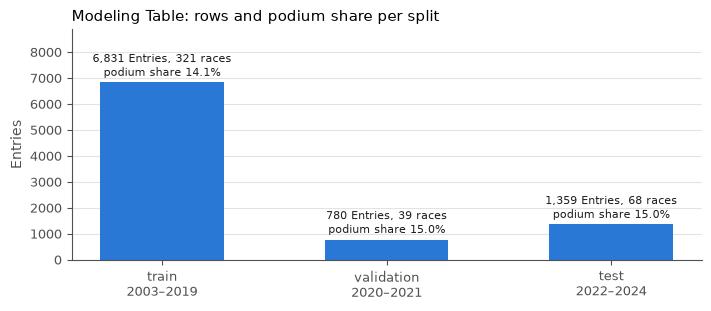

In [74]:
def plot_split_overview(overview, title):
    """Entries per split (bars) with the podium share as label."""
    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    bars = ax.bar(overview.index, overview.entries, color=BLUE, width=0.55)
    ax.bar_label(bars, labels=[f"{int(n):,} Entries, {int(r)} races\npodium share {s:.1%}"
                               for n, r, s in zip(overview.entries, overview.races, overview.podium_share)],
                 fontsize=8, color=INK, padding=2)
    ax.set_xticks(range(len(overview)), [f"{name}\n{seasons}" for name, seasons in zip(overview.index, overview.seasons)])
    ax.set_ylim(0, overview.entries.max() * 1.3)
    style_axes(ax)
    ax.set_ylabel("Entries", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_split_overview(split_overview(modeling), "Modeling Table: rows and podium share per split"),
            "modeling_split_overview");

**What changed and why (Modeling Table):**
- **Decisions:** ADR 0001 (Training Window from 2003, split by season), all Entries (section 2), `grid == 0` → N plus `grid_zero` (section 3), Qualifying Position falls back to the Grid Position plus `no_qualifying_row` (section 2), plain `constructorId` without lineage.
- **Rows and split (table above), as expected:** 8,970 Entries in 428 races; train 6,831 / validation 780 / test 1,359. Podium share 14.1% / 15.0% / 15.0%.
- **Target:** `podium = positionOrder <= 3`. Checked against an independent column: it is true exactly where `positionText` is 1, 2 or 3, and every race has exactly three Podium Finishes (no Shared Cars from 2003; no shared `positionOrder`).
- **Grid Position:** never 0 and never above N; `grid > 0` is kept unchanged. 86 rows have `grid_zero` (train 29, validation 17, test 40; Pit-Lane Starts only occur from 2015, section 3).
- **Qualifying Position:** never missing; `no_qualifying_row` is set exactly for the 24 Entries without a raw qualifying row (2011–2021; train 23, validation 1).
- **Leakage guard:** the post-race columns (`positionOrder`, `position`, `positionText`, `points`, `laps`, status, `time`, `milliseconds`, fastest-lap columns) are only in the outcomes frame; the column list of the Modeling Table is asserted.
- **Stored** as `data/clean/modeling_table.parquet` and `data/clean/outcomes.parquet` (round trip asserted).

<a id="sec-11"></a>
## 11. Before/after: raw vs. cleaned data

The audit and EDA functions from above run **unchanged** on the cleaned tables and the
entries table, next to their raw results. Differences by design:
- **Cleaned tables:** no placeholders left, time and date columns typed, and
  `qualifying.q2`/`q3` missingness **rises** by 22/46, because the hidden empty strings
  now count as gaps. No row is removed, so keys and foreign keys are unchanged.
- **Entries table:** the 536 removed rows (duplicate groups and the Indianapolis
  500) change the seasons 1950–1978 only.

The assert cell states these expectations first; any difference not by design fails it.

In [75]:
def missing_changes(raw_tables, clean_tables_):
    """Change in missing count per column kept by cleaning (cleaned − raw), only where it differs."""
    change = pd.Series({
        f"{name}.{col}": int(clean_tables_[name][col].isna().sum() - df[col].isna().sum())
        for name, df in raw_tables.items() for col in df.columns if col in clean_tables_[name].columns
    })
    return change[change.ne(0)]

In [76]:
ENTRIES_KEYS = {"entries": {"pk": KEY, "nk": KEY, "fk": {}}}
entries_base = entries.assign(race_has_qualifying=entries.raceId.isin(clean["qualifying"].raceId),
                              podium_row=entries.positionOrder.le(3))
entries_tables = {"races": clean["races"][clean["races"].raceId.isin(entries.raceId)]}
seasons_raw = season_summary(base, raw)
seasons_entries = season_summary(entries_base, entries_tables)
changed_seasons = seasons_raw.index[seasons_raw.rows.ne(seasons_entries.rows)]

assert len(empty_strings(raw)) == 2 and empty_strings(clean).empty
assert fk_audit(clean, KEYS).equals(fk_audit(raw, KEYS))  # no row removed by cleaning
assert key_audit(clean, KEYS).rows.equals(key_audit(raw, KEYS).rows)
assert key_audit(raw, KEYS).loc["results", "nk_duplicates"] == 91
assert key_audit({"entries": entries}, ENTRIES_KEYS).loc["entries", "nk_duplicates"] == 0
assert missing_changes(raw, clean).to_dict() == {"qualifying.q2": 22, "qualifying.q3": 46}
assert int(seasons_raw.rows.sum() - seasons_entries.rows.sum()) == 131 + 360 + 45
assert changed_seasons.min() >= 1950 and changed_seasons.max() <= 1978
assert seasons_raw.loc[1979:].equals(seasons_entries.loc[1979:])  # nothing changes from 1979 on

### Keys and foreign keys

`key_audit` per table, raw vs. cleaned, plus the entries table. Only the column count of
`constructor_results` (status dropped) and the missing share of `qualifying` change;
`fk_audit` is identical for raw and cleaned (asserted).

In [77]:
key_compare = pd.concat({"raw": key_audit(raw, KEYS), "cleaned": key_audit(clean, KEYS)}, axis=1)
key_compare = key_compare.swaplevel(axis=1)[["rows", "cols", "missing_cells_%", "nk_duplicates"]]
display(key_compare.loc[["constructor_results", "qualifying", "results"]])
key_audit({"entries": entries}, ENTRIES_KEYS)

rows         cols         missing_cells_%          \
                       raw cleaned  raw cleaned             raw cleaned   
table                                                                     
constructor_results  12625   12625    5       4            20.0     0.0   
qualifying           10494   10494    9       9            12.3    12.4   
results              26759   26759   18      18            25.5    25.5   

                    nk_duplicates          
                              raw cleaned  
table                                      
constructor_results             0       0  
qualifying                      0       0  
results                        91      91

,rows,cols,missing_cells_%,pk,pk_duplicates,pk_nulls,nk,nk_duplicates
table,,,,,,,,
entries,26223,26,19.9,"raceId, driverId",0,0,"raceId, driverId",0


### Missing values: heatmap after cleaning

Same heatmap as in the audit, now on the cleaned tables. Grey = 0%, blue = share missing.

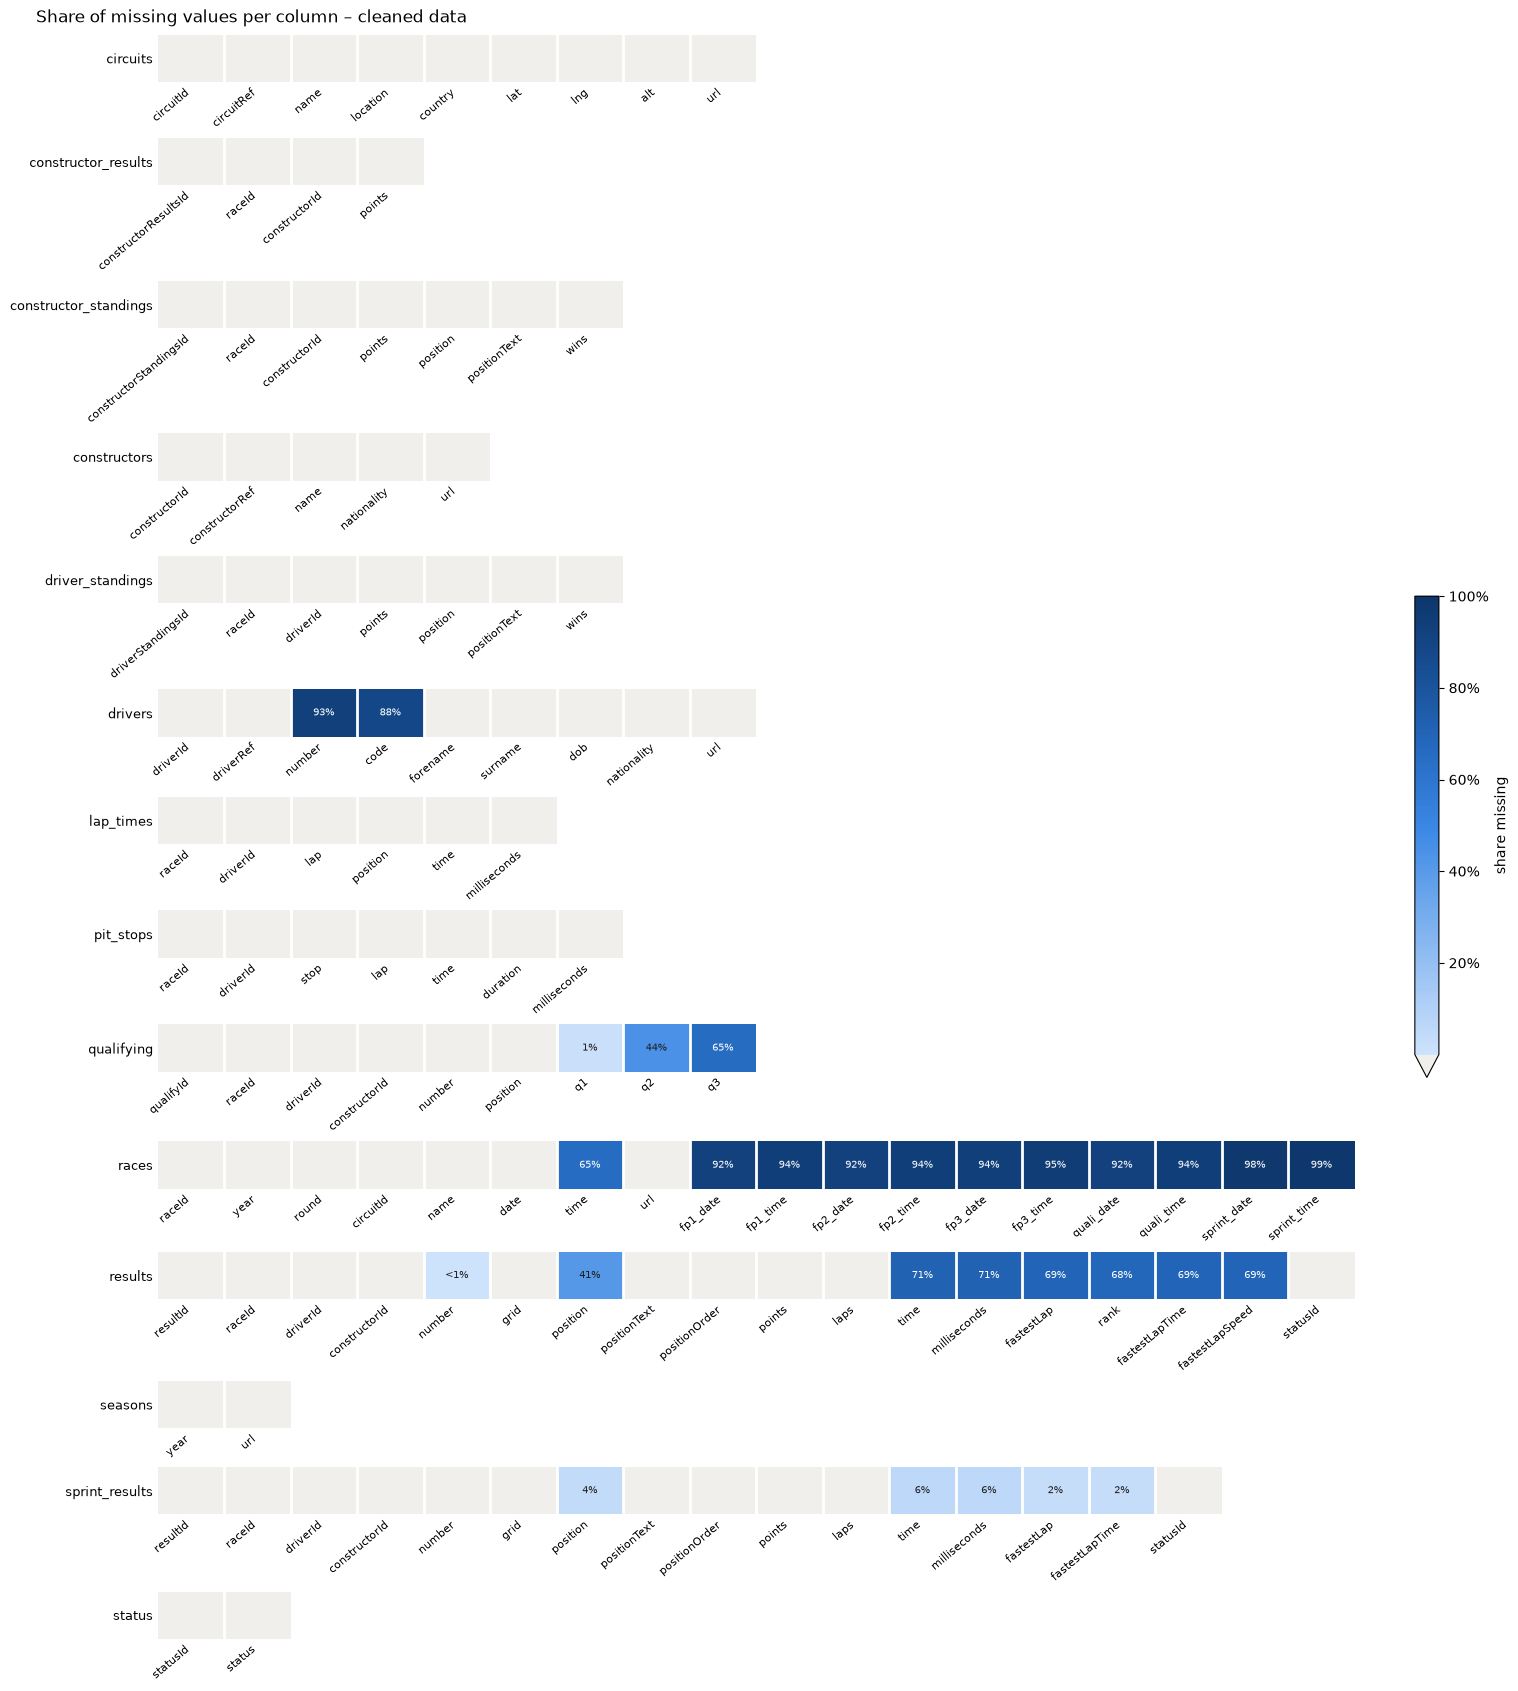

In [78]:
save_figure(plot_missing(clean, "Share of missing values per column – cleaned data"), "cleaning_missing_heatmap_clean");

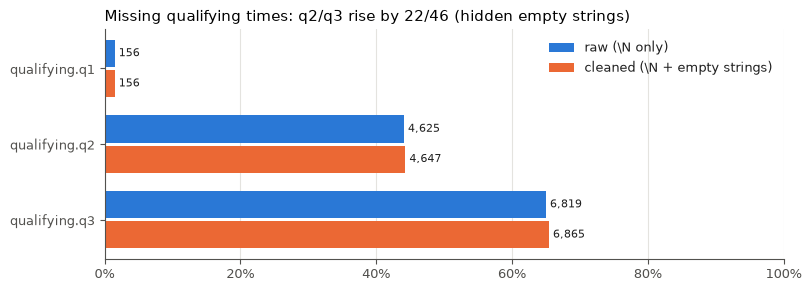

In [79]:
def plot_missing_change(raw_tables, clean_tables_, table, columns, title):
    """Share missing per column, raw vs. cleaned, as paired horizontal bars."""
    raw_share = raw_tables[table][columns].isna().mean()
    clean_share = clean_tables_[table][columns].isna().mean()
    fig, ax = plt.subplots(figsize=(8, 2.8), constrained_layout=True)
    y = range(len(columns))
    bars_raw = ax.barh([i - 0.2 for i in y], raw_share, height=0.36, color=BLUE, label="raw (\\N only)")
    bars_clean = ax.barh([i + 0.2 for i in y], clean_share, height=0.36, color=ORANGE,
                         label="cleaned (\\N + empty strings)")
    for bars, counts in [(bars_raw, raw_tables[table][columns].isna().sum()),
                         (bars_clean, clean_tables_[table][columns].isna().sum())]:
        ax.bar_label(bars, labels=[f"{c:,}" for c in counts], fontsize=8, color=INK, padding=3)
    ax.set_yticks(list(y), [f"{table}.{c}" for c in columns])
    ax.invert_yaxis()
    style_axes(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 1)
    ax.legend(frameon=False, fontsize=9, loc="upper right", labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_missing_change(raw, clean, "qualifying", ["q1", "q2", "q3"],
                                "Missing qualifying times: q2/q3 rise by 22/46 (hidden empty strings)"),
            "cleaning_missing_qualifying_before_after");

### Row accounting: raw `results` → entries table

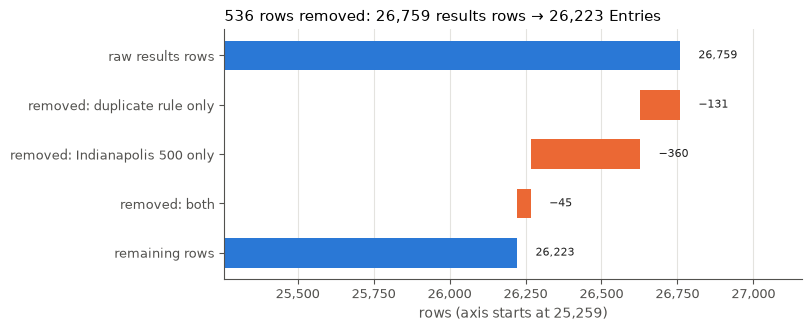

In [80]:
def plot_accounting(accounting, title):
    """Waterfall from raw rows to remaining rows; removals as floating bars."""
    start, end = accounting["raw results rows"], accounting["remaining rows"]
    removals = accounting[["removed: duplicate rule only", "removed: Indianapolis 500 only", "removed: both"]]
    labels = ["raw results rows", *removals.index, "remaining rows"]
    fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
    level = start
    ax.barh(0, start, color=BLUE, height=0.6)
    for i, (name, value) in enumerate(removals.items(), start=1):
        level -= value
        ax.barh(i, value, left=level, color=ORANGE, height=0.6)
        ax.text(level + value + 60, i, f"−{value:,}", va="center", fontsize=8, color=INK)
    ax.barh(len(labels) - 1, end, color=BLUE, height=0.6)
    for i, value in [(0, start), (len(labels) - 1, end)]:
        ax.text(value + 60, i, f"{value:,}", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(len(labels)), labels)
    ax.invert_yaxis()
    ax.set_xlim(start - 1_500, start + 400)  # zoomed: the removals are 2% of the rows
    style_axes(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.set_xlabel("rows (axis starts at 25,259)", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_accounting(accounting, "536 rows removed: 26,759 results rows → 26,223 Entries"), "cleaning_row_accounting");

### Seasons: raw base table vs. entries table

`season_summary` on the raw base table and on the entries table. Only seasons up to 1978
change (asserted); the table lists those seasons.

In [81]:
season_compare = pd.concat({"raw": seasons_raw, "entries": seasons_entries}, axis=1).swaplevel(axis=1)
season_compare = season_compare[["races", "rows", "entries", "podium_rows", "podium_share"]]
with pd.option_context("display.max_rows", 40):
    display(season_compare.loc[changed_seasons])

races         rows         entries         podium_rows          \
       raw entries  raw entries     raw entries         raw entries   
year                                                                  
1950     7       6  160     119     156     119          22      18   
1951     8       7  179     137     175     137          28      20   
1952     8       7  215     176     212     176          24      21   
1953     9       8  246     187     230     187          29      24   
1954     9       8  230     167     213     167          29      24   
1955     7       6  180     112     162     112          27      17   
1956     8       7  190     132     178     132          29      20   
1957     8       7  171     122     163     122          25      20   
1958    11      10  241     202     238     202          33      30   
1959     9       8  195     162     195     162          27      24   
1960    10       9  223     188     222     188          31      27   
1961     8       8  220     216     218     216          24      24   
1962     9       9  223     221     222     221          27      27   
1964    10      10  207     205     206     205          30      30   
1978    16      16  471     469     470     469          48      48   

     podium_share          
              raw entries  
year                       
1950        0.138   0.151  
1951        0.156   0.146  
1952        0.112   0.119  
1953        0.118   0.128  
1954        0.126   0.144  
1955        0.150   0.152  
1956        0.153   0.152  
1957        0.146   0.164  
1958        0.137   0.149  
1959        0.138   0.148  
1960        0.139   0.144  
1961        0.109   0.111  
1962        0.121   0.122  
1964        0.145   0.146  
1978        0.102   0.102

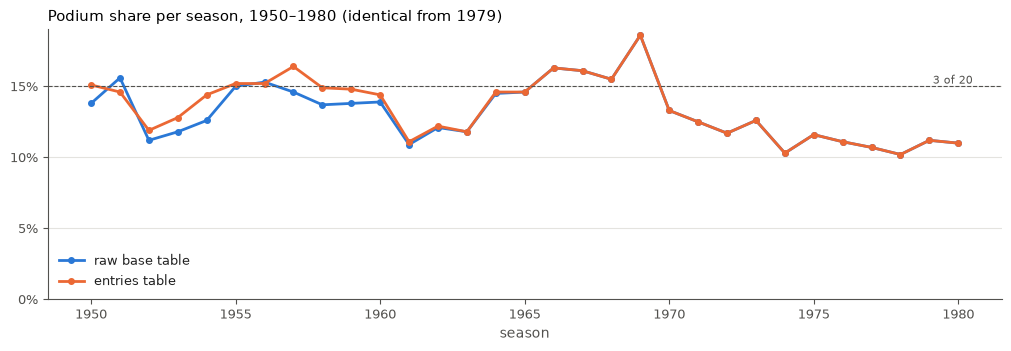

In [82]:
def plot_podium_share(seasons_before, seasons_after, years, title):
    """Podium share per season before and after, one axis, same measure."""
    before, after = seasons_before.loc[years], seasons_after.loc[years]
    fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
    ax.plot(before.index, before.podium_share, color=BLUE, linewidth=2, marker="o", markersize=4,
            label="raw base table")
    ax.plot(after.index, after.podium_share, color=ORANGE, linewidth=2, marker="o", markersize=4,
            label="entries table")
    ax.axhline(3 / 20, color=MUTED, linewidth=0.8, linestyle="--")
    ax.text(years.stop - 0.5, 3 / 20, "3 of 20", fontsize=8, color=MUTED, va="bottom", ha="right")
    style_axes(ax)
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(bottom=0)
    ax.set_xlabel("season", color=MUTED)
    ax.legend(frameon=False, fontsize=9, loc="lower left", labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_podium_share(seasons_raw, seasons_entries, range(1950, 1981),
                              "Podium share per season, 1950–1980 (identical from 1979)"), "cleaning_podium_share_before_after");

**What changed and why (before/after):**
- **Decision basis:** the before/after makes the effect of the generic cleaning (section 8, no ADR) and of the entries table (section 9; ADR 0002, ADR 0003) visible; every difference below is by design and asserted.
- **Cleaned tables:** row counts, primary and natural keys and the whole `fk_audit` are identical to raw, since generic cleaning removes no row. No empty string is left (raw: 2 columns). The only change in missing values is `qualifying.q2`/`q3`: +22/+46, the hidden empty strings now counted (bar chart; `missing_cells_%` of `qualifying` 12.3 → 12.4). `constructor_results` loses its 100%-empty `status` column (5 → 4 columns, missing share 20.0% → 0.0%).
- **Entries table:** 536 rows removed (waterfall: 131 duplicate rule only, 360 Indianapolis 500 only, 45 both), `nk_duplicates` 91 → 0. 15 seasons change, all 1950–1978: 1950–1960 lose one race each (the Indy 500) plus their duplicate groups; 1961, 1962, 1964 and 1978 lose only duplicate rows (2–4 rows each). From 1979 every season figure is identical (asserted).
- **Podium share 1950–1960 (line chart):** in most seasons it **rises** slightly (e.g. 1954 12.6% → 14.4%, 1957 14.6% → 16.4%), because the Indy field (14–24% of the rows, mean 36.8 per race) had a lower podium share than the other races. 1951 and 1956 fall a little (1951 15.6% → 14.6%), because their removed rows held a higher share of podium rows (Shared Cars). The Modeling Table (from 2003) is untouched by both rules.

<a id="sec-12"></a>
## 12. Reference data and Starters for the data-engineering questions

The three descriptive questions run on the entries table (not the Modeling Table); status
and laps may define populations (scope principle). Two hand-made reference files in
`data/reference/` carry the domain knowledge, each with a `reason` column:
- `nationality_country.csv`: one row per nationality–country pair, countries
  spelled as in `circuits.country`; nationalities without a circuit have no country.
- `status_mapping.csv`: every status among Starters 2014–2024 → finished /
  mechanical / accident_or_driver / other, with a `borderline` flag.

**Starter (descriptive):** `laps > 0`, or `grid > 0` and a status outside the
did-not-start group. `laps > 0` is evidence of a start whatever the status says; rows
with `grid == 0`, `laps == 0` and another status show no evidence of a start.

In [83]:
NATIONALITY_COUNTRY = REFERENCE / "nationality_country.csv"
STATUS_MAPPING = REFERENCE / "status_mapping.csv"
CATEGORIES = ["finished", "mechanical", "accident_or_driver", "other"]


def is_starter(rows):
    """Starter (descriptive): laps driven, or a grid slot without a did-not-start status."""
    return rows.laps.gt(0) | (rows.grid.gt(0) & ~rows.status.isin(DID_NOT_START))


def load_reference(path):
    """Hand-made reference CSV; empty cells are missing (e.g. a nationality without a circuit)."""
    return pd.read_csv(path)

In [84]:
nationality_country = load_reference(NATIONALITY_COUNTRY)
status_mapping = load_reference(STATUS_MAPPING)
starters = entries[is_starter(entries)]
starts_2014 = starters[starters.year.between(2014, 2024)]

assert len(starters) == 24_584 and starters.year.ge(2003).sum() == 8_934
no_evidence = entries[~is_starter(entries) & ~entries.status.isin(DID_NOT_START)]
assert len(no_evidence) == 56 and no_evidence.grid.eq(0).all() and no_evidence.laps.eq(0).all()

assert not nationality_country.duplicated(["nationality", "country"]).any()
assert set(nationality_country.nationality) == set(clean["drivers"].nationality)  # every nationality covered
mapped_countries = set(nationality_country.country.dropna())
assert mapped_countries <= set(clean["circuits"].country)  # every country spelled as in circuits
assert nationality_country.query("nationality in ['East German', 'Rhodesian']").country.isna().all()
assert set(nationality_country.query("nationality == 'American'").country) == {"USA", "United States"}

assert not status_mapping.status.duplicated().any()
assert set(status_mapping.status) == set(starts_2014.status)  # every status among Starters 2014–2024
assert len(status_mapping) == 65
assert status_mapping.category.isin(CATEGORIES).all()
assert set(status_mapping.query("borderline").status) == {
    "Retired", "Wheel", "Wheel nut", "Out of fuel", "Puncture", "Tyre",
    "Front wing", "Rear wing", "Undertray", "Damage", "Debris", "Seat"}
assert status_mapping.set_index("status").loc[["Withdrew", "Retired", "Puncture"], "category"].eq("other").all()
status_mapping.groupby(["category", "borderline"]).size().rename("statuses").to_frame()

statuses
category           borderline          
accident_or_driver False              4
                   True               5
finished           False              9
mechanical         False             36
                   True               1
other              False              4
                   True               6

**What changed and why (reference data):**
- **Starters:** 24,584 of 26,223 Entries (8,934 from 2003). Not Starters: 1,583 Entries with a did-not-start status and no laps, and 56 with no evidence of a start (`grid == 0`, `laps == 0`, another status); 24 Entries with a did-not-start status but `laps > 0` count as Starters.
- **`nationality_country.csv`:** covers all 43 nationality strings in `drivers`; every country is spelled as in `circuits.country` (asserted both ways). `American` maps to both `USA` and `United States`; dual nationalities to both countries; 15 nationalities have no circuit, among them `East German` and `Rhodesian` (reasons in the file).
- **`status_mapping.csv`:** covers exactly the 65 statuses among Starters 2014–2024 (asserted); 12 are flagged borderline with the call made for each (table above).

### Interval helpers

- **Wilson interval** for a rate k / n (95 %): stays inside [0, 1] and is reliable for
  small n and rates near 0 or 1, unlike the normal approximation.
- **Newcombe interval** (hybrid score, method 10) for the difference of two independent
  rates, built from the two Wilson intervals. A group counts as "changed" only if this
  interval excludes 0: non-overlap of the two Wilson intervals would be much
  stricter than a test of the difference.

In [85]:
Z_95 = 1.959964


def wilson(k, n, z=Z_95):
    """Wilson score interval (low, high) for the rate k / n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def newcombe(k1, n1, k2, n2, z=Z_95):
    """Difference p2 − p1 with its Newcombe hybrid-score interval (difference, low, high)."""
    p1, p2 = k1 / n1, k2 / n2
    (l1, u1), (l2, u2) = wilson(k1, n1, z), wilson(k2, n2, z)
    diff = p2 - p1
    return diff, diff - math.sqrt((p2 - l2) ** 2 + (u1 - p1) ** 2), diff + math.sqrt((u2 - p2) ** 2 + (p1 - l1) ** 2)

In [86]:
low, high = wilson(15, 20)
assert (round(low, 3), round(high, 3)) == (0.531, 0.888)  # worked example (computed by hand: 53–89 %)
assert math.isclose(wilson(0, 10)[0], 0, abs_tol=1e-12) and math.isclose(wilson(10, 10)[1], 1)
diff, low, high = newcombe(56, 70, 48, 80)  # Newcombe (1998), example (a): 56/70 vs. 48/80
assert (round(-diff, 4), round(-high, 4), round(-low, 4)) == (0.2, 0.0524, 0.3339)

<a id="sec-13"></a>
## 13. Question 1: front-row conversion by circuit, before and after 2014

**Question:** at which circuits is a front-row start most often converted into a podium,
and does that change from 2014?

**Definitions:**
- **Front-Row Start:** `grid ∈ {1, 2}`, no status filter.
- **Success:** Podium Finish (`positionOrder <= 3`), as the assignment asks. The win rate
  is one extra column, without interpretation.
- **Qualifying variant:** Qualifying Position 1–2 from real qualifying rows only (no qualifying
  fallback), without the six 2021–2022 sprint races, where qualifying did not set the race
  grid.

**Periods:** 2003–2013 vs. 2014–2024 (primary, both variants); 1979–2013 as a grid-only
sensitivity row.

**Multi-hop joins:** `results` → `races` (season, `circuitId`, sprint date) → `circuits`
(circuit name), and `results` ↔ `qualifying` on `(raceId, driverId)` for the Qualifying
Position (all in the entries table, plus the circuit join here).

In [87]:
FRONT_ROW = [1, 2]
Q1_PERIODS = {"2003–2013": (2003, 2013), "2014–2024": (2014, 2024)}
MIN_FRONT_ROW_STARTS = 10


def label_period(years, periods):
    """Period name per season; seasons outside every period get NaN."""
    out = pd.Series(pd.NA, index=years.index, dtype="string")
    for name, (start, end) in periods.items():
        out[years.between(start, end)] = name
    return out


def front_row_rows(entries, tables, variant, periods=Q1_PERIODS):
    """Front-row rows (by grid, or by real Qualifying Position outside 2021–2022 sprint races) with circuit and period."""
    circuits = tables["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"})
    rows = entries.merge(circuits, on="circuitId", how="left", validate="many_to_one")
    rows = rows.assign(period=label_period(rows.year, periods), podium=rows.positionOrder.le(3),
                       win=rows.positionOrder.eq(1))
    rows = rows[rows.period.notna()]
    if variant == "grid":
        return rows[rows.grid.isin(FRONT_ROW)].reset_index(drop=True)
    sprint_2021_2022 = tables["races"].query("sprint_date.notna() and year <= 2022").raceId
    keep = rows.has_qualifying_row & rows.qualifying_position.isin(FRONT_ROW) & ~rows.raceId.isin(sprint_2021_2022)
    return rows[keep].reset_index(drop=True)

In [88]:
q1_grid = front_row_rows(entries, clean, "grid")
q1_quali = front_row_rows(entries, clean, "qualifying")
q1_gap = q1_quali[~q1_quali.grid.isin(FRONT_ROW)]  # qualified on the front row, did not start from it
sprint_2021_2022 = clean["races"].query("sprint_date.notna() and year <= 2022").raceId

assert len(q1_grid) == 854 and q1_grid.raceId.nunique() == 428
assert q1_grid.groupby("raceId").size().value_counts().to_dict() == {2: 426, 1: 2}
assert q1_grid.period.value_counts().to_dict() == {"2014–2024": 454, "2003–2013": 400}
assert len(q1_quali) == 844 and not q1_quali.raceId.isin(sprint_2021_2022).any()
excluded_sprint_rows = entries[entries.qualifying_position.isin(FRONT_ROW) & entries.raceId.isin(sprint_2021_2022)]
assert len(excluded_sprint_rows) == 12
assert len(q1_gap) == 33 and q1_gap.podium.sum() == 9
assert len(front_row_rows(entries, clean, "grid", periods={"1979–2013": (1979, 2013)})) == 1_168

In [89]:
def rate_row(rows, outcome="podium"):
    """n, successes, rate and Wilson interval of one group (plus the win rate where present)."""
    n, k = len(rows), int(rows[outcome].sum())
    low, high = wilson(k, n)
    out = {"n": n, outcome: k, "rate": k / n, "ci_low": low, "ci_high": high}
    if "win" in rows:
        out["win_rate"] = rows.win.mean()
    return out


def rates_by(rows, by, outcome="podium"):
    """rate_row per group."""
    return pd.DataFrame({key: rate_row(group, outcome) for key, group in rows.groupby(by, sort=False)}).T


def difference_row(rates, before, after, outcome="podium"):
    """Newcombe difference after − before for two rows of a rates table."""
    b, a = rates.loc[before], rates.loc[after]
    diff, low, high = newcombe(b[outcome], b.n, a[outcome], a.n)
    return {"difference": diff, "ci_low": low, "ci_high": high}


q1_sensitivity = front_row_rows(entries, clean, "grid", periods={"1979–2013": (1979, 2013)})
q1_pooled = pd.concat({
    "grid": rates_by(q1_grid, "period"),
    "grid, sensitivity": rates_by(q1_sensitivity, "period"),
    "qualifying": rates_by(q1_quali, "period"),
})
q1_differences = pd.DataFrame({
    "grid 2003–2013 → 2014–2024": difference_row(q1_pooled.loc["grid"], "2003–2013", "2014–2024"),
    "grid 1979–2013 → 2014–2024": difference_row(
        pd.concat([q1_pooled.loc["grid, sensitivity"], q1_pooled.loc["grid"]]), "1979–2013", "2014–2024"),
    "qualifying 2003–2013 → 2014–2024": difference_row(q1_pooled.loc["qualifying"], "2003–2013", "2014–2024"),
}).T
display(q1_pooled.round(3))
q1_differences.round(3)

n  podium   rate  ci_low  ci_high  win_rate
grid              2003–2013   400.0   272.0  0.680   0.633    0.724     0.378
                  2014–2024   454.0   345.0  0.760   0.719    0.797     0.383
grid, sensitivity 1979–2013  1168.0   691.0  0.592   0.563    0.619     0.330
qualifying        2003–2013   400.0   269.0  0.672   0.625    0.717     0.378
                  2014–2024   444.0   329.0  0.741   0.698    0.780     0.378

,difference,ci_low,ci_high
grid 2003–2013 → 2014–2024,0.080,0.020,0.140
grid 1979–2013 → 2014–2024,0.168,0.118,0.215
qualifying 2003–2013 → 2014–2024,0.068,0.007,0.130


**Qualifying vs. grid (2003–2024):** podium rate of Front-Row Starts next to drivers who
qualified on the front row but did not start from it (grid penalty or a start from the
pit lane; the 2021–2022 sprint races are already excluded).

In [90]:
pd.DataFrame({
    "Front-Row Starts (grid 1–2)": rate_row(q1_grid),
    "qualified 1–2, started elsewhere": rate_row(q1_gap),
}).T.round(3)

,n,podium,rate,ci_low,ci_high,win_rate
Front-Row Starts (grid 1–2),854.0,617.0,0.722,0.692,0.751,0.381
"qualified 1–2, started elsewhere",33.0,9.0,0.273,0.151,0.442,0.091


**First half of the question:** circuits ranked by conversion rate within each period
(at least 10 Front-Row Starts in that period, grid variant), with Wilson intervals.

In [91]:
def circuit_rates(rows, minimum=MIN_FRONT_ROW_STARTS):
    """Conversion rate per circuit and period, circuits with at least `minimum` front-row rows."""
    rates = rates_by(rows, ["period", "circuit"])
    rates.index = rates.index.set_names(["period", "circuit"])
    return rates[rates.n >= minimum]


q1_circuits = circuit_rates(q1_grid)
top_circuits = {period: q1_circuits.loc[period].sort_values(["rate", "n"], ascending=False).head(8)
                for period in Q1_PERIODS}
pd.concat(top_circuits).round(3)

n  podium   rate  ci_low  \
          circuit                                                       
2003–2013 Circuit de Nevers Magny-Cours   12.0    11.0  0.917   0.646   
          Istanbul Park                   14.0    11.0  0.786   0.524   
          Circuit de Monaco               22.0    17.0  0.773   0.566   
          Autodromo Nazionale di Monza    22.0    17.0  0.773   0.566   
          Silverstone Circuit             22.0    16.0  0.727   0.518   
          Circuit de Spa-Francorchamps    18.0    13.0  0.722   0.491   
          Suzuka Circuit                  18.0    13.0  0.722   0.491   
          Hockenheimring                  14.0    10.0  0.714   0.454   
2014–2024 Suzuka Circuit                  18.0    16.0  0.889   0.672   
          Yas Marina Circuit              22.0    19.0  0.864   0.667   
          Circuit de Monaco               20.0    17.0  0.850   0.640   
          Circuit de Barcelona-Catalunya  22.0    18.0  0.818   0.615   
          Circuit de Spa-Francorchamps    22.0    18.0  0.818   0.615   
          Sochi Autodrom                  16.0    13.0  0.812   0.570   
          Circuit of the Americas         20.0    16.0  0.800   0.584   
          Autódromo José Carlos Pace      19.0    15.0  0.789   0.567   

                                          ci_high  win_rate  
          circuit                                            
2003–2013 Circuit de Nevers Magny-Cours     0.985     0.417  
          Istanbul Park                     0.924     0.500  
          Circuit de Monaco                 0.899     0.409  
          Autodromo Nazionale di Monza      0.899     0.455  
          Silverstone Circuit               0.868     0.318  
          Circuit de Spa-Francorchamps      0.875     0.389  
          Suzuka Circuit                    0.875     0.389  
          Hockenheimring                    0.883     0.429  
2014–2024 Suzuka Circuit                    0.969     0.444  
          Yas Marina Circuit                0.953     0.500  
          Circuit de Monaco                 0.948     0.400  
          Circuit de Barcelona-Catalunya    0.927     0.455  
          Circuit de Spa-Francorchamps      0.927     0.318  
          Sochi Autodrom                    0.934     0.312  
          Circuit of the Americas           0.919     0.400  
          Autódromo José Carlos Pace        0.915     0.421

In [92]:
def circuit_change(circuit_rates_table, periods=Q1_PERIODS, outcome="podium"):
    """Groups with enough rows in both periods: both rates and the Newcombe difference (after − before)."""
    before, after = (circuit_rates_table.loc[p] for p in periods)
    both = before.index.intersection(after.index)
    rows = []
    for circuit in both:
        b, a = before.loc[circuit], after.loc[circuit]
        diff, low, high = newcombe(b[outcome], b.n, a[outcome], a.n)
        rows.append({"circuit": circuit, "n_before": b.n, "rate_before": b.rate, "low_before": b.ci_low,
                     "high_before": b.ci_high, "n_after": a.n, "rate_after": a.rate, "low_after": a.ci_low,
                     "high_after": a.ci_high, "difference": diff, "diff_low": low, "diff_high": high,
                     "changed": low > 0 or high < 0})
    return pd.DataFrame(rows).set_index("circuit").sort_values("rate_after")


q1_change = circuit_change(q1_circuits)
q1_change_quali = circuit_change(circuit_rates(q1_quali))
assert len(q1_change) == 14
q1_change[["n_before", "rate_before", "n_after", "rate_after", "difference", "diff_low", "diff_high",
           "changed"]].round(3)

,n_before,rate_before,n_after,rate_after,difference,diff_low,diff_high,changed
circuit,,,,,,,,
Hungaroring,22.0,0.636,22.0,0.591,-0.045,-0.308,0.226,False
Bahrain International Circuit,18.0,0.667,24.0,0.667,0.000,-0.263,0.276,False
Albert Park Grand Prix Circuit,22.0,0.591,18.0,0.722,0.131,-0.159,0.386,False
Marina Bay Street Circuit,12.0,0.583,18.0,0.722,0.139,-0.182,0.444,False
Autodromo Nazionale di Monza,22.0,0.773,22.0,0.727,-0.045,-0.289,0.205,False
Silverstone Circuit,22.0,0.727,24.0,0.750,0.023,-0.221,0.269,False
Circuit Gilles Villeneuve,20.0,0.600,18.0,0.778,0.178,-0.115,0.429,False
Shanghai International Circuit,20.0,0.650,14.0,0.786,0.136,-0.176,0.393,False
Autódromo José Carlos Pace,22.0,0.591,19.0,0.789,0.199,-0.086,0.438,False


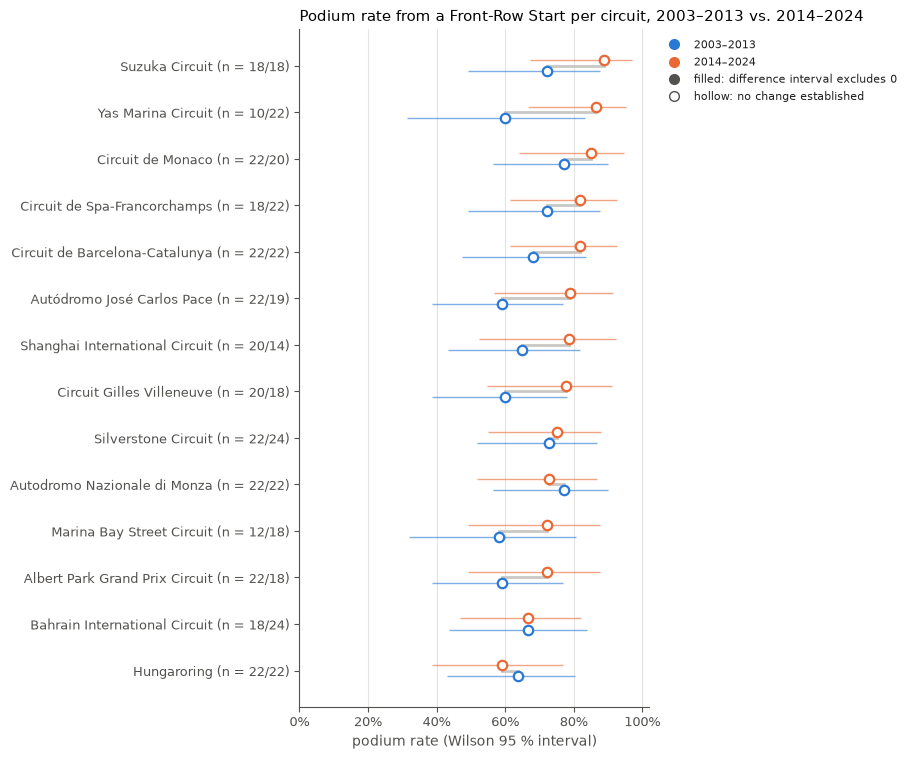

In [93]:
def plot_dumbbell(change, labels, title, xlabel, before_label, after_label, xmax=1.02):
    """Two rates per row with Wilson intervals; markers filled where the difference interval excludes 0."""
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(change) + 1.6), constrained_layout=True)
    y = range(len(change))
    for i, (_, row) in enumerate(change.iterrows()):
        ax.plot([row.rate_before, row.rate_after], [i, i], color="#c9c8c4", linewidth=2, zorder=1)
        for rate, low, high, color, dy in [(row.rate_before, row.low_before, row.high_before, BLUE, -0.12),
                                           (row.rate_after, row.low_after, row.high_after, ORANGE, 0.12)]:
            ax.errorbar(rate, i + dy, xerr=[[rate - low], [high - rate]], fmt="none", ecolor=color,
                        elinewidth=1, alpha=0.6, zorder=2)
            ax.scatter(rate, i + dy, s=46, color=color if row.changed else "white", edgecolor=color,
                       linewidth=1.6, zorder=3)
    ax.set_yticks(list(y), labels)
    style_axes(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel, color=MUTED)
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=BLUE, markersize=7, label=before_label),
               plt.Line2D([], [], marker="o", linestyle="", color=ORANGE, markersize=7, label=after_label),
               plt.Line2D([], [], marker="o", linestyle="", markerfacecolor=MUTED, markeredgecolor=MUTED,
                          markersize=7, label="filled: difference interval excludes 0"),
               plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=MUTED,
                          markersize=7, label="hollow: no change established")]
    ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1),
              labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_dumbbell(
    q1_change, [f"{c} (n = {int(b)}/{int(a)})" for c, b, a in zip(q1_change.index, q1_change.n_before, q1_change.n_after)],
    "Podium rate from a Front-Row Start per circuit, 2003–2013 vs. 2014–2024", "podium rate (Wilson 95 % interval)",
    "2003–2013", "2014–2024"), "q1_front_row_conversion_by_circuit");

**Ranking change:** Spearman correlation of the per-circuit rates between the periods,
with a bootstrap interval over races (1,000 resamples, races resampled within each
circuit and period, so every cell keeps its size).

In [94]:
def bootstrap_spearman(rows, circuits, n_boot=1_000, seed=42):
    """Spearman of the circuit rates before vs. after, with a 95 % bootstrap interval over races."""
    rng = np.random.default_rng(seed)
    per_race = rows[rows.circuit.isin(circuits)].groupby(["period", "circuit", "raceId"]).agg(
        podium=("podium", "sum"), n=("podium", "size"))
    cells = {key: (group.podium.to_numpy(), group.n.to_numpy())
             for key, group in per_race.groupby(level=["period", "circuit"])}
    before_p, after_p = list(Q1_PERIODS)

    def rho(sample):
        rates = {key: podium.sum() / n.sum() for key, (podium, n) in sample.items()}
        return stats.spearmanr([rates[(before_p, c)] for c in circuits], [rates[(after_p, c)] for c in circuits]).statistic

    observed = rho(cells)
    draws = []
    for _ in range(n_boot):
        sample = {}
        for key, (podium, n) in cells.items():
            idx = rng.integers(0, len(podium), len(podium))
            sample[key] = (podium[idx], n[idx])
        draws.append(rho(sample))
    low, high = np.nanpercentile(draws, [2.5, 97.5])
    return {"circuits": len(circuits), "spearman": observed, "ci_low": low, "ci_high": high}


pd.DataFrame({"grid": bootstrap_spearman(q1_grid, list(q1_change.index)),
              "qualifying": bootstrap_spearman(q1_quali, list(q1_change_quali.index))}).T.round(3)

,circuits,spearman,ci_low,ci_high
grid,14.0,0.303,-0.450,0.585
qualifying,14.0,0.549,-0.404,0.668


**Answer (question 1).** Converting a Front-Row Start into a podium became more common: 68.0 % (272 / 400) in 2003–2013 against 76.0 % (345 / 454) in 2014–2024, a difference of +8.0 points (95 % interval +2.0 to +14.0); by Qualifying Position the change is +6.8 points (+0.7 to +13.0). Per circuit the ranking is led by Magny-Cours, Istanbul, Monaco and Monza before 2014 and by Suzuka, Yas Marina, Monaco and Barcelona from 2014, but with 10–24 Front-Row Starts per circuit and period the Wilson intervals span about 30–50 points. For none of the 14 circuits with enough starts in both periods does the difference interval exclude 0 (with 14 circuits, about 0.7 false positives would be expected at the 5 % level), and the rankings are only weakly related (Spearman 0.30, bootstrap interval −0.45 to 0.59). So the overall rise is established, a circuit-level change is not: at this sample size it cannot be told apart from noise. The qualifying-vs-grid distinction matters: drivers who qualified on the front row but started elsewhere reached the podium in only 27 % of cases (9 / 33, interval 15–44 %), against 72 % of Front-Row Starts.

**Justification.**
- **Grain:** one row per front-row Entry (grid variant: 854 Front-Row Starts in 428 races, two per race except two races with one; qualifying variant: 844 rows). The rate is podiums per Front-Row Start; a circuit's rate pools all its races in a period.
- **Missingness:** `grid` and `positionOrder` are never missing. The qualifying variant uses real qualifying rows only (no qualifying fallback) and drops the 12 rows of the six 2021–2022 sprint races, where qualifying did not set the grid; qualifying data is complete from 2003, which is why both primary periods start there. Circuits with fewer than 10 Front-Row Starts in a period are left out of the circuit ranking, not imputed.
- **Cutoff:** the Front-Row Start (grid) is known before the race; the podium is the outcome being described. Status and laps are not used, so a front-row driver who later retires still counts in the denominator.
- **Sensitivity:** with 1979–2013 as the earlier period the rise looks twice as large (+16.8 points), because the 1980s and 1990s converted front rows less often (59.2 %); this attributes an older trend to "2014", so it stays a sensitivity row.

<a id="sec-14"></a>
## 14. Question 2: home advantage, controlled for grid

**Question:** do drivers reach the podium more often at their Home Race, or only because
home drivers start further up?

**Population:** Starters (as defined in section 12), all seasons; robustness on 2003–2024 and on drivers
with at least one possible Home Race. **Home Race:** the circuit's country is the country
of the driver's nationality (`nationality_country.csv`, by venue).

**Multi-hop joins:** `results` → `drivers` (nationality) → `nationality_country.csv`
(country) and `results` → `races` → `circuits` (venue country); `results` → `races` for
the season and decade; Grid Position harmonised as in the Modeling Table (`grid == 0` →
N, the Entries in that race).

**Steps from raw to controlled:** raw podium rate home vs. not home; logit
`podium ~ home`; logit `podium ~ home + C(grid_bin) + C(decade)`. All with cluster-robust
standard errors by `driverId`, because the same drivers appear in many races.

In [95]:
GRID_BINS = {"1": (1, 1), "2–3": (2, 3), "4–6": (4, 6), "7–10": (7, 10), "11+": (11, 99)}


def grid_bin_of(grid_position):
    """Grid bin label per harmonised Grid Position."""
    out = pd.Series(pd.NA, index=grid_position.index, dtype="string")
    for name, (low, high) in GRID_BINS.items():
        out[grid_position.between(low, high)] = name
    return out


def home_rows(starters, tables, mapping):
    """Starters with nationality, venue country, Home Race flag, harmonised grid, grid bin and decade."""
    venue = tables["circuits"][["circuitId", "country"]]
    rows = (starters
            .merge(tables["drivers"][["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
            .merge(venue, on="circuitId", how="left", validate="many_to_one"))
    home_pairs = pd.MultiIndex.from_frame(mapping.dropna(subset=["country"])[["nationality", "country"]])
    field_size = rows.raceId.map(entries.groupby("raceId").size())  # N: Entries in the race
    grid_position = rows.grid.where(rows.grid.gt(0), field_size)
    return rows.assign(
        home=pd.MultiIndex.from_frame(rows[["nationality", "country"]]).isin(home_pairs),
        can_race_at_home=rows.nationality.isin(mapping.dropna(subset=["country"]).nationality),
        grid_position=grid_position,
        grid_bin=pd.Categorical(grid_bin_of(grid_position), categories=list(GRID_BINS)),
        decade=rows.year // 10 * 10,
        podium=rows.positionOrder.le(3),
    )

In [96]:
q2 = home_rows(starters, clean, nationality_country)

assert len(q2) == 24_584 and not q2.duplicated(KEY).any()
assert q2.home.sum() == 1_917 and q2[q2.home].driverId.nunique() == 499
assert q2[["home", "grid_bin", "decade", "podium"]].notna().all().all()
field_size_q2 = q2.raceId.map(entries.groupby("raceId").size())
assert q2.grid_position.ge(1).all() and q2.grid_position.where(q2.grid.gt(0)).dropna().eq(q2.grid[q2.grid.gt(0)]).all()
above_field = q2[q2.grid_position.gt(field_size_q2)]  # numbering gaps in old grids, kept as recorded
assert len(above_field) == 53 and above_field.year.max() <= 1986
assert q2.query("grid == 0").grid_bin.eq("11+").all()  # Pit-Lane Starts at the back of the grid

In [97]:
def home_odds_ratio(rows, formula):
    """Logit with cluster-robust standard errors by driver; odds ratio of `home` with 95 % interval."""
    data = rows.assign(home=rows.home.astype(int), podium=rows.podium.astype(int),
                       grid_bin=rows.grid_bin.astype(str), decade=rows.decade.astype(str))
    fit = smf.logit(formula, data=data).fit(disp=False, cov_type="cluster",
                                            cov_kwds={"groups": data.driverId})
    low, high = fit.conf_int().loc["home"]
    return {"rows": int(fit.nobs), "home_rows": int(data.home.sum()), "drivers": data.driverId.nunique(),
            "odds_ratio": math.exp(fit.params["home"]), "ci_low": math.exp(low), "ci_high": math.exp(high),
            "p_value": fit.pvalues["home"]}


FULL = "podium ~ home + C(grid_bin, Treatment('1')) + C(decade)"
q2_raw_rates = rates_by(q2.assign(group=q2.home.map({True: "home", False: "not home"})), "group")
q2_models = pd.DataFrame({
    "1 raw: podium ~ home": home_odds_ratio(q2, "podium ~ home"),
    "2 controlled: + grid bin + decade": home_odds_ratio(q2, FULL),
    "robustness: 2003–2024": home_odds_ratio(q2[q2.year.ge(2003)], FULL),
    "robustness: drivers who can race at home": home_odds_ratio(q2[q2.can_race_at_home], FULL),
}).T
display(q2_raw_rates.round(3))
q2_models.round(3)

,n,podium,rate,ci_low,ci_high
not home,22667.0,3114.0,0.137,0.133,0.142
home,1917.0,224.0,0.117,0.103,0.132


,rows,home_rows,drivers,odds_ratio,ci_low,ci_high,p_value
1 raw: podium ~ home,24584.0,1917.0,685.0,0.831,0.697,0.991,0.039
2 controlled: + grid bin + decade,24584.0,1917.0,685.0,0.924,0.753,1.134,0.448
robustness: 2003–2024,8934.0,365.0,113.0,0.757,0.391,1.466,0.408
robustness: drivers who can race at home,22230.0,1917.0,639.0,0.933,0.763,1.141,0.500


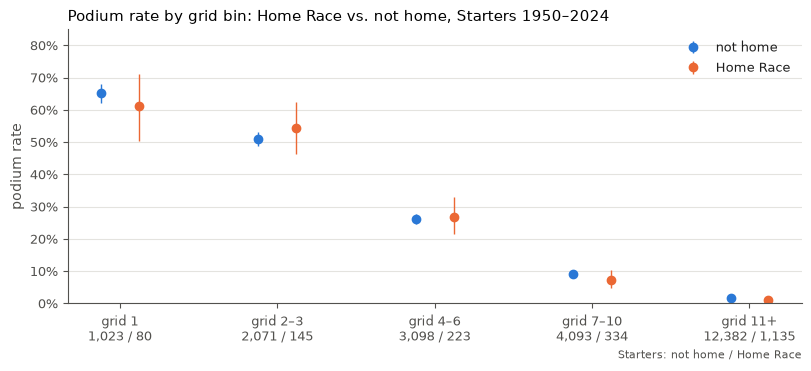

In [98]:
def plot_home_by_grid(rows, title):
    """Podium rate per grid bin, home vs. not home, paired points with Wilson intervals."""
    fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
    counts = {}
    for offset, (is_home, color, label) in zip([-0.12, 0.12], [(False, BLUE, "not home"), (True, ORANGE, "Home Race")]):
        rates = rates_by(rows[rows.home.eq(is_home)], "grid_bin").reindex(list(GRID_BINS))
        x = [i + offset for i in range(len(GRID_BINS))]
        ax.errorbar(x, rates.rate, yerr=[rates.rate - rates.ci_low, rates.ci_high - rates.rate], fmt="o",
                    color=color, ecolor=color, elinewidth=1, capsize=0, markersize=6, label=label)
        counts[is_home] = rates.n.astype(int)
    ax.set_xticks(range(len(GRID_BINS)),
                  [f"grid {b}\n{counts[False][b]:,} / {counts[True][b]:,}" for b in GRID_BINS])
    ax.text(1.0, -0.2, "Starters: not home / Home Race", transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
    style_axes(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 0.85)
    ax.set_ylabel("podium rate", color=MUTED)
    ax.legend(frameon=False, fontsize=9, loc="upper right", labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_home_by_grid(q2, "Podium rate by grid bin: Home Race vs. not home, Starters 1950–2024"),
            "q2_home_advantage_by_grid");

**Answer (question 2).** Without control, Home Races look like a *disadvantage*: 11.7 % of home Starters reach the podium against 13.7 % of the others (odds ratio 0.83, 95 % interval 0.70–0.99), partly because home Starters more often start from the back (59 % in grid bin 11+ against 55 %). After controlling for grid bin and decade, there is **no evidence of a home advantage**: odds ratio 0.92 (0.75–1.13), with standard errors clustered by driver. The robustness rows agree: 2003–2024 only 0.76 (0.39–1.47, 365 Home Races), drivers who can race at home only 0.93 (0.76–1.14). Within every grid bin the home and non-home podium rates lie close together with overlapping intervals (plot). This is an association, not a cause: the data cannot say whether home crowds help or hurt, only that a home race is not linked to more podiums once the starting position is known.

**Justification.**
- **Grain:** one row per Starter (24,584, all seasons); the same drivers appear in many races, hence the clustered standard errors (685 drivers; 499 of them have Home Races).
- **Missingness:** none in the model variables. Nationality is always set; 15 nationalities have no circuit and count as not home by definition (excluded in the last robustness row). Grid is harmonised (`grid == 0` → N, so Pit-Lane Starts fall into bin 11+). 53 Starters from 1950–1986 have a grid number above their race's Entry count (numbering gaps in old grids, e.g. F2 cars at the German GP); they are kept as recorded and all fall into bin 11+.
- **Cutoff:** nationality, venue and Grid Position are known before the race; the podium is the outcome. Status and laps only define the Starter population (scope principle).

<a id="sec-15"></a>
## 15. Question 3: mechanical retirements, 2014–2021 vs. 2022–2024

**Question:** which constructors retired most often for mechanical reasons, and did that
change with the 2022 regulations?

**Population and rate:** every race start (Starter as defined in section 12) in 2014–2024; numerator =
starts whose status maps to *mechanical* in `status_mapping.csv`. **Strict** counts the
*mechanical* category only; **broad** also counts every borderline status (Retired,
Wheel, Puncture, wings …) as mechanical. Constructors are plain `constructorId`s (baseline
only): renamed teams (Toro Rosso/AlphaTauri, Sauber/Alfa Romeo, Racing Point/Aston
Martin) appear as separate constructors.

**Multi-hop joins:** `results` → `status` (status text) → `status_mapping.csv`
(category); `results` → `constructors` (name); `results` → `races` (season).

In [99]:
Q3_PERIODS = {"2014–2021": (2014, 2021), "2022–2024": (2022, 2024)}
MIN_STARTS = 40


def retirement_rows(starts, tables, mapping):
    """Race starts with constructor name, period, status category and the strict/broad mechanical flags."""
    names = tables["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})
    rows = (starts
            .merge(mapping[["status", "category", "borderline"]], on="status", how="left", validate="many_to_one")
            .merge(names, on="constructorId", how="left", validate="many_to_one"))
    mechanical = rows.category.eq("mechanical")
    return rows.assign(period=label_period(rows.year, Q3_PERIODS), mechanical=mechanical,
                       mechanical_broad=mechanical | rows.borderline)

In [100]:
q3 = retirement_rows(starts_2014, clean, status_mapping)

assert len(q3) == 4_611 and not q3.duplicated(KEY).any()
assert q3.category.notna().all()  # every start has a category
assert q3.period.value_counts().to_dict() == {"2014–2021": 3_257, "2022–2024": 1_354}
assert q3.groupby("period").mechanical.sum().to_dict() == {"2014–2021": 298, "2022–2024": 76}
assert q3.groupby("period").mechanical_broad.sum().to_dict() == {"2014–2021": 369, "2022–2024": 94}

In [101]:
q3_pooled = pd.concat({definition: rates_by(q3, "period", outcome).rename(columns={outcome: "retirements"})
                       for definition, outcome in
                       [("strict", "mechanical"), ("broad", "mechanical_broad")]})
q3_pooled_diff = pd.DataFrame({
    definition: difference_row(q3_pooled.loc[definition], *Q3_PERIODS, outcome="retirements")
    for definition in ["strict", "broad"]
}).T
display(q3_pooled.round(3))
q3_pooled_diff.round(3)

n  retirements   rate  ci_low  ci_high
strict 2014–2021  3257.0        298.0  0.091   0.082    0.102
       2022–2024  1354.0         76.0  0.056   0.045    0.070
broad  2014–2021  3257.0        369.0  0.113   0.103    0.125
       2022–2024  1354.0         94.0  0.069   0.057    0.084

,difference,ci_low,ci_high
strict,-0.035,-0.051,-0.019
broad,-0.044,-0.061,-0.026


In [102]:
q3_constructors = rates_by(q3, ["period", "constructor"], "mechanical")
q3_constructors.index = q3_constructors.index.set_names(["period", "constructor"])
q3_ranked = q3_constructors[q3_constructors.n >= MIN_STARTS]
q3_change = circuit_change(q3_ranked, Q3_PERIODS, "mechanical").rename_axis("constructor")
pd.concat({period: q3_ranked.loc[period].sort_values("rate", ascending=False) for period in Q3_PERIODS}).round(3)

n  mechanical   rate  ci_low  ci_high
          constructor                                              
2014–2021 Lotus F1         75.0        13.0  0.173   0.104    0.274
          Toro Rosso      242.0        39.0  0.161   0.120    0.213
          McLaren         319.0        44.0  0.138   0.104    0.180
          Renault         200.0        27.0  0.135   0.094    0.189
          Sauber          200.0        22.0  0.110   0.074    0.161
          Red Bull        319.0        34.0  0.107   0.077    0.145
          Racing Point     76.0         7.0  0.092   0.045    0.178
          AlphaTauri       77.0         7.0  0.091   0.045    0.176
          Haas F1 Team    242.0        18.0  0.074   0.048    0.114
          Williams        319.0        23.0  0.072   0.049    0.106
          Alpine F1 Team   44.0         3.0  0.068   0.023    0.182
          Force India     199.0        13.0  0.065   0.039    0.109
          Manor Marussia   77.0         4.0  0.052   0.020    0.126
          Ferrari         319.0        16.0  0.050   0.031    0.080
          Mercedes        320.0        12.0  0.038   0.022    0.064
          Alfa Romeo      120.0         4.0  0.033   0.013    0.083
          Aston Martin     44.0         1.0  0.023   0.004    0.118
2022–2024 Alfa Romeo       88.0        11.0  0.125   0.071    0.210
          Alpine F1 Team  136.0        15.0  0.110   0.068    0.174
          AlphaTauri       88.0         6.0  0.068   0.032    0.141
          Williams        134.0         7.0  0.052   0.026    0.104
          Ferrari         135.0         7.0  0.052   0.025    0.103
          Haas F1 Team    135.0         6.0  0.044   0.021    0.094
          Mercedes        136.0         6.0  0.044   0.020    0.093
          RB F1 Team       48.0         2.0  0.042   0.012    0.140
          Aston Martin    134.0         5.0  0.037   0.016    0.084
          McLaren         136.0         5.0  0.037   0.016    0.083
          Red Bull        136.0         5.0  0.037   0.016    0.083
          Sauber           48.0         1.0  0.021   0.004    0.109

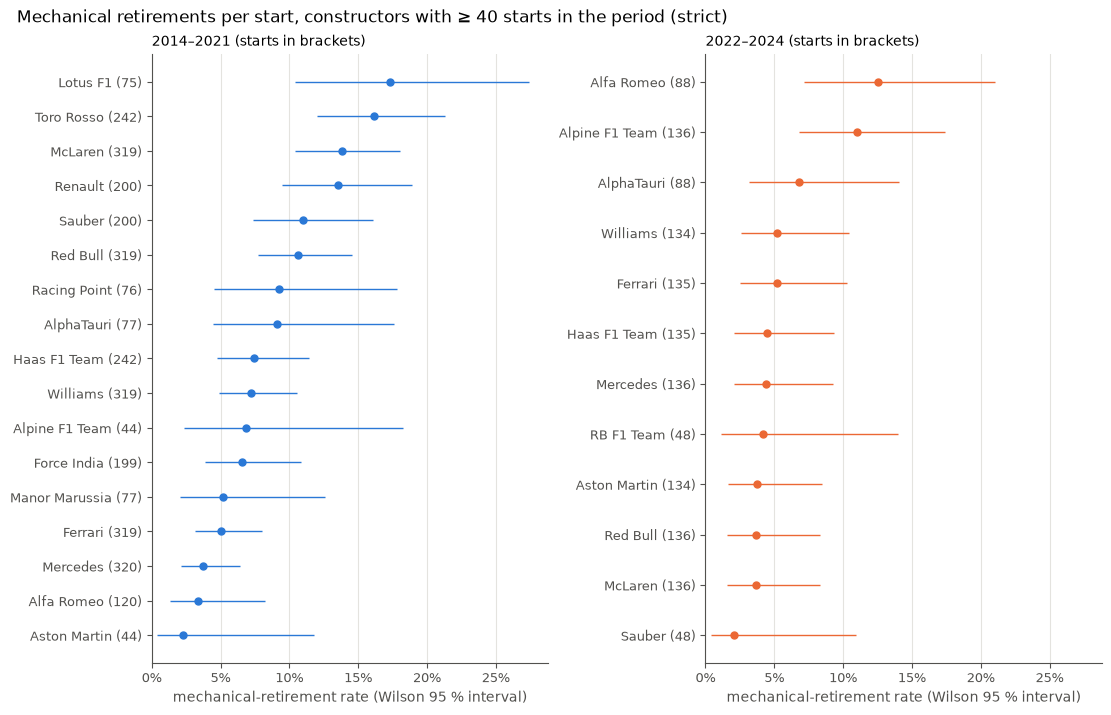

In [103]:
def plot_ranking(ranked, periods, title):
    """One dot plot per period on a shared x-axis: rate per group with Wilson intervals, sorted by rate."""
    sizes = [len(ranked.loc[p]) for p in periods]
    fig, axes = plt.subplots(1, len(periods), figsize=(11, 0.32 * max(sizes) + 1.6), sharex=True,
                             constrained_layout=True)
    for ax, period, color in zip(axes, periods, [BLUE, ORANGE]):
        table = ranked.loc[period].sort_values("rate")
        y = range(len(table))
        ax.errorbar(table.rate, list(y), xerr=[table.rate - table.ci_low, table.ci_high - table.rate], fmt="o",
                    color=color, ecolor=color, elinewidth=1, markersize=5)
        ax.set_yticks(list(y), [f"{c} ({int(n)})" for c, n in zip(table.index, table.n)], fontsize=8)
        style_axes(ax)
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.set_xlim(left=0)
        ax.set_title(f"{period} (starts in brackets)", loc="left", fontsize=10)
        ax.set_xlabel("mechanical-retirement rate (Wilson 95 % interval)", color=MUTED)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return fig


save_figure(plot_ranking(q3_ranked, list(Q3_PERIODS),
                         "Mechanical retirements per start, constructors with ≥ 40 starts in the period (strict)"),
            "q3_mechanical_ranking_by_period");

,n_before,rate_before,n_after,rate_after,difference,diff_low,diff_high,changed
constructor,,,,,,,,
Sauber,200.0,0.110,48.0,0.021,-0.089,-0.143,0.006,False
McLaren,319.0,0.138,136.0,0.037,-0.101,-0.148,-0.044,True
Red Bull,319.0,0.107,136.0,0.037,-0.070,-0.114,-0.015,True
Aston Martin,44.0,0.023,134.0,0.037,0.015,-0.083,0.065,False
Mercedes,320.0,0.038,136.0,0.044,0.007,-0.029,0.058,False
Haas F1 Team,242.0,0.074,135.0,0.044,-0.030,-0.077,0.026,False
Ferrari,319.0,0.050,135.0,0.052,0.002,-0.038,0.056,False
Williams,319.0,0.072,134.0,0.052,-0.020,-0.063,0.037,False
AlphaTauri,77.0,0.091,88.0,0.068,-0.023,-0.115,0.063,False


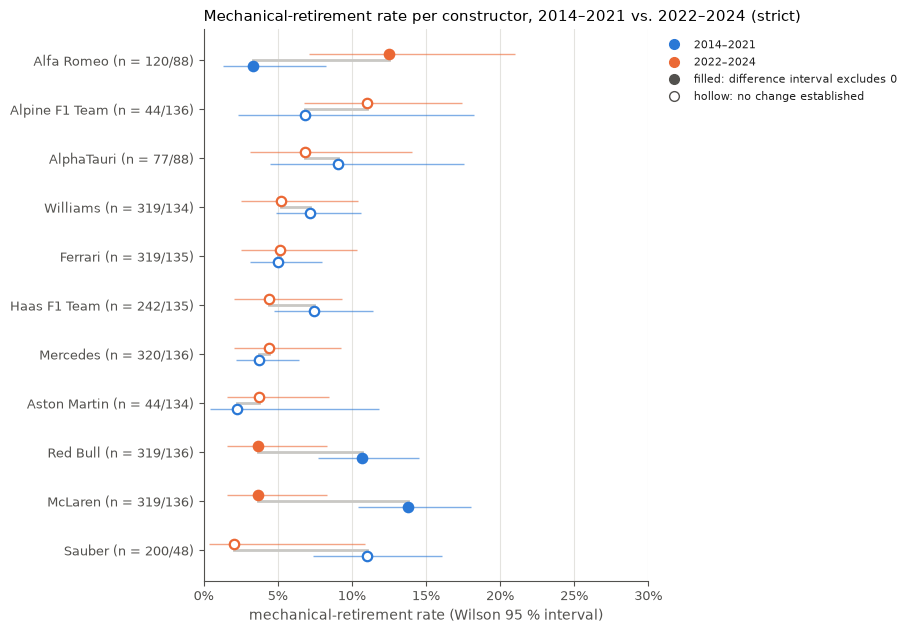

In [104]:
save_figure(plot_dumbbell(
    q3_change, [f"{c} (n = {int(b)}/{int(a)})" for c, b, a in zip(q3_change.index, q3_change.n_before, q3_change.n_after)],
    "Mechanical-retirement rate per constructor, 2014–2021 vs. 2022–2024 (strict)",
    "mechanical-retirement rate (Wilson 95 % interval)", "2014–2021", "2022–2024", xmax=0.3), "q3_mechanical_change");
q3_change[["n_before", "rate_before", "n_after", "rate_after", "difference", "diff_low", "diff_high", "changed"]].round(3)

**Sensitivity (broad definition) per constructor:** the same comparison with every
borderline status counted as mechanical.

In [105]:
q3_ranked_broad = rates_by(q3, ["period", "constructor"], "mechanical_broad")
q3_ranked_broad.index = q3_ranked_broad.index.set_names(["period", "constructor"])
q3_change_broad = circuit_change(q3_ranked_broad[q3_ranked_broad.n >= MIN_STARTS], Q3_PERIODS,
                                 "mechanical_broad").rename_axis("constructor")
pd.DataFrame({"strict": q3_change.changed, "broad": q3_change_broad.changed,
              "difference strict": q3_change.difference.round(3), "difference broad": q3_change_broad.difference.round(3)})

,strict,broad,difference strict,difference broad
constructor,,,,
Alfa Romeo,True,True,0.092,0.083
AlphaTauri,False,False,-0.023,-0.024
Alpine F1 Team,False,False,0.042,0.019
Aston Martin,False,False,0.015,0.014
Ferrari,False,False,0.002,0.008
Haas F1 Team,False,True,-0.030,-0.068
McLaren,True,True,-0.101,-0.123
Mercedes,False,False,0.007,-0.006
Red Bull,True,True,-0.070,-0.075


**Answer (question 3).** Mechanical retirements became rarer under the 2022 regulations: 9.1 % of starts (298 / 3,257) in 2014–2021 against 5.6 % (76 / 1,354) in 2022–2024, a difference of −3.5 points (95 % interval −5.1 to −1.9); with every borderline status counted as mechanical the drop is similar (11.3 % → 6.9 %, −4.4 points, −6.1 to −2.6). In 2014–2021 Lotus F1 (17.3 %), Toro Rosso (16.1 %), McLaren (13.8 %) and Renault (13.5 %) retired most often, Mercedes (3.8 %) and Ferrari (5.0 %) least among the teams with many starts; in 2022–2024 Alfa Romeo (12.5 %) and Alpine (11.0 %) lead, every other team is at 2–7 %. Of the 11 constructors present in both periods, three changed by their difference interval: McLaren (−10.1 points) and Red Bull (−7.0) became more reliable, Alfa Romeo less reliable (+9.2); with 11 comparisons about 0.55 false positives are expected at the 5 % level, and the broad definition flags the same three plus Haas. This is an association with the period, not a measured effect of the regulations: engines, team budgets and the field changed at the same time.

**Justification.**
- **Grain:** one row per race start (Starter as defined in section 12) in 2014–2024: 4,611 starts, 3,257 and 1,354 per period. First-lap retirements are starts and stay in the denominator; did-not-start rows and the 56 rows without evidence of a start are excluded.
- **Missingness:** `status` is never missing, and every status among these starts has a category in `status_mapping.csv` (asserted). The borderline calls (Retired, Wheel, Puncture, wings …) are tested by the broad definition; they do not change the direction.
- **Cutoff:** status is a post-race value; it is allowed here because the question is descriptive (scope principle), not a feature.
- **Unequal periods:** 8 seasons against 3, so the 2022–2024 rates rest on fewer starts and have wider intervals. Constructors are plain `constructorId`s: renamed teams appear separately (Toro Rosso/AlphaTauri, Sauber/Alfa Romeo, Racing Point/Aston Martin), and only constructors with ≥ 40 starts in a period are ranked or compared.

<a id="sec-16"></a>
## 16. Feature engineering

Five feature groups, which are also the ablation groups later. Every feature uses only
races **strictly before** the current one; the pre-race fields of the current race
(grid, qualifying) are known at the Prediction Cutoff. No sprint features.

| Group | Features | Rule |
|---|---|---|
| 1 Grid | `grid_position`, `grid_zero` | `grid == 0` → N (section 3) |
| 2 Qualifying | `qualifying_position`, `no_qualifying_row`, `grid_drop`, `q1_gap_pct` | qualifying fallback (section 2); `grid_drop` = Grid Position − Qualifying Position; `q1_gap_pct` = q1 ÷ fastest q1 of the race − 1, in % |
| 3 Driver form | `driver_podium_rate_5`, `driver_mean_rel_position_5`, `driver_entries_5` | last ≤ 5 Entries, `positionOrder / N` |
| 4 Constructor form | `constructor_podium_rate_5` | last ≤ 5 races within the current and previous season |
| 5 Standings | `driver_standing_position`, `driver_points_share`, `constructor_standing_position`, `constructor_points_share`, `standings_prev_season` | after the previous race of the season; round 1 → final standings of the previous season |

The feature functions take **targets** (the rows to describe, with their raw pre-race
fields) and a **history** (the dict of cleaned tables). Training, the time-machine test
and the inference function all call the same functions, so there is one implementation.
`constructorId` itself is an identifier, not a model feature (it only keys the
constructor form).

In [106]:
FEATURE_GROUPS = {
    "grid": ["grid_position", "grid_zero"],
    "qualifying": ["qualifying_position", "no_qualifying_row", "grid_drop", "q1_gap_pct"],
    "driver_form": ["driver_podium_rate_5", "driver_mean_rel_position_5", "driver_entries_5"],
    "constructor_form": ["constructor_podium_rate_5"],
    "standings": ["driver_standing_position", "driver_points_share", "constructor_standing_position",
                  "constructor_points_share", "standings_prev_season"],
}
MODEL_FEATURES = [feature for group in FEATURE_GROUPS.values() for feature in group]
FORM_WINDOW = 5
history = {**clean, "entries": entries}


def feature_targets(rows, history):
    """Raw pre-race fields per (raceId, driverId): date, season, grid, field size, qualifying position and q1 times."""
    entries_, qualifying = history["entries"], history["qualifying"]
    fields = entries_[KEY + ["date", "year", "round", "constructorId", "grid", "qualifying_position"]]
    return (rows[KEY].merge(fields, on=KEY, how="left", validate="one_to_one")
            .merge(qualifying[KEY + ["q1"]], on=KEY, how="left", validate="one_to_one")
            .assign(field_size=lambda d: d.raceId.map(entries_.groupby("raceId").size()),
                    race_fastest_q1=lambda d: d.raceId.map(qualifying.groupby("raceId").q1.min())))


def grid_and_qualifying(targets):
    """Groups 1 and 2: Grid Position, Qualifying fallback, grid_drop, q1_gap_pct."""
    grid_zero = targets.grid.eq(0)
    grid_position = targets.grid.where(~grid_zero, targets.field_size).astype("int64")
    no_qualifying_row = targets.qualifying_position.isna()
    qualifying_position = targets.qualifying_position.where(~no_qualifying_row, grid_position).astype("int64")
    return pd.DataFrame({
        "grid_position": grid_position, "grid_zero": grid_zero,
        "qualifying_position": qualifying_position, "no_qualifying_row": no_qualifying_row,
        "grid_drop": grid_position - qualifying_position,
        "q1_gap_pct": (targets.q1 / targets.race_fastest_q1 - 1) * 100,
    }, index=targets.index)


def window_stats(event_dates, event_values, target_dates, starts=None, window=FORM_WINDOW):
    """Sums of each value column and the count over the last ≤ `window` events strictly before each target date."""
    end = np.searchsorted(event_dates, target_dates, side="left")  # events strictly before the target
    start = np.maximum(end - window, 0 if starts is None else starts)
    start = np.minimum(start, end)
    cumulative = np.vstack([np.zeros(event_values.shape[1]), np.cumsum(event_values, axis=0)])
    return cumulative[end] - cumulative[start], end - start


def driver_form(targets, history):
    """Group 3: podium rate, mean positionOrder / N and number of Entries over the driver's last ≤ 5 Entries."""
    past = history["entries"]
    past = past.assign(podium=past.positionOrder.le(3).astype(float),
                       rel_position=past.positionOrder / past.raceId.map(past.groupby("raceId").size()))
    out = pd.DataFrame(index=targets.index, columns=FEATURE_GROUPS["driver_form"], dtype="float64")
    for driver, rows in targets.groupby("driverId"):
        events = past[past.driverId.eq(driver)].sort_values("date")
        sums, n = window_stats(events.date.to_numpy(), events[["podium", "rel_position"]].to_numpy(),
                               rows.date.to_numpy())
        with np.errstate(invalid="ignore", divide="ignore"):
            out.loc[rows.index, "driver_podium_rate_5"] = np.where(n > 0, sums[:, 0] / n, np.nan)
            out.loc[rows.index, "driver_mean_rel_position_5"] = np.where(n > 0, sums[:, 1] / n, np.nan)
        out.loc[rows.index, "driver_entries_5"] = n
    return out.astype({"driver_entries_5": "int64"})


def constructor_form(targets, history):
    """Group 4: podium Entries ÷ Entries over the constructor's last ≤ 5 races within the current and previous season."""
    per_race = (history["entries"].assign(podium=lambda d: d.positionOrder.le(3))
                .groupby(["constructorId", "raceId"]).agg(date=("date", "first"), year=("year", "first"),
                                                          podium=("podium", "sum"), n=("podium", "size"))
                .reset_index())
    out = pd.Series(np.nan, index=targets.index, name="constructor_podium_rate_5")
    for constructor, rows in targets.groupby("constructorId"):
        events = per_race[per_race.constructorId.eq(constructor)].sort_values("date")
        season_start = np.searchsorted(events.year.to_numpy(), rows.year.to_numpy() - 1, side="left")
        sums, n_races = window_stats(events.date.to_numpy(), events[["podium", "n"]].to_numpy(dtype=float),
                                     rows.date.to_numpy(), starts=season_start)
        with np.errstate(invalid="ignore", divide="ignore"):
            out[rows.index] = np.where(n_races > 0, sums[:, 0] / sums[:, 1], np.nan)
    return out.to_frame()


def standings_lookup_race(targets, races):
    """raceId whose standings are known before the race: previous round of the season, or the previous season's final race."""
    calendar = races[["raceId", "year", "round"]]
    previous_round = targets[["year", "round"]].assign(round=lambda d: d["round"] - 1).merge(
        calendar, on=["year", "round"], how="left").raceId.to_numpy()
    season_final = calendar.sort_values("round").groupby("year").raceId.last()
    previous_season = targets.year.sub(1).map(season_final).to_numpy()
    return pd.Series(np.where(targets["round"].eq(1), previous_season, previous_round), index=targets.index)


def standings(targets, history):
    """Group 5: championship position and points share of the leader before the race."""
    lookup = standings_lookup_race(targets, history["races"])
    out = pd.DataFrame({"standings_prev_season": targets["round"].eq(1)}, index=targets.index)
    for who, table, key in [("driver", "driver_standings", "driverId"), ("constructor", "constructor_standings", "constructorId")]:
        rows = history[table]
        rows = rows.assign(points_share=rows.points / rows.raceId.map(rows.groupby("raceId").points.max()))
        found = pd.DataFrame({"raceId": lookup, key: targets[key]}).merge(
            rows[["raceId", key, "position", "points_share"]], on=["raceId", key], how="left")
        found.index = targets.index
        out[f"{who}_standing_position"] = found.position.astype("float64")
        out[f"{who}_points_share"] = found.points_share
    debut = ~targets["round"].eq(1) & out.driver_standing_position.isna()
    out.loc[debut, "driver_points_share"] = 0.0  # mid-season debut: no points yet
    return out[FEATURE_GROUPS["standings"]]


def build_features(targets, history):
    """All five feature groups for the targets, from history strictly before each target race."""
    targets = targets.reset_index(drop=True)
    parts = [grid_and_qualifying(targets), driver_form(targets, history), constructor_form(targets, history),
             standings(targets, history)]
    return pd.concat([targets[KEY]] + parts, axis=1)[KEY + MODEL_FEATURES]

In [107]:
targets = feature_targets(modeling, history)
features = build_features(targets, history)
model_rows = modeling.merge(features, on=KEY, validate="one_to_one", suffixes=("", "_feature"))

assert len(features) == len(modeling) == 8_970 and list(features.columns) == KEY + MODEL_FEATURES
for column in ["grid_position", "grid_zero", "qualifying_position", "no_qualifying_row"]:  # same rules as the Modeling Table
    assert model_rows[column].equals(model_rows[f"{column}_feature"]), column
assert model_rows.grid_drop.eq(model_rows.grid_position - model_rows.qualifying_position).all()
assert model_rows.grid_drop[model_rows.no_qualifying_row].eq(0).all()
assert model_rows.q1_gap_pct.min() == 0 and model_rows.q1_gap_pct.isna().sum() == 148
assert model_rows.driver_entries_5.eq(0).sum() == 89  # F1 debuts
assert model_rows.driver_entries_5.lt(FORM_WINDOW).sum() == 426
assert model_rows.driver_podium_rate_5.isna().sum() == 89 and model_rows.driver_mean_rel_position_5.isna().sum() == 89
round_1 = model_rows["round"].eq(1)
assert round_1.sum() == 462 and model_rows.standings_prev_season.eq(round_1).all()
assert model_rows[round_1].driver_points_share.isna().sum() == 82  # no row in the previous season
assert model_rows[round_1].constructor_points_share.isna().sum() == 52
debut = ~round_1 & model_rows.driver_standing_position.isna()
assert debut.sum() == 144 and model_rows[debut].driver_points_share.eq(0).all()  # mid-season debuts
assert (~round_1 & model_rows.constructor_points_share.isna()).sum() == 32  # constructor gaps
assert model_rows[["driver_points_share", "constructor_points_share"]].stack().dropna().between(0, 1).all()

In [108]:
write_clean({"features": features}, CLEAN)
pd.testing.assert_frame_equal(load_clean(CLEAN, ["features"])["features"], features)
feature_summary = pd.DataFrame({
    "group": {f: g for g, cols in FEATURE_GROUPS.items() for f in cols},
    "missing": features[MODEL_FEATURES].isna().sum(),
    "min": features[MODEL_FEATURES].astype(float).min(), "median": features[MODEL_FEATURES].astype(float).median(),
    "max": features[MODEL_FEATURES].astype(float).max(),
})
feature_summary.round(3)

,group,missing,min,median,max
grid_position,grid,0,1.000,11.000,24.000
grid_zero,grid,0,0.000,0.000,1.000
qualifying_position,qualifying,0,1.000,11.000,24.000
no_qualifying_row,qualifying,0,0.000,0.000,1.000
grid_drop,qualifying,0,-8.000,0.000,23.000
q1_gap_pct,qualifying,148,0.000,1.225,44.782
driver_podium_rate_5,driver_form,89,0.000,0.000,1.000
driver_mean_rel_position_5,driver_form,89,0.045,0.540,1.000
driver_entries_5,driver_form,0,0.000,5.000,5.000
constructor_podium_rate_5,constructor_form,56,0.000,0.000,1.000


**What changed and why (features):**
- **15 features in five groups** for all 8,970 Modeling Table rows, stored as `data/clean/features.parquet`. Groups 1–2 apply exactly the Modeling Table rules (asserted equal); `grid_drop` is 0 wherever the qualifying fallback applies.
- **Missing values, as expected, left for the pipeline:** `q1_gap_pct` 148 (24 without a qualifying row, 124 without a q1 time); driver form 89 (F1 debuts, `driver_entries_5 = 0`; 426 rows have fewer than 5 earlier Entries); constructor form 56 (new `constructorId`s without a race in the current or previous season); standings: in round 1 (462 rows) the previous season's final standings fill in, leaving 82 driver and 52 constructor rows NaN (rookies, new IDs); in later rounds 144 mid-season debuts get `driver_points_share = 0` with position NaN, and 32 constructor gaps stay NaN.
- **Strictly before the race:** form windows end at the last Entry dated before the race (`searchsorted`, `side="left"`), standings come from the previous round or the previous season's final race. The time-machine test below checks this independently.

### Leakage guards

1. **Whitelist:** the model may only see the 15 features listed here by name; the list is
   written out, not derived, so a new column cannot slip in.
2. **Blacklist:** no post-race column (result, status, points, laps, times, fastest lap)
   and no target column is among the features.
3. **Time-machine test:** for 5 races, recompute the features from history **truncated
   before the race** (entries, standings, qualifying and the calendar of earlier races
   only; for the race itself only its pre-race fields) and compare with the features
   computed on the full data. Any use of the current or a later race would make them
   differ. The 5 races cover a season opener (round-1 fallback), the Force India restart
   (2018 Belgium), a race with an F1 debut, and one race each in validation and test.

In [109]:
FEATURE_WHITELIST = [
    "grid_position", "grid_zero", "qualifying_position", "no_qualifying_row", "grid_drop", "q1_gap_pct",
    "driver_podium_rate_5", "driver_mean_rel_position_5", "driver_entries_5", "constructor_podium_rate_5",
    "driver_standing_position", "driver_points_share", "constructor_standing_position",
    "constructor_points_share", "standings_prev_season",
]
TARGET_COLUMNS = ["podium", "positionOrder"]
assert MODEL_FEATURES == FEATURE_WHITELIST
assert not set(MODEL_FEATURES) & (set(POST_RACE) | set(TARGET_COLUMNS) | set(outcomes.columns))


def truncated_history(history, race_id):
    """History as it was before a race: earlier races only, plus the race's own qualifying (pre-race)."""
    race_date = history["races"].set_index("raceId").date[race_id]
    earlier = set(history["races"].raceId[history["races"].date.lt(race_date)])
    out = {name: table[table.raceId.isin(earlier)] for name, table in history.items()
           if name in ["entries", "driver_standings", "constructor_standings", "races"]}
    out["qualifying"] = history["qualifying"][history["qualifying"].raceId.isin(earlier | {race_id})]
    return out


def time_machine(race_id, history, features):
    """Features of one race recomputed from truncated history, compared with the full computation."""
    rows = targets[targets.raceId.eq(race_id)]
    replay = build_features(rows, truncated_history(history, race_id)).set_index(KEY)[MODEL_FEATURES]
    full = features.set_index(KEY).loc[replay.index, MODEL_FEATURES]
    same = np.isclose(replay.astype(float), full.astype(float), equal_nan=True)
    return {"raceId": race_id, "rows": len(replay), "cells": same.size, "cells_equal": int(same.sum())}


races_by = clean["races"].set_index(["year", "name"]).raceId
debut_race = targets.loc[features.driver_entries_5.eq(0) & targets.year.between(2010, 2019), "raceId"].iloc[0]
TIME_MACHINE_RACES = {
    "season opener 2008": races_by[(2008, "Australian Grand Prix")],
    "Force India restart 2018": races_by[(2018, "Belgian Grand Prix")],
    "race with an F1 debut": debut_race,
    "validation 2021": races_by[(2021, "Hungarian Grand Prix")],
    "test 2024": races_by[(2024, "Abu Dhabi Grand Prix")],
}
time_machine_result = pd.DataFrame({name: time_machine(race, history, features)
                                    for name, race in TIME_MACHINE_RACES.items()}).T
assert time_machine_result.cells_equal.eq(time_machine_result.cells).all()
time_machine_result

,raceId,rows,cells,cells_equal
season opener 2008,18,22,330,330
Force India restart 2018,1001,20,300,300
race with an F1 debut,337,24,360,360
validation 2021,1062,20,300,300
test 2024,1144,20,300,300


**Negative control:** the same comparison with history that still contains the race
itself and everything after it, but computed *without* the strictly-before rule (a
rolling window that includes the current race), must differ. This shows the test can
fail.

In [110]:
def leaky_driver_podium_rate(rows, history):
    """Deliberately wrong: driver podium rate over the last 5 Entries *including* the current race."""
    past = history["entries"].sort_values("date")
    rate = past.groupby("driverId").positionOrder.transform(lambda s: s.le(3).rolling(FORM_WINDOW, 1).mean())
    return rows.merge(past[KEY].assign(leaky=rate), on=KEY, how="left").leaky


control_race = TIME_MACHINE_RACES["validation 2021"]
control_rows = targets[targets.raceId.eq(control_race)]
leaky = leaky_driver_podium_rate(control_rows, history).to_numpy()
honest = build_features(control_rows, truncated_history(history, control_race)).driver_podium_rate_5.to_numpy()
assert not np.isclose(leaky, honest, equal_nan=True).all()
print(f"leaky vs. honest driver_podium_rate_5 differ in {int((~np.isclose(leaky, honest, equal_nan=True)).sum())} "
      f"of {len(honest)} rows")

leaky vs. honest driver_podium_rate_5 differ in 6 of 20 rows


**What changed and why (leakage guards):**
- **Whitelist and blacklist:** the 15 model features equal the written-out whitelist; none is a post-race column, a target column or a column of the outcomes frame (asserted).
- **Time-machine test:** for all 5 races (season opener 2008, Belgium 2018 with the Force India restart, Bahrain 2010 with F1 debuts, Hungary 2021, Abu Dhabi 2024) every one of the 1,590 feature cells recomputed from truncated history equals the full computation. So no feature uses the current or a later race.
- **The test can fail:** a deliberately leaky driver podium rate (window including the current race) differs from the honest one in 6 of 20 rows of the 2021 race.

<a id="sec-17"></a>
## 17. Feature EDA (train only, 2003–2019)

All plots and statistics in this section use the 6,831 training rows only, so nothing
about validation or test shapes the feature choice.

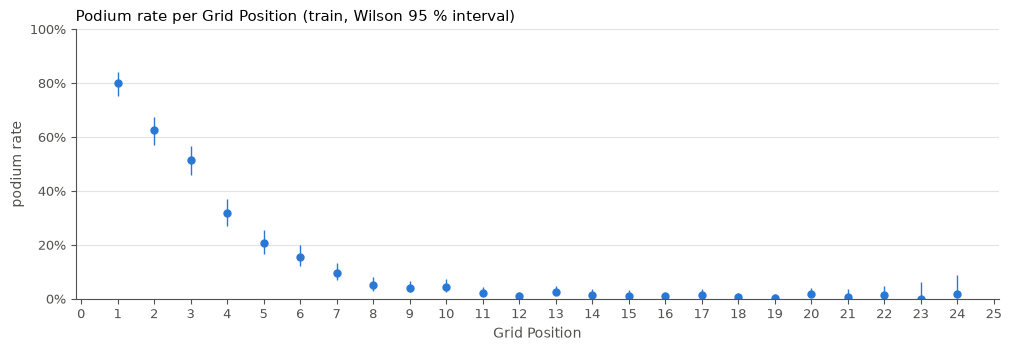

In [111]:
train_rows = model_rows[model_rows.split.eq("train")]
assert len(train_rows) == 6_831 and train_rows.year.between(2003, 2019).all()


def plot_rate_by_value(rows, column, title, values=None, xlabel=None):
    """Podium rate per value of a discrete feature, with Wilson intervals."""
    rates = rates_by(rows, column).sort_index()
    if values is not None:
        rates = rates.reindex(values).dropna()
    fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
    ax.errorbar(rates.index.astype(float), rates.rate, yerr=[rates.rate - rates.ci_low, rates.ci_high - rates.rate],
                fmt="o", color=BLUE, ecolor=BLUE, elinewidth=1, markersize=5)
    style_axes(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel or column, color=MUTED)
    ax.set_ylabel("podium rate", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11)
    return fig, rates


fig, grid_rates = plot_rate_by_value(train_rows, "grid_position", "Podium rate per Grid Position (train, Wilson 95 % interval)",
                                     xlabel="Grid Position")
fig.axes[0].xaxis.set_major_locator(MultipleLocator(1))
save_figure(fig, "features_podium_rate_by_grid");

,ρ with podium
qualifying_position,-0.495
grid_position,-0.493
driver_standing_position,-0.475
constructor_standing_position,-0.445
driver_mean_rel_position_5,-0.440
q1_gap_pct,-0.400
grid_zero,-0.026
no_qualifying_row,-0.024
standings_prev_season,-0.000
grid_drop,0.084


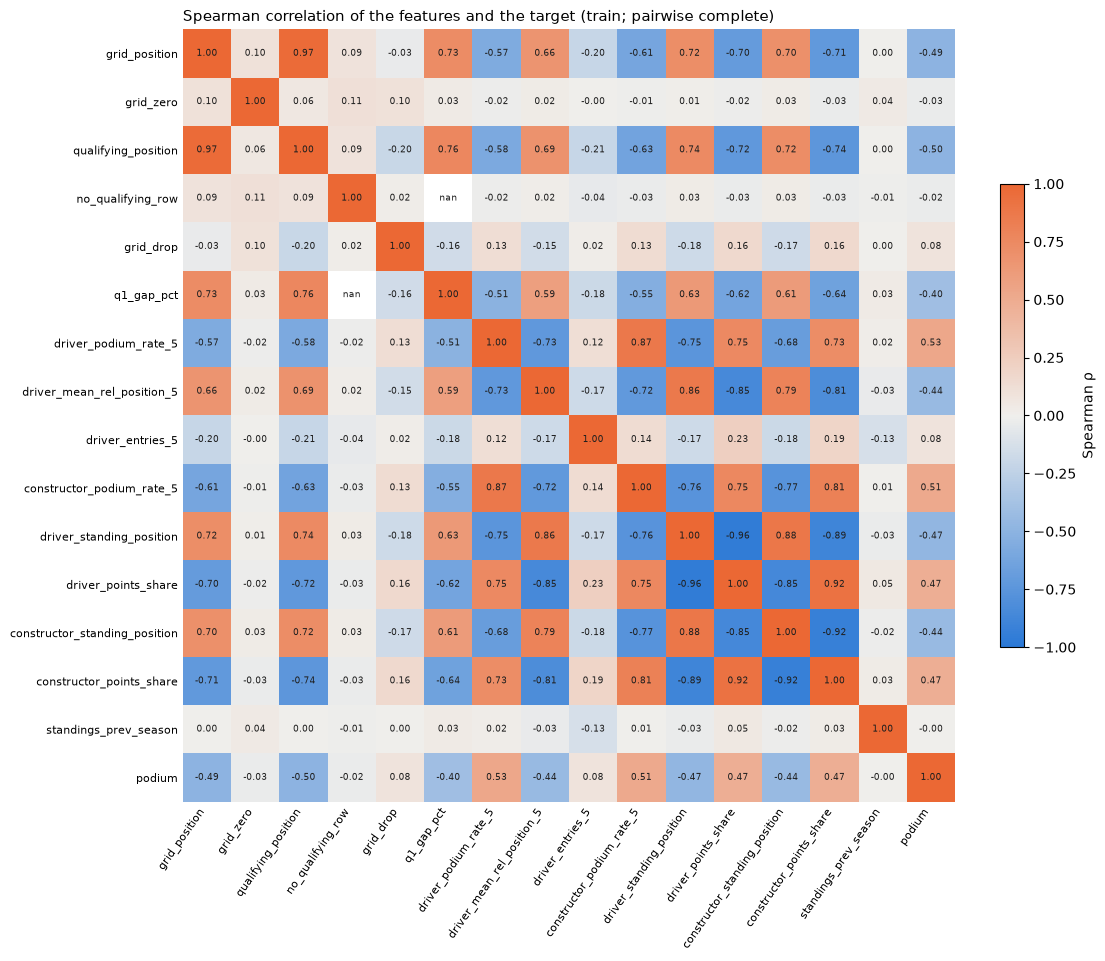

In [112]:
SEQ_DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", [BLUE, "#f0efec", ORANGE])


def plot_spearman(rows, columns, title):
    """Spearman correlation matrix as an annotated heatmap (blue negative, orange positive)."""
    corr = rows[columns].astype(float).corr("spearman")
    fig, ax = plt.subplots(figsize=(11, 9.5), constrained_layout=True)
    image = ax.imshow(corr, cmap=SEQ_DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(columns)), columns, rotation=55, ha="right", fontsize=8)
    ax.set_yticks(range(len(columns)), columns, fontsize=8)
    for i in range(len(columns)):
        for j in range(len(columns)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, shrink=0.6, label="Spearman ρ")
    ax.set_title(title, loc="left", fontsize=11)
    return fig, corr


fig, spearman_train = plot_spearman(train_rows, MODEL_FEATURES + ["podium"],
                                    "Spearman correlation of the features and the target (train; pairwise complete)")
save_figure(fig, "features_spearman_matrix");
spearman_train["podium"].drop("podium").sort_values().round(3).rename("ρ with podium").to_frame()

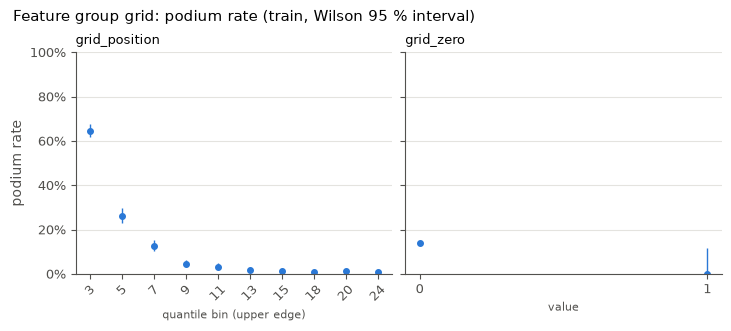

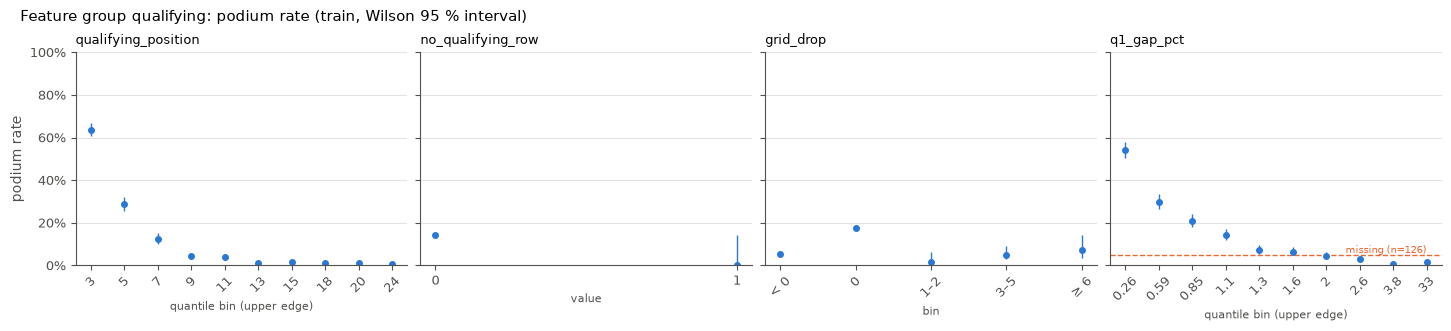

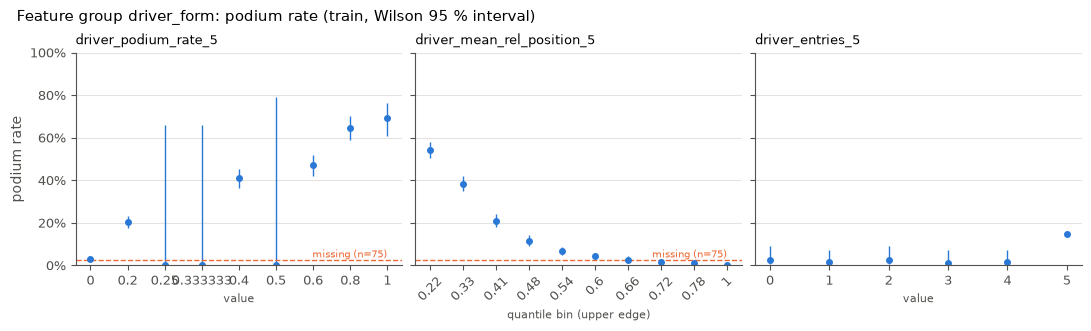

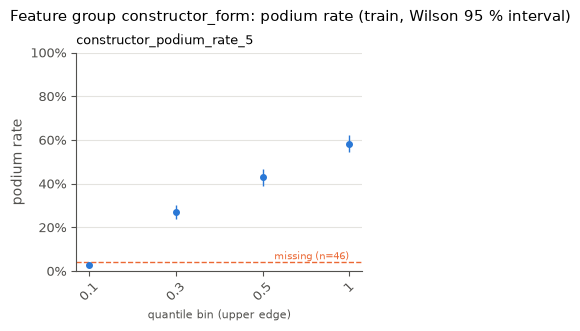

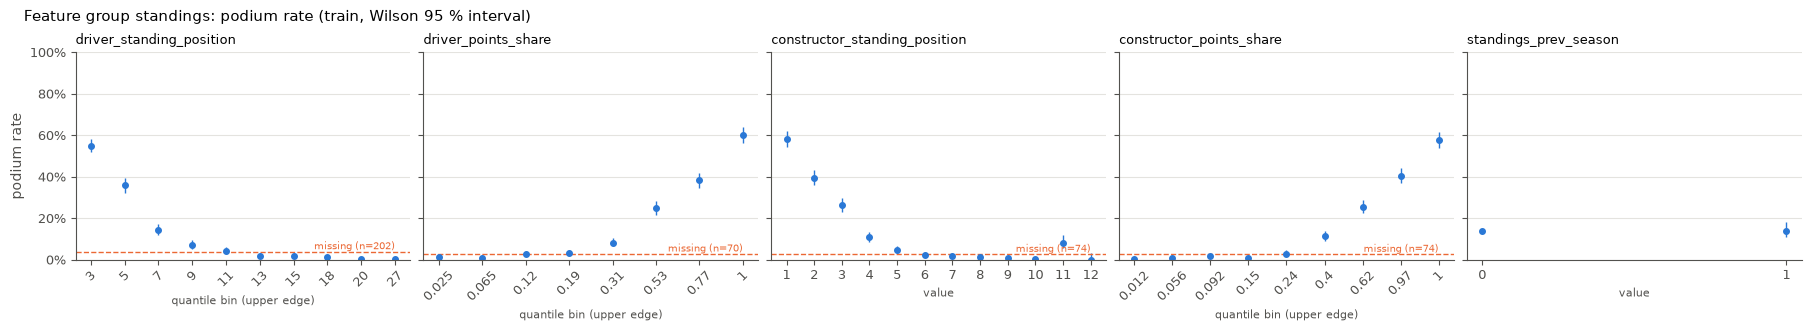

In [113]:
FIXED_BINS = {"grid_drop": ([-np.inf, -1, 0, 2, 5, np.inf], ["< 0", "0", "1–2", "3–5", "≥ 6"])}


def plot_group(rows, group, columns, n_bins=10):
    """One panel per feature of a group: podium rate per value (discrete), fixed bins, or quantile bins (continuous)."""
    fig, axes = plt.subplots(1, len(columns), figsize=(3.6 * len(columns), 3.2), sharey=True, constrained_layout=True,
                             squeeze=False)
    for ax, column in zip(axes[0], columns):
        values = rows[column]
        if column in FIXED_BINS:
            edges, labels = FIXED_BINS[column]
            binned = pd.cut(values, edges, labels=False)
        elif values.nunique() <= 12:
            binned = values.astype(float)
            labels = None
        else:
            binned = pd.qcut(values, n_bins, duplicates="drop")
            labels = [f"{interval.right:.2g}" for interval in binned.cat.categories]
            binned = binned.cat.codes.where(values.notna())
        rates = rates_by(rows.assign(bin=binned).dropna(subset=["bin"]), "bin").sort_index()
        x = range(len(rates))
        ax.errorbar(list(x), rates.rate, yerr=[rates.rate - rates.ci_low, rates.ci_high - rates.rate], fmt="o",
                    color=BLUE, ecolor=BLUE, elinewidth=1, markersize=4)
        ax.set_xticks(list(x), labels if labels else [f"{v:g}" for v in rates.index], fontsize=7,
                      rotation=45 if labels else 0)
        missing = rows[values.isna()]
        if len(missing):
            ax.axhline(missing.podium.mean(), color=ORANGE, linewidth=1, linestyle="--")
            ax.text(len(rates) - 1, missing.podium.mean(), f"missing (n={len(missing)})", fontsize=7, color=ORANGE,
                    ha="right", va="bottom")
        style_axes(ax)
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.set_ylim(0, 1)
        ax.set_title(column, loc="left", fontsize=9)
        ax.set_xlabel("bin" if column in FIXED_BINS else "value" if not labels else "quantile bin (upper edge)",
                      color=MUTED, fontsize=8)
    axes[0][0].set_ylabel("podium rate", color=MUTED)
    fig.suptitle(f"Feature group {group}: podium rate (train, Wilson 95 % interval)", x=0.01, ha="left", fontsize=11)
    return fig


for group, columns in FEATURE_GROUPS.items():
    save_figure(plot_group(train_rows, group, columns), f"features_group_{group}")

**Observations (train):**
- **Grid Position** is the strongest single signal and strongly non-linear: 80 % podium rate from grid 1, 62 % from 2, 51 % from 3, 32 % from 4, then below 10 % from grid 7 and close to 0 from grid 11. A linear model on the raw position will miss part of that curve; the tree model and the NN can follow it.
- **Spearman with the target:** driver podium rate 0.53, constructor podium rate 0.51, Qualifying Position −0.50, Grid Position −0.49, standings ±0.44–0.47, q1 gap −0.40. The flags (`grid_zero`, `no_qualifying_row`, `standings_prev_season`) and `driver_entries_5` are close to 0 overall but mark small groups: none of the 29 `grid_zero` rows and none of the 23 `no_qualifying_row` rows reaches the podium, and drivers with fewer than 5 earlier Entries reach it in 1–3 % of cases against 14.8 %.
- **`grid_drop`:** 0 for 73 % of rows (17.3 % podium); negative (started ahead of the qualifying place because others were penalised) 5.5 %; positive (penalised) 1.8–7.4 %. The relation is not monotone, so it adds information the two positions alone do not show linearly.
- **Missing values carry information:** rows with missing `q1_gap_pct`, form or standings reach the podium far less often than the average (dashed lines in the group plots), which supports keeping missing indicators in the pipeline.

**Collinearity:** Grid Position and Qualifying Position ρ = 0.97; driver standing position and points share ρ = −0.96, constructor ρ = −0.92; driver and constructor podium rate ρ = 0.87. Within a group the features are close to redundant, so single-feature importance will understate them; that is why permutation importance and ablation also run per group. For the logistic regression, the regularisation keeps the coefficients stable; they are not interpreted one by one.

**Justification per feature:**

| Feature | Why it is in the model |
|---|---|
| `grid_position` | Evidence: steepest podium-rate curve (plot above); assignment's own front-row framing |
| `grid_zero` | Evidence: 0 podiums from a Pit-Lane Start in train; marks the `grid == 0` harmonisation |
| `qualifying_position` | Hypothesis: pace before penalties; differs from the Grid Position in 27 % of train rows |
| `no_qualifying_row` | Evidence: 0 podiums in 23 train rows; marks the qualifying fallback |
| `grid_drop` | Evidence: non-monotone podium rate by drop; penalties hit fast cars too |
| `q1_gap_pct` | Evidence: podium rate falls from 54 % in the fastest decile to about 1 %; pace beyond the rank |
| `driver_podium_rate_5` | Evidence: ρ = 0.53, the strongest form signal |
| `driver_mean_rel_position_5` | Hypothesis: finishing level below the podium, independent of field size |
| `driver_entries_5` | Evidence: drivers with < 5 earlier Entries rarely reach the podium; makes partial windows visible |
| `constructor_podium_rate_5` | Evidence: ρ = 0.51; car performance within the time limit |
| `driver_standing_position`, `driver_points_share` | Evidence: ρ ≈ ±0.47; season-long strength, not only the last 5 races |
| `constructor_standing_position`, `constructor_points_share` | Evidence: ρ ≈ ±0.44–0.47; season-long car strength |
| `standings_prev_season` | Marks the round-1 fallback, so the model can weigh last season's standings differently |

<a id="sec-18"></a>
## 18. Preprocessing pipeline

For the scale-sensitive models (logistic regression, NN): median imputation **with
missing indicators**, then standard scaling, as one sklearn `Pipeline` fitted on train
only. Validation and test are only transformed with the train statistics. HGB gets the
raw features and handles NaN natively. Flags are cast to 0/1. The order experiments
E1/E2 (KNN imputer, clipping) follow in the modeling run.

In [114]:
def make_preprocessor():
    """Median imputation with missing indicators, then standard scaling."""
    return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])


def feature_matrix(rows):
    """The model features as float (flags as 0/1), in whitelist order."""
    return rows[MODEL_FEATURES].astype("float64")


splits = {name: model_rows[model_rows.split.eq(name)] for name in SPLITS}
preprocessor = make_preprocessor().fit(feature_matrix(splits["train"]))
transformed = {name: pd.DataFrame(preprocessor.transform(feature_matrix(rows)),
                                  columns=preprocessor.get_feature_names_out(), index=rows.index)
               for name, rows in splits.items()}
train_missing = [f for f in MODEL_FEATURES if splits["train"][f].isna().any()]

assert preprocessor.named_steps["impute"].n_features_in_ == len(MODEL_FEATURES)
assert preprocessor.named_steps["scale"].n_samples_seen_ == 6_831  # fitted on train only
assert all(not frame.isna().any().any() for frame in transformed.values())
indicator_columns = [c for c in transformed["train"].columns if c.startswith("missingindicator_")]
assert [c.removeprefix("missingindicator_") for c in indicator_columns] == train_missing
assert np.allclose(transformed["train"].mean(), 0, atol=1e-9) and np.allclose(transformed["train"].std(ddof=0), 1)
pd.DataFrame({"train median (imputed value)": pd.Series(preprocessor.named_steps["impute"].statistics_, index=MODEL_FEATURES),
              "missing in train": splits["train"][MODEL_FEATURES].isna().sum()}).loc[train_missing].round(3)

,train median (imputed value),missing in train
q1_gap_pct,1.344,126
driver_podium_rate_5,0.000,75
driver_mean_rel_position_5,0.540,75
constructor_podium_rate_5,0.000,46
driver_standing_position,11.000,202
driver_points_share,0.118,70
constructor_standing_position,6.000,74
constructor_points_share,0.148,74


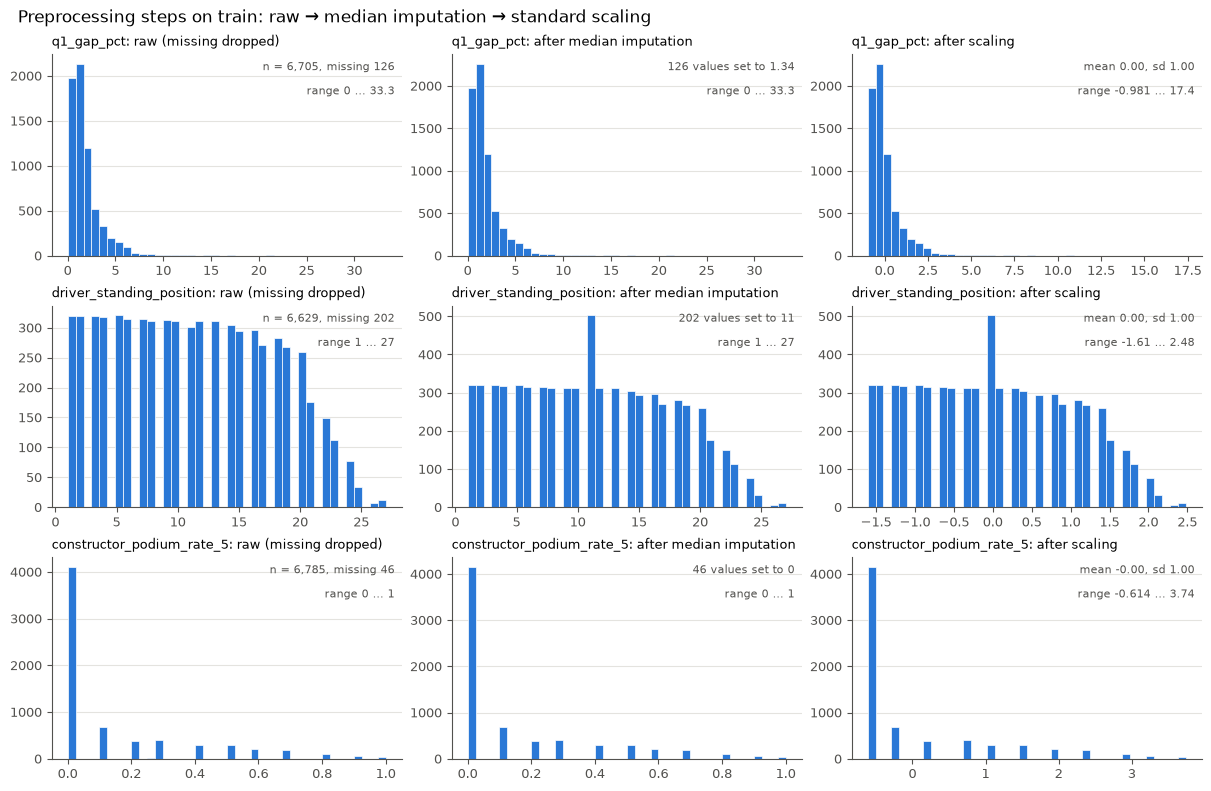

In [115]:
def plot_preprocessing_steps(raw_rows, preprocessor, columns, title):
    """Per feature: distribution raw (non-missing) → after median imputation → after scaling (train)."""
    imputer, scaler = preprocessor.named_steps["impute"], preprocessor.named_steps["scale"]
    imputed = pd.DataFrame(imputer.transform(feature_matrix(raw_rows)), columns=imputer.get_feature_names_out(),
                           index=raw_rows.index)
    scaled = pd.DataFrame(scaler.transform(imputed.to_numpy()), columns=imputed.columns, index=raw_rows.index)
    fig, axes = plt.subplots(len(columns), 3, figsize=(12, 2.6 * len(columns)), constrained_layout=True)
    for row, column in zip(axes, columns):
        raw_values = raw_rows[column].astype(float)
        median = imputer.statistics_[MODEL_FEATURES.index(column)]
        stages = [("raw (missing dropped)", raw_values.dropna(), f"n = {raw_values.notna().sum():,}, missing {raw_values.isna().sum():,}"),
                  ("after median imputation", imputed[column], f"{raw_values.isna().sum():,} values set to {median:.3g}"),
                  ("after scaling", scaled[column], f"mean {scaled[column].mean():.2f}, sd {scaled[column].std(ddof=0):.2f}")]
        for ax, (stage, values, note) in zip(row, stages):
            ax.hist(values, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
            style_axes(ax)
            ax.set_title(f"{column}: {stage}", loc="left", fontsize=9)
            ax.text(0.98, 0.92, note, transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
            ax.text(0.98, 0.80, f"range {values.min():.3g} … {values.max():.3g}", transform=ax.transAxes, ha="right",
                    fontsize=8, color=MUTED)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return fig


save_figure(plot_preprocessing_steps(splits["train"], preprocessor,
                                     ["q1_gap_pct", "driver_standing_position", "constructor_podium_rate_5"],
                                     "Preprocessing steps on train: raw → median imputation → standard scaling"),
            "preprocessing_distributions");

**What changed and why (preprocessing):**
- **Pipeline:** `SimpleImputer(median, add_indicator=True)` → `StandardScaler`, fitted on the 6,831 train rows only (asserted); 15 features become 23 columns: the 8 features with missing values in train (`q1_gap_pct`, the two driver-form rates, constructor form, the four standings values) each get a missing indicator, because the group plots show that "missing" itself goes with a low podium rate.
- **Distributions (plot):** imputation puts every missing value on the train median, which shows as a spike (e.g. 202 missing `driver_standing_position` → 11; 46 missing `constructor_podium_rate_5` → 0, the most common value anyway); the indicator keeps those rows distinguishable. Scaling only shifts and stretches each column (mean 0, sd 1 on train) and keeps the shape. `q1_gap_pct` is heavily right-skewed: after scaling its range is −0.98 … 17.4, so a few wet or failed laps dominate the scale. That is the case for clipping, which experiment E2 tests.
- **Train statistics on other splits:** validation is transformed with the train medians and scales, so its columns are not centred (e.g. `q1_gap_pct` mean −0.21, sd 0.85 on validation: tighter fields in 2020–2021). No statistic is learned from validation or test.

<a id="sec-19"></a>
## 19. Models

All models are fitted on the same 6,831 train rows (2003–2019) and see the same 15
features; every model takes the full feature matrix and selects its columns itself, so
the baseline, the ablation and the inference function use one interface. Hyperparameters
come from small grids, chosen on **validation PR-AUC**; each attempt has its own cell
with its validation result. The test set is not touched in this section.

- **Baseline:** logistic regression on Grid Position only.
- **Logistic regression** on all features, unweighted and with `class_weight="balanced"`.
- **HistGradientBoosting** on the raw features (native NaN handling).
- **NN:** Keras, 1–2 hidden layers with dropout, seed ensemble of 3, two-stage training
  (early stopping on 2018–2019 finds the epoch count E, then a refit on 2003–2019 for E
  epochs; validation is never used for stopping).

In [116]:
RANDOM_STATE = 42
y_by_split = {name: rows.podium.astype(int).to_numpy() for name, rows in splits.items()}
X_by_split = {name: feature_matrix(rows) for name, rows in splits.items()}


def select(columns):
    """Column selector so that every model takes the full feature matrix."""
    return ColumnTransformer([("keep", "passthrough", list(columns))], verbose_feature_names_out=False)


def make_lr(columns, C=1.0, class_weight=None, steps=None):
    """Selector → preprocessing (default: median imputation with indicators → scaling) → logistic regression."""
    return Pipeline([("select", select(columns)), ("pre", steps() if steps else make_preprocessor()),
                     ("model", LogisticRegression(C=C, class_weight=class_weight, max_iter=5_000))])


def make_hgb(columns, **params):
    """Selector → HistGradientBoosting on raw features (NaN handled natively)."""
    return Pipeline([("select", select(columns)),
                     ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE, **params))])


def pr_auc(model, split="validation"):
    """Validation (or other split) PR-AUC of a fitted model."""
    return average_precision_score(y_by_split[split], model.predict_proba(X_by_split[split])[:, 1])


def grid_search(factory, grid):
    """Fit one model per parameter set on train; validation PR-AUC per set and the best fitted model."""
    results, fitted = [], {}
    for params in grid:
        model = factory(**params).fit(X_by_split["train"], y_by_split["train"])
        fitted[str(params)] = model
        results.append({**params, "validation_pr_auc": pr_auc(model)})
    table = pd.DataFrame(results)
    best = table.validation_pr_auc.idxmax()
    return table, fitted[str(grid[best])], grid[best]

In [117]:
baseline = make_lr(["grid_position"]).fit(X_by_split["train"], y_by_split["train"])
assert baseline.named_steps["pre"].named_steps["scale"].n_samples_seen_ == 6_831
print(f"Baseline (Grid Position only): validation PR-AUC {pr_auc(baseline):.3f}")

Baseline (Grid Position only): validation PR-AUC 0.639


**Attempt 2: logistic regression on all features.** Grid over the inverse regularisation
strength C.

In [118]:
LR_GRID = [{"C": C} for C in [0.01, 0.1, 1.0, 10.0]]
lr_table, lr_model, lr_params = grid_search(lambda C: make_lr(MODEL_FEATURES, C=C), LR_GRID)
lr_table.round(4)

,C,validation_pr_auc
0,0.01,0.7102
1,0.10,0.7348
2,1.00,0.7363
3,10.00,0.7360


**Attempt 3: logistic regression with `class_weight="balanced"`** (settles the
weighting question empirically), same grid.

In [119]:
lr_balanced_table, lr_balanced_model, lr_balanced_params = grid_search(
    lambda C: make_lr(MODEL_FEATURES, C=C, class_weight="balanced"), LR_GRID)
lr_balanced_table.round(4)

,C,validation_pr_auc
0,0.01,0.7091
1,0.10,0.7277
2,1.00,0.7289
3,10.00,0.7287


**Attempt 4: HistGradientBoosting.** Grid over learning rate, tree size and minimum leaf
size; 200 boosting iterations, no internal early stopping (the rows are fixed).

In [120]:
HGB_GRID = [{"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": leaf, "max_iter": 200}
            for lr in [0.03, 0.1] for leaves in [7, 31] for leaf in [20, 80]]
hgb_table, hgb_model, hgb_params = grid_search(lambda **p: make_hgb(MODEL_FEATURES, **p), HGB_GRID)
hgb_table.round(4)

,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,validation_pr_auc
0,0.03,7,20,200,0.7043
1,0.03,7,80,200,0.7168
2,0.03,31,20,200,0.6867
3,0.03,31,80,200,0.7029
4,0.10,7,20,200,0.6628
5,0.10,7,80,200,0.6954
6,0.10,31,20,200,0.6395
7,0.10,31,80,200,0.6565


**Attempt 5: neural network (Keras), seed ensemble.** Two-stage training per seed:
stage 1 fits on 2003–2017 and stops early on 2018–2019 (validation PR-AUC of that slice,
patience 10, best weights restored) to find the epoch count E; stage 2 refits on all of
2003–2019 for exactly E epochs. The preprocessing pipeline is fitted on the rows of each
stage. The ensemble averages the probabilities of the 3 seeds.

In [121]:
NN_SEEDS = [11, 22, 33]
EARLY_STOP_SLICE = (2018, 2019)


class KerasEnsemble:
    """Two-stage trained Keras networks for several seeds; predict_proba averages them."""

    def __init__(self, columns, hidden=(32,), dropout=0.2, learning_rate=1e-3, seeds=NN_SEEDS,
                 steps=None, max_epochs=200, batch_size=128):
        self.columns, self.hidden, self.dropout, self.learning_rate = list(columns), hidden, dropout, learning_rate
        self.seeds, self.max_epochs, self.batch_size = seeds, max_epochs, batch_size
        self.steps = steps  # factory for an alternative preprocessing pipeline (experiments E1/E2)

    def _pipeline(self):
        return Pipeline([("select", select(self.columns)),
                         ("pre", self.steps() if self.steps else make_preprocessor())])

    def _network(self, n_inputs, seed):
        keras.utils.set_random_seed(seed)
        layers = [keras.Input((n_inputs,))]
        for units in self.hidden:
            layers += [keras.layers.Dense(units, activation="relu"), keras.layers.Dropout(self.dropout)]
        network = keras.Sequential(layers + [keras.layers.Dense(1, activation="sigmoid")])
        network.compile(optimizer=keras.optimizers.Adam(self.learning_rate), loss="binary_crossentropy",
                        metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
        return network

    def fit(self, X, y, years):
        stop = (years >= EARLY_STOP_SLICE[0]) & (years <= EARLY_STOP_SLICE[1])
        stage_1 = self._pipeline().fit(X[~stop], y[~stop])
        X_fit, X_stop = stage_1.transform(X[~stop]), stage_1.transform(X[stop])
        self.pipeline_ = self._pipeline().fit(X, y)  # stage 2: preprocessing on all train rows
        X_all = self.pipeline_.transform(X)
        self.epochs_, self.networks_ = [], []
        for seed in self.seeds:
            network = self._network(X_fit.shape[1], seed)
            history = network.fit(X_fit, y[~stop], validation_data=(X_stop, y[stop]), epochs=self.max_epochs,
                                  batch_size=self.batch_size, verbose=0,
                                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10,
                                                                           restore_best_weights=True)])
            best_epochs = int(np.argmax(history.history["val_pr_auc"])) + 1
            final = self._network(X_all.shape[1], seed)
            final.fit(X_all, y, epochs=best_epochs, batch_size=self.batch_size, verbose=0)
            self.epochs_.append(best_epochs)
            self.networks_.append(final)
        return self

    def predict_seeds(self, X):
        """Probability per seed, shape (rows, seeds)."""
        X_t = self.pipeline_.transform(X)
        return np.column_stack([network.predict(X_t, verbose=0, batch_size=2_048).ravel() for network in self.networks_])

    def predict_proba(self, X):
        p = self.predict_seeds(X).mean(axis=1)
        return np.column_stack([1 - p, p])


train_years = splits["train"].year.to_numpy()
NN_GRID = [{"hidden": (32,), "dropout": 0.2}, {"hidden": (64, 32), "dropout": 0.3}]
nn_results, nn_fitted = [], {}
for params in NN_GRID:
    ensemble = KerasEnsemble(MODEL_FEATURES, **params).fit(X_by_split["train"], y_by_split["train"], train_years)
    seed_pr_auc = [average_precision_score(y_by_split["validation"], p)
                   for p in ensemble.predict_seeds(X_by_split["validation"]).T]
    nn_fitted[str(params)] = ensemble
    nn_results.append({**params, "epochs_per_seed": ensemble.epochs_, "validation_pr_auc": pr_auc(ensemble),
                       "single_runs_mean": np.mean(seed_pr_auc), "single_runs_sd": np.std(seed_pr_auc, ddof=1)})
nn_table = pd.DataFrame(nn_results)
nn_params = NN_GRID[nn_table.validation_pr_auc.idxmax()]
nn_model = nn_fitted[str(nn_params)]
nn_table.round(4)

,hidden,dropout,epochs_per_seed,validation_pr_auc,single_runs_mean,single_runs_sd
0,"(32,)",0.2,"[33, 98, 45]",0.7278,0.7240,0.0051
1,"(64, 32)",0.3,"[24, 51, 56]",0.7172,0.7122,0.0107


In [122]:
MODELS = {
    "baseline LR (grid only)": baseline,
    "LR": lr_model,
    "LR balanced": lr_balanced_model,
    "HGB": hgb_model,
    "NN ensemble": nn_model,
}
CHOSEN_PARAMS = {"LR": lr_params, "LR balanced": lr_balanced_params, "HGB": hgb_params, "NN ensemble": nn_params}
validation_probabilities = {name: model.predict_proba(X_by_split["validation"])[:, 1] for name, model in MODELS.items()}
assert all(np.all((p >= 0) & (p <= 1)) and len(p) == 780 for p in validation_probabilities.values())
assert all(len(e) == len(NN_SEEDS) and min(e) >= 1 for e in nn_table.epochs_per_seed)
pd.DataFrame({"chosen hyperparameters": {k: str(v) for k, v in CHOSEN_PARAMS.items()},
              "validation PR-AUC": {name: average_precision_score(y_by_split["validation"], p)
                                    for name, p in validation_probabilities.items()}}).round(4)

,chosen hyperparameters,validation PR-AUC
LR,{'C': 1.0},0.7363
LR balanced,{'C': 1.0},0.7289
HGB,"{'learning_rate': 0.03, 'max_leaf_nodes': 7, '...",0.7168
NN ensemble,"{'hidden': (32,), 'dropout': 0.2}",0.7278
baseline LR (grid only),NaN,0.6386


**What the attempts show (validation PR-AUC; selection with the bootstrap rule follows in section 20):**
- **Baseline** (Grid Position only): 0.639.
- **LR, all features:** 0.736 at C = 1 (0.710 at C = 0.01; the curve is flat from C = 0.1, so regularisation hardly matters once it is not too strong).
- **LR balanced:** 0.729 at C = 1, slightly below the unweighted LR at every C, as expected: weights shift the probabilities, not the ranking.
- **HGB:** 0.717 for the most conservative trees in the grid (learning rate 0.03, 7 leaves, at least 80 rows per leaf); larger trees and the higher learning rate fall to 0.64–0.70. With 6,831 rows and one dominant, smooth signal (the grid curve) the trees overfit quickly.
- **NN ensemble:** 0.728 for one hidden layer of 32 units (single runs 0.724 ± 0.005, epochs per seed 33 / 98 / 45); the deeper network reaches 0.717 (single runs 0.712 ± 0.011). The ensemble is a little better than its average single run, as intended.

<a id="sec-20"></a>
## 20. Evaluation on validation and model choice

- **Five required metrics:** ROC-AUC, PR-AUC, F1, precision, recall. F1, precision and
  recall use each model's own threshold, chosen on validation by maximum F1.
- **Metric roles:** **primary PR-AUC** (rare positive class, 15 %; ranks podium Entries
  above the rest without needing a threshold); **secondary F1** at the validation
  threshold; **additional domain metric: top-3 hit rate**: per race the three highest
  probabilities are predicted as podium, and the rate is the share of them that were on
  the podium (every race from 2003 has exactly three Podium Finishes, so precision =
  recall for this rule).
- **Reference rows without a model:** "Grid Position ≤ 3" (scores = −Grid Position for
  the AUCs; the rule itself for F1/precision/recall; top 3 by grid) and the base rate
  (constant score, every Entry predicted as podium).
- **Model choice (bootstrap rule):** PR-AUC difference to the currently chosen simpler model,
  1,000 bootstrap resamples over **races**; a model replaces the simpler one only if the
  95 % interval lies entirely above 0. Ties go to the simpler model (baseline < LR < HGB
  < NN); LR balanced is compared with LR.

In [123]:
N_BOOT = 1_000


def threshold_max_f1(y, p):
    """Probability threshold with the highest F1 on the given rows."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    with np.errstate(invalid="ignore", divide="ignore"):
        f1 = np.where(precision + recall > 0, 2 * precision * recall / (precision + recall), 0)[:-1]
    return float(thresholds[np.argmax(f1)])


def top3_hit_rate(race_ids, y, p):
    """Share of Podium Finishes among the three highest probabilities per race."""
    frame = pd.DataFrame({"race": race_ids, "y": y, "p": p})
    top = frame.groupby("race").p.rank(method="first", ascending=False).le(3)
    return frame.y[top].mean()


def evaluate(y, p, threshold, race_ids, predicted=None):
    """The five metrics at a threshold (or for given hard predictions) plus the top-3 hit rate."""
    predicted = p >= threshold if predicted is None else predicted
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, predicted, zero_division=0), "precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0), "top-3 hit rate": top3_hit_rate(race_ids, y, p)}


def reference_rows(split):
    """Metrics of the two reference rules on a split."""
    rows, y = splits[split], y_by_split[split]
    grid_score = -rows.grid_position.to_numpy(dtype=float)
    base = np.full(len(y), y_by_split["train"].mean())
    return {"reference: Grid Position ≤ 3": evaluate(y, grid_score, None, rows.raceId, rows.grid_position.le(3).to_numpy()),
            "reference: base rate": {**evaluate(y, base, None, rows.raceId, np.ones(len(y), bool)), "top-3 hit rate": np.nan}}


def bootstrap_difference(y, p_simple, p_complex, race_ids, n_boot=N_BOOT, seed=RANDOM_STATE):
    """PR-AUC difference (complex − simple) with a 95 % bootstrap interval over races."""
    rng = np.random.default_rng(seed)
    race_ids = np.asarray(race_ids)
    races = np.unique(race_ids)
    rows_of = {race: np.flatnonzero(race_ids == race) for race in races}
    draws = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_of[race] for race in rng.choice(races, len(races), replace=True)])
        draws.append(average_precision_score(y[idx], p_complex[idx]) - average_precision_score(y[idx], p_simple[idx]))
    low, high = np.percentile(draws, [2.5, 97.5])
    observed = average_precision_score(y, p_complex) - average_precision_score(y, p_simple)
    return {"difference": observed, "ci_low": low, "ci_high": high, "wins": bool(low > 0)}

In [124]:
thresholds = {name: threshold_max_f1(y_by_split["validation"], p) for name, p in validation_probabilities.items()}
validation_race_ids = splits["validation"].raceId.to_numpy()
validation_table = pd.DataFrame({
    **{name: evaluate(y_by_split["validation"], p, thresholds[name], validation_race_ids)
       for name, p in validation_probabilities.items()},
    **reference_rows("validation"),
}).T.assign(threshold=pd.Series(thresholds))
validation_table.round(3)

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
baseline LR (grid only),0.909,0.639,0.692,0.692,0.692,0.692,0.474
LR,0.933,0.736,0.699,0.592,0.855,0.684,0.198
LR balanced,0.931,0.729,0.695,0.680,0.709,0.675,0.790
HGB,0.932,0.717,0.698,0.645,0.761,0.684,0.267
NN ensemble,0.928,0.728,0.708,0.683,0.735,0.701,0.364
reference: Grid Position ≤ 3,0.909,0.639,0.692,0.692,0.692,0.692,NaN
reference: base rate,0.500,0.150,0.261,0.150,1.000,NaN,NaN


In [125]:
y_val, p_val = y_by_split["validation"], validation_probabilities
comparisons = {}
chosen = "baseline LR (grid only)"
for candidate in ["LR", "LR balanced", "HGB", "NN ensemble"]:
    reference = "LR" if candidate == "LR balanced" else chosen
    result = bootstrap_difference(y_val, p_val[reference], p_val[candidate], validation_race_ids)
    comparisons[f"{candidate} vs. {reference}"] = result
    if candidate == "LR balanced":
        if result["wins"] and chosen == "LR":
            chosen = "LR balanced"
    elif result["wins"]:
        chosen = candidate
CHOSEN_MODEL = chosen
comparison_table = pd.DataFrame(comparisons).T
assert set(splits["test"].index).isdisjoint(splits["validation"].index)  # only validation used so far
print("chosen model:", CHOSEN_MODEL)
assert CHOSEN_MODEL == "LR"  # the Markdown below is written for this outcome
comparison_table.round(4)

chosen model: LR


,difference,ci_low,ci_high,wins
LR vs. baseline LR (grid only),0.097673,0.045222,0.149819,True
LR balanced vs. LR,-0.007407,-0.017358,0.000223,False
HGB vs. LR,-0.019446,-0.047129,0.00934,False
NN ensemble vs. LR,-0.008467,-0.028911,0.010995,False


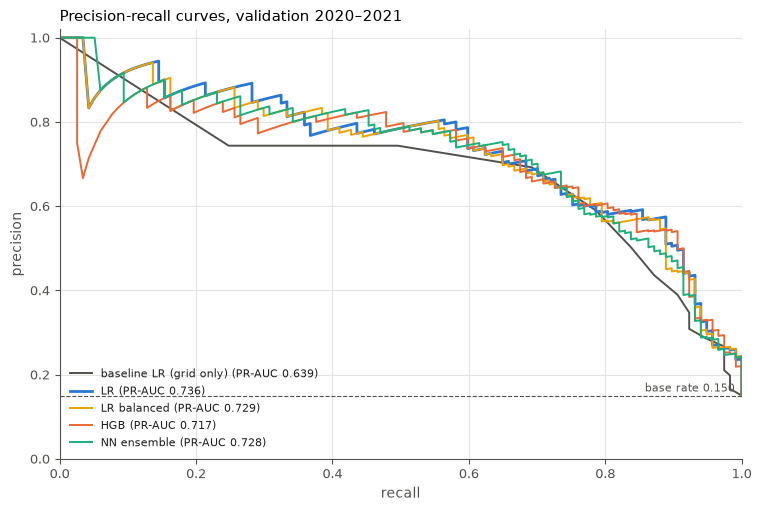

In [126]:
MODEL_COLORS = {"baseline LR (grid only)": MUTED, "LR": BLUE, "HGB": ORANGE, "NN ensemble": "#1baf7a",
                "LR balanced": "#eda100"}  # categorical slots 1–4 in fixed order, grey for the baseline


def plot_pr_curves(probabilities, split, title):
    """Precision-recall curves of all models on one split, with the base rate."""
    fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
    y = y_by_split[split]
    for name, p in probabilities.items():
        precision, recall, _ = precision_recall_curve(y, p)
        ax.plot(recall, precision, color=MODEL_COLORS[name], linewidth=2 if name == CHOSEN_MODEL else 1.4,
                label=f"{name} (PR-AUC {average_precision_score(y, p):.3f})")
    ax.axhline(y.mean(), color=MUTED, linewidth=0.8, linestyle="--")
    ax.text(0.99, y.mean() + 0.01, f"base rate {y.mean():.3f}", fontsize=8, color=MUTED, ha="right")
    style_axes(ax)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_xlabel("recall", color=MUTED)
    ax.set_ylabel("precision", color=MUTED)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, fontsize=8, loc="lower left", labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_pr_curves(validation_probabilities, "validation", "Precision-recall curves, validation 2020–2021"),
            "models_pr_curves_validation");

**Model choice, fixed before any test result (validation evidence above):** the **logistic regression on all features (C = 1)**.
- It is the only model that beats its simpler predecessor by the bootstrap rule: PR-AUC 0.736 against 0.639 for the grid-only baseline, a difference of +0.098 (95 % bootstrap interval over races +0.045 to +0.150).
- None of the more complex models beats it: HGB −0.019 (−0.047 to +0.009), NN ensemble −0.008 (−0.029 to +0.011), so the tie rule keeps the simpler LR. The balanced weighting does not help either (−0.007, −0.017 to +0.000), so no class weights.
- **Secondary metric:** F1 0.699 at the validation threshold 0.198, against 0.692 for the rule "Grid Position ≤ 3"; the low threshold buys recall (0.855) at the cost of precision (0.592). The NN has the highest F1 (0.708), but the differences in F1 are a few podiums in 39 races and were not part of the selection rule.
- **Domain metric:** the top-3 hit rate of the LR (0.684) is **not** better than simply taking the top 3 of the grid (0.692); only the NN is slightly above (0.701). So the features improve the *ranking across all Entries* (PR-AUC) clearly, but they hardly change *which three drivers* are the most likely podium finishers in a race: that is mostly decided by the grid.

This choice is final. The test section reports every model, but does not change it.

<a id="sec-21"></a>
## 21. Test evaluation (2022–2024), once

Every model is evaluated **once** on test with its own validation threshold, next to the
reference rows; train and validation are shown alongside. The model choice above stays as
it is, whatever the test numbers show (ADR 0001).

In [127]:
probabilities = {split: {name: model.predict_proba(X_by_split[split])[:, 1] for name, model in MODELS.items()}
                 for split in SPLITS}
comparison = pd.concat({
    split: pd.DataFrame({
        **{name: evaluate(y_by_split[split], p, thresholds[name], splits[split].raceId.to_numpy())
           for name, p in probabilities[split].items()},
        **reference_rows(split),
    }).T
    for split in SPLITS
}, names=["split", "model"])
METRICS = ["ROC-AUC", "PR-AUC", "F1", "precision", "recall", "top-3 hit rate"]
comparison = comparison[METRICS]
assert np.allclose(comparison.loc["validation"].loc[list(MODELS), METRICS].astype(float),
                   validation_table.loc[list(MODELS), METRICS].astype(float))  # same numbers as before the choice
with pd.option_context("display.max_rows", 30):
    display(comparison.round(3))  # train, validation and test: all five metrics plus the top-3 hit rate

ROC-AUC  PR-AUC     F1  precision  \
split      model                                                             
train      baseline LR (grid only)         0.909   0.626  0.646      0.647   
           LR                              0.930   0.687  0.653      0.526   
           LR balanced                     0.930   0.678  0.649      0.609   
           HGB                             0.947   0.736  0.695      0.596   
           NN ensemble                     0.936   0.698  0.675      0.610   
           reference: Grid Position ≤ 3    0.909   0.626  0.646      0.647   
           reference: base rate            0.500   0.141  0.247      0.141   
validation baseline LR (grid only)         0.909   0.639  0.692      0.692   
           LR                              0.933   0.736  0.699      0.592   
           LR balanced                     0.931   0.729  0.695      0.680   
           HGB                             0.932   0.717  0.698      0.645   
           NN ensemble                     0.928   0.728  0.708      0.683   
           reference: Grid Position ≤ 3    0.909   0.639  0.692      0.692   
           reference: base rate            0.500   0.150  0.261      0.150   
test       baseline LR (grid only)         0.914   0.647  0.649      0.650   
           LR                              0.935   0.706  0.675      0.543   
           LR balanced                     0.934   0.698  0.644      0.632   
           HGB                             0.939   0.720  0.675      0.584   
           NN ensemble                     0.938   0.705  0.674      0.634   
           reference: Grid Position ≤ 3    0.914   0.647  0.649      0.650   
           reference: base rate            0.500   0.150  0.261      0.150   

                                         recall  top-3 hit rate  
split      model                                                 
train      baseline LR (grid only)        0.646           0.647  
           LR                             0.862           0.652  
           LR balanced                    0.695           0.632  
           HGB                            0.834           0.680  
           NN ensemble                    0.755           0.666  
           reference: Grid Position ≤ 3   0.646           0.647  
           reference: base rate           1.000             NaN  
validation baseline LR (grid only)        0.692           0.692  
           LR                             0.855           0.684  
           LR balanced                    0.709           0.675  
           HGB                            0.761           0.684  
           NN ensemble                    0.735           0.701  
           reference: Grid Position ≤ 3   0.692           0.692  
           reference: base rate           1.000             NaN  
test       baseline LR (grid only)        0.647           0.652  
           LR                             0.892           0.662  
           LR balanced                    0.657           0.632  
           HGB                            0.799           0.632  
           NN ensemble                    0.721           0.652  
           reference: Grid Position ≤ 3   0.647           0.652  
           reference: base rate           1.000             NaN

**Train–validation gap (overfitting check):** PR-AUC and F1 on train minus validation per
model; a large positive gap would mean the model fits the training seasons much better
than unseen ones.

In [128]:
fit_gap = pd.DataFrame({
    "train PR-AUC": comparison.loc["train"]["PR-AUC"], "validation PR-AUC": comparison.loc["validation"]["PR-AUC"],
    "gap PR-AUC": comparison.loc["train"]["PR-AUC"] - comparison.loc["validation"]["PR-AUC"],
    "train F1": comparison.loc["train"]["F1"], "validation F1": comparison.loc["validation"]["F1"],
    "gap F1": comparison.loc["train"]["F1"] - comparison.loc["validation"]["F1"],
}).loc[list(MODELS)].astype(float)
assert fit_gap["gap PR-AUC"].idxmax() == "HGB" and (fit_gap.drop("HGB")["gap PR-AUC"] < 0).all()  # stated below
fit_gap.round(3)

,train PR-AUC,validation PR-AUC,gap PR-AUC,train F1,validation F1,gap F1
model,,,,,,
baseline LR (grid only),0.626,0.639,-0.013,0.646,0.692,-0.046
LR,0.687,0.736,-0.049,0.653,0.699,-0.046
LR balanced,0.678,0.729,-0.051,0.649,0.695,-0.045
HGB,0.736,0.717,0.019,0.695,0.698,-0.003
NN ensemble,0.698,0.728,-0.030,0.675,0.708,-0.033


**Overfitting, per model (gap = train − validation):**
- **Baseline LR (grid only):** train PR-AUC 0.626, validation 0.639 (gap −0.013); one feature, nothing to overfit.
- **LR (chosen):** 0.687 → 0.736 (gap −0.049); validation is *easier* than train, no sign of overfitting; F1 0.653 → 0.699.
- **LR balanced:** 0.678 → 0.729 (gap −0.051); same picture as the unweighted LR.
- **HGB:** 0.736 → 0.717 (gap **+0.019**), the only model that is better on train than on validation: the trees fit the training seasons more closely, even in the most conservative grid setting (F1 0.695 → 0.698).
- **NN ensemble:** 0.698 → 0.728 (gap −0.030); early stopping on 2018–2019 and the refit for a fixed number of epochs keep it from overfitting.

Validation (2020–2021) is the easiest of the three periods for every model, so a negative gap is the norm here; the useful signal is the *relative* gap, where HGB stands out.

,highest on test
PR-AUC,HGB
F1,LR
top-3 hit rate,LR


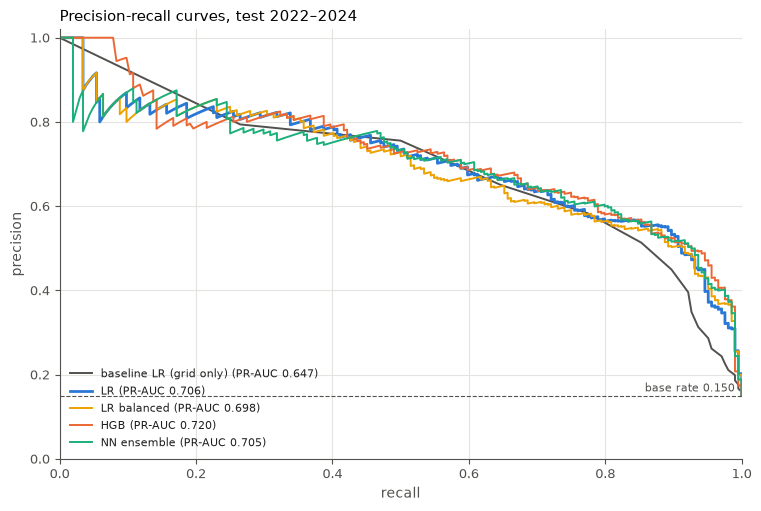

In [129]:
save_figure(plot_pr_curves(probabilities["test"], "test", "Precision-recall curves, test 2022–2024"),
            "models_pr_curves_test");
test_best = comparison.loc["test"].loc[list(MODELS)].astype(float).idxmax()
assert test_best["PR-AUC"] == "HGB"  # stated in the Markdown below
test_best[["PR-AUC", "F1", "top-3 hit rate"]].rename("highest on test").to_frame()

For information only (not a selection step): the same bootstrap comparison on test for
the chosen LR against the baseline and against the model with the highest test PR-AUC.

In [130]:
test_race_ids = splits["test"].raceId.to_numpy()
pd.DataFrame({
    "LR vs. baseline (test)": bootstrap_difference(y_by_split["test"], probabilities["test"]["baseline LR (grid only)"],
                                                   probabilities["test"]["LR"], test_race_ids),
    "HGB vs. LR (test)": bootstrap_difference(y_by_split["test"], probabilities["test"]["LR"],
                                              probabilities["test"]["HGB"], test_race_ids),
}).T.round(4)

,difference,ci_low,ci_high,wins
LR vs. baseline (test),0.058351,0.009607,0.101491,True
HGB vs. LR (test),0.014286,-0.011237,0.040745,False


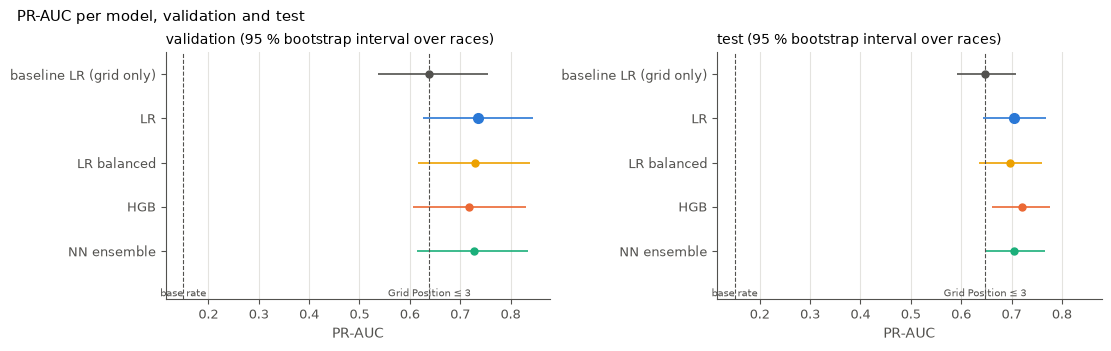

In [131]:
def bootstrap_pr_auc(y, p, race_ids, n_boot=N_BOOT, seed=RANDOM_STATE):
    """PR-AUC with a 95 % bootstrap interval over races."""
    rng = np.random.default_rng(seed)
    race_ids = np.asarray(race_ids)
    races = np.unique(race_ids)
    rows_of = {race: np.flatnonzero(race_ids == race) for race in races}
    draws = [average_precision_score(y[idx], p[idx])
             for idx in (np.concatenate([rows_of[r] for r in rng.choice(races, len(races))]) for _ in range(n_boot))]
    return average_precision_score(y, p), *np.percentile(draws, [2.5, 97.5])


def plot_pr_auc_intervals(title):
    """Validation and test PR-AUC per model with bootstrap intervals; reference rules as lines."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True, constrained_layout=True)
    for ax, split in zip(axes, ["validation", "test"]):
        race_ids = splits[split].raceId.to_numpy()
        names = list(MODELS)
        stats_ = [bootstrap_pr_auc(y_by_split[split], probabilities[split][name], race_ids) for name in names]
        y = np.arange(len(names))[::-1]
        for yi, name, (score, low, high) in zip(y, names, stats_):
            ax.errorbar(score, yi, xerr=[[score - low], [high - score]], fmt="o", color=MODEL_COLORS[name],
                        ecolor=MODEL_COLORS[name], markersize=7 if name == CHOSEN_MODEL else 5, elinewidth=1.2)
        grid_rule = comparison.loc[split].loc["reference: Grid Position ≤ 3", "PR-AUC"]
        base_rate = comparison.loc[split].loc["reference: base rate", "PR-AUC"]
        for value, label in [(grid_rule, "Grid Position ≤ 3"), (base_rate, "base rate")]:
            ax.axvline(value, color=MUTED, linewidth=0.8, linestyle="--")
            ax.text(value, -0.85, label, fontsize=7, color=MUTED, ha="center", va="top")
        ax.set_ylim(-1.1, len(names) - 0.5)
        ax.set_yticks(y, names)
        style_axes(ax)
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
        ax.set_title(f"{split} (95 % bootstrap interval over races)", loc="left", fontsize=10)
        ax.set_xlabel("PR-AUC", color=MUTED)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    return fig


save_figure(plot_pr_auc_intervals("PR-AUC per model, validation and test"), "models_pr_auc_intervals");

**Result on test (chosen model: LR on all features, threshold 0.198 from validation):**
- **Primary PR-AUC 0.706** against 0.647 for the grid-only baseline (+0.058, bootstrap interval over the 68 test races +0.010 to +0.101) and 0.150 for the base rate; ROC-AUC 0.935.
- **Secondary F1 0.675** (precision 0.543, recall 0.892) against 0.649 for the rule "Grid Position ≤ 3". The validation threshold carries over: recall stays high, precision drops somewhat, as on validation.
- **Top-3 hit rate 0.662** against 0.652 for the top 3 of the grid: on test the LR is marginally ahead, on validation it was marginally behind; in both cases the difference is a handful of podiums.
- **Another model is higher on test:** HGB has the best test PR-AUC (0.720) and ROC-AUC (0.939). The difference to the LR (+0.014, −0.011 to +0.041) is within noise, and the choice was fixed on validation, where HGB was below the LR. **The choice stays LR.** The HGB result is reported, not used.
- **No overfitting of the chosen model:** LR train PR-AUC 0.687, validation 0.736, test 0.706. Validation happens to be the easiest of the three periods for every model; HGB fits train more closely (0.736) than validation (0.717).

**Why PR-AUC as primary and F1 as secondary, defended:** podiums are 15 % of rows, so accuracy or ROC-AUC look good even for weak models (the grid-only baseline already has ROC-AUC 0.91) while PR-AUC shows the difference that matters: how cleanly the podium Entries are ranked above the rest, without fixing a threshold. F1 at the validation threshold is the honest hard-decision metric, because the threshold was chosen without test data; it depends on that one threshold and is therefore secondary.

<a id="sec-22"></a>
## 22. Experiments: ablation and preprocessing order (E1, E2)

### Ablation by feature group (chosen model)

The LR (C = 1) is refitted five times, each time without one of the five feature groups;
the drop in validation PR-AUC against the full model shows how much each group adds
**given the others** (with a bootstrap interval over races).

In [132]:
full_lr_validation = validation_probabilities["LR"]
ablation_rows = {}
for group, columns in FEATURE_GROUPS.items():
    kept = [f for f in MODEL_FEATURES if f not in columns]
    reduced = make_lr(kept, **lr_params).fit(X_by_split["train"], y_by_split["train"])
    p = reduced.predict_proba(X_by_split["validation"])[:, 1]
    diff = bootstrap_difference(y_val, p, full_lr_validation, validation_race_ids)
    ablation_rows[f"without {group}"] = {"features_left": len(kept), "validation_pr_auc": average_precision_score(y_val, p),
                                         "drop": diff["difference"], "ci_low": diff["ci_low"], "ci_high": diff["ci_high"],
                                         "group_needed": diff["wins"]}
ablation = pd.DataFrame(ablation_rows).T
ablation.round(4)

,features_left,validation_pr_auc,drop,ci_low,ci_high,group_needed
without grid,13,0.735096,0.001163,-0.000296,0.003022,False
without qualifying,11,0.71699,0.019268,0.002216,0.037766,True
without driver_form,12,0.7221,0.014158,-0.007374,0.029312,False
without constructor_form,14,0.736752,-0.000494,-0.007404,0.006758,False
without standings,10,0.715738,0.02052,-0.009134,0.041736,False


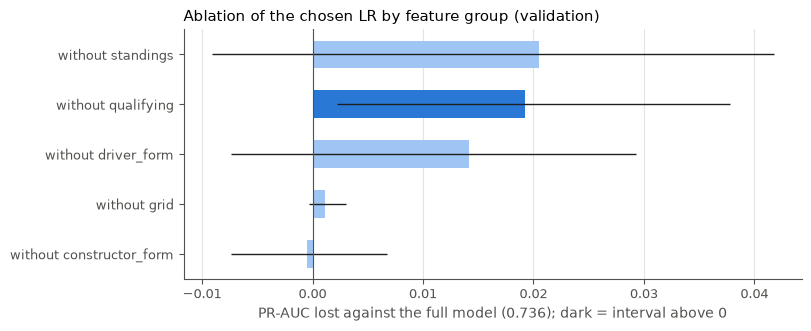

In [133]:
def plot_ablation(ablation, full_score, title):
    """PR-AUC lost when a group is removed, with the bootstrap interval of the loss."""
    table = ablation.sort_values("drop")
    fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
    y = range(len(table))
    ax.barh(list(y), table["drop"].astype(float), color=[BLUE if needed else "#9ec5f4" for needed in table.group_needed],
            height=0.55)
    ax.errorbar(table["drop"].astype(float), list(y), xerr=[(table["drop"] - table.ci_low).astype(float),
                                                            (table.ci_high - table["drop"]).astype(float)],
                fmt="none", ecolor=INK, elinewidth=1)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_yticks(list(y), table.index)
    style_axes(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_xlabel(f"PR-AUC lost against the full model ({full_score:.3f}); dark = interval above 0", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11)
    return fig


save_figure(plot_ablation(ablation, average_precision_score(y_val, full_lr_validation),
                          "Ablation of the chosen LR by feature group (validation)"), "experiments_ablation");

### E1 and E2: preprocessing order

Measured on validation PR-AUC with the LR (C = 1) and the NN ensemble (best
configuration), every variant with missing indicators:
- **Median control:** median impute → scale (production) vs. scale → median impute.
- **E1:** KNN impute (k = 5) → scale vs. scale → KNN impute. KNN uses distances, so
  whether the features are scaled before it decides which neighbours fill a gap.
- **E2:** clipping at the train 1st/99th percentile **before** vs. **after** KNN imputation
  (both with scaling before KNN, so only the position of the clipping changes; clipping
  applies to the feature columns, never to the 0/1 indicators).

In [134]:
class QuantileClipper(TransformerMixin, BaseEstimator):
    """Clip the first `n_columns` columns to their train 1st/99th percentiles (NaN stays NaN)."""

    def __init__(self, n_columns, low=1, high=99):
        self.n_columns, self.low, self.high = n_columns, low, high

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)[:, :self.n_columns]
        self.low_, self.high_ = np.nanpercentile(X, self.low, axis=0), np.nanpercentile(X, self.high, axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        X[:, :self.n_columns] = np.clip(X[:, :self.n_columns], self.low_, self.high_)
        return X


N_FEATURES = len(MODEL_FEATURES)
PREPROCESSING_VARIANTS = {
    "median: impute → scale (production)": make_preprocessor,
    "median: scale → impute": lambda: Pipeline([("scale", StandardScaler()),
                                                 ("impute", SimpleImputer(strategy="median", add_indicator=True))]),
    "E1 KNN: impute → scale": lambda: Pipeline([("impute", KNNImputer(n_neighbors=5, add_indicator=True)),
                                                 ("scale", StandardScaler())]),
    "E1 KNN: scale → impute": lambda: Pipeline([("scale", StandardScaler()),
                                                 ("impute", KNNImputer(n_neighbors=5, add_indicator=True))]),
    "E2 clip before KNN": lambda: Pipeline([("clip", QuantileClipper(N_FEATURES)), ("scale", StandardScaler()),
                                             ("impute", KNNImputer(n_neighbors=5, add_indicator=True))]),
    "E2 clip after KNN": lambda: Pipeline([("scale", StandardScaler()),
                                            ("impute", KNNImputer(n_neighbors=5, add_indicator=True)),
                                            ("clip", QuantileClipper(N_FEATURES))]),
}
variant_probabilities = {"LR": {}, "NN ensemble": {}}
for name, steps in PREPROCESSING_VARIANTS.items():
    lr_variant = make_lr(MODEL_FEATURES, steps=steps, **lr_params).fit(X_by_split["train"], y_by_split["train"])
    nn_variant = KerasEnsemble(MODEL_FEATURES, steps=steps, **nn_params).fit(X_by_split["train"], y_by_split["train"],
                                                                             train_years)
    variant_probabilities["LR"][name] = lr_variant.predict_proba(X_by_split["validation"])[:, 1]
    variant_probabilities["NN ensemble"][name] = nn_variant.predict_proba(X_by_split["validation"])[:, 1]
variant_table = pd.DataFrame({model: {name: average_precision_score(y_val, p) for name, p in by_variant.items()}
                              for model, by_variant in variant_probabilities.items()})
assert np.isclose(variant_table.loc["median: impute → scale (production)", "LR"],
                  average_precision_score(y_val, validation_probabilities["LR"]))  # same as the chosen model
variant_table.round(4)

,LR,NN ensemble
median: impute → scale (production),0.7363,0.7278
median: scale → impute,0.7312,0.7251
E1 KNN: impute → scale,0.7349,0.7268
E1 KNN: scale → impute,0.7322,0.7314
E2 clip before KNN,0.7313,0.7272
E2 clip after KNN,0.7310,0.7315


In [135]:
ORDER_PAIRS = {
    "median control: scale → impute minus impute → scale": ("median: impute → scale (production)", "median: scale → impute"),
    "E1: KNN scale → impute minus impute → scale": ("E1 KNN: impute → scale", "E1 KNN: scale → impute"),
    "E2: clip before minus after KNN": ("E2 clip after KNN", "E2 clip before KNN"),
    "adoption: best KNN variant minus production median": None,
}
order_rows = {}
for model, by_variant in variant_probabilities.items():
    knn_names = [n for n in by_variant if "KNN" in n]
    best_knn = max(knn_names, key=lambda n: average_precision_score(y_val, by_variant[n]))
    for label, pair in ORDER_PAIRS.items():
        first, second = pair if pair else ("median: impute → scale (production)", best_knn)
        result = bootstrap_difference(y_val, by_variant[first], by_variant[second], validation_race_ids)
        order_rows[(model, label if pair else f"{label} ({best_knn})")] = result
order_table = pd.DataFrame(order_rows).T
order_table.round(4)

difference  \
LR          median control: scale → impute minus impute → s...  -0.005098   
            E1: KNN scale → impute minus impute → scale         -0.002692   
            E2: clip before minus after KNN                      0.000251   
            adoption: best KNN variant minus production med...  -0.001364   
NN ensemble median control: scale → impute minus impute → s...  -0.002699   
            E1: KNN scale → impute minus impute → scale          0.004546   
            E2: clip before minus after KNN                     -0.004317   
            adoption: best KNN variant minus production med...   0.003745   

                                                                  ci_low  \
LR          median control: scale → impute minus impute → s...  -0.01193   
            E1: KNN scale → impute minus impute → scale        -0.006272   
            E2: clip before minus after KNN                     -0.00073   
            adoption: best KNN variant minus production med... -0.007322   
NN ensemble median control: scale → impute minus impute → s... -0.016066   
            E1: KNN scale → impute minus impute → scale        -0.004305   
            E2: clip before minus after KNN                    -0.018006   
            adoption: best KNN variant minus production med... -0.004656   

                                                                 ci_high  \
LR          median control: scale → impute minus impute → s... -0.000356   
            E1: KNN scale → impute minus impute → scale         0.000191   
            E2: clip before minus after KNN                     0.001664   
            adoption: best KNN variant minus production med...  0.002494   
NN ensemble median control: scale → impute minus impute → s...  0.011879   
            E1: KNN scale → impute minus impute → scale         0.013916   
            E2: clip before minus after KNN                     0.007839   
            adoption: best KNN variant minus production med...  0.013194   

                                                                 wins  
LR          median control: scale → impute minus impute → s...  False  
            E1: KNN scale → impute minus impute → scale         False  
            E2: clip before minus after KNN                     False  
            adoption: best KNN variant minus production med...  False  
NN ensemble median control: scale → impute minus impute → s...  False  
            E1: KNN scale → impute minus impute → scale         False  
            E2: clip before minus after KNN                     False  
            adoption: best KNN variant minus production med...  False

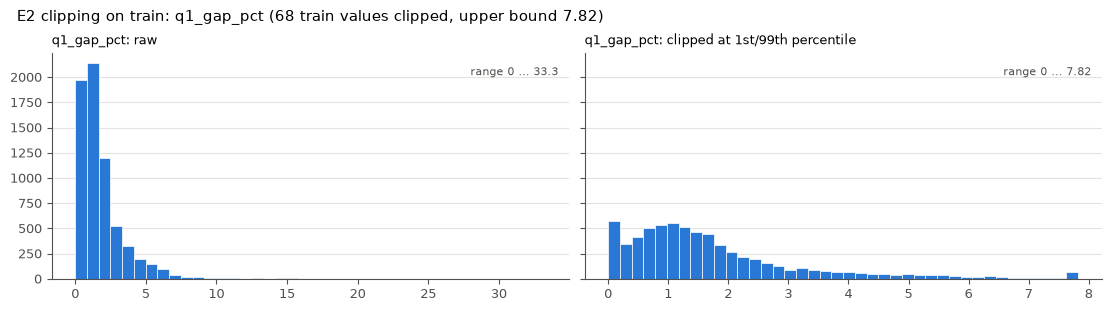

In [136]:
def plot_clipping(rows, column, title):
    """Train distribution of one feature before and after clipping at its train 1st/99th percentile."""
    values = rows[column].dropna().astype(float)
    low, high = np.percentile(values, [1, 99])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True, constrained_layout=True)
    for ax, (stage, data) in zip(axes, [("raw", values), ("clipped at 1st/99th percentile", values.clip(low, high))]):
        ax.hist(data, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
        style_axes(ax)
        ax.set_title(f"{column}: {stage}", loc="left", fontsize=9)
        ax.text(0.98, 0.9, f"range {data.min():.3g} … {data.max():.3g}", transform=ax.transAxes, ha="right", fontsize=8,
                color=MUTED)
    clipped = int((values > high).sum() + (values < low).sum())
    fig.suptitle(f"{title} ({clipped} train values clipped, upper bound {high:.2f})", x=0.01, ha="left", fontsize=11)
    return fig


save_figure(plot_clipping(splits["train"], "q1_gap_pct", "E2 clipping on train: q1_gap_pct"), "experiments_clipping");

**Ablation (chosen LR, validation PR-AUC 0.736):**
- Only the **qualifying group** is needed by the bootstrap rule: without it PR-AUC falls to 0.717 (−0.019, interval +0.002 to +0.038).
- **Standings** (−0.021) and **driver form** (−0.014) lose about as much, but their intervals include 0 (−0.009 to +0.042, −0.007 to +0.029): each is largely covered by the other groups (ρ up to 0.87 between form and standings, section 17).
- **Grid** (−0.001) and **constructor form** (+0.000) add nothing on top of the rest: the Grid Position is almost a copy of the Qualifying Position (ρ = 0.97) plus `grid_drop`, and constructor form is covered by the constructor standings. So no single group carries the model alone; the gain over the grid-only baseline (+0.098) comes from qualifying pace plus the season context together. Removing grid or constructor form would not cost validation PR-AUC, but both stay in the model, because the choice was made with all groups and the differences are within noise.

**E1/E2 (validation PR-AUC; all differences with 1,000 bootstrap resamples over races):**
- **Median control (predicted null effect):** for the NN, scale → impute vs. impute → scale differs by −0.003 (−0.016 to +0.012). For the LR the difference is small but its interval lies just below 0 (−0.005, −0.012 to −0.000). The reason is not the imputation: in the scale → impute order the missing indicators are appended *after* scaling and stay 0/1, while in the production order they are scaled too, which changes how strongly the L2 penalty acts on them. So even the "null" control is not exactly null for a regularised model.
- **E1 (KNN):** the order makes no detectable difference: LR −0.003 (−0.006 to +0.000), NN +0.005 (−0.004 to +0.014). With only 8 columns with gaps and the strongest features (grid, qualifying) always present, the neighbours KNN picks barely depend on scaling.
- **E2 (clipping before vs. after KNN):** LR +0.000 (−0.001 to +0.002), NN −0.004 (−0.018 to +0.008); clipping 68 train values of `q1_gap_pct` at 7.8 % (plot) and the other features at their 1st/99th percentiles does not change the result.
- **Adoption rule:** the best KNN variant does not beat the production median pipeline for either model (LR −0.001, NN +0.004, both intervals include 0), so **the median imputation with indicators stays**.

<a id="sec-23"></a>
## 23. Explainability of the chosen model

The chosen model is the **logistic regression**. Two views, both on validation:
- **Permutation importance** (PR-AUC scoring, 20 repeats): how much validation PR-AUC
  drops when one feature, or one whole feature group, is shuffled. Per group as well,
  because correlated features (grid ↔ qualifying ρ = 0.97) hide each other's importance
  when shuffled one at a time.
- **SHAP** (`LinearExplainer`): the contribution of each input to the predicted
  **log-odds** of a row, relative to the average train row. **Feature space:** for the
  LR, SHAP explains the *imputed and scaled* columns, including the missing indicators;
  the local waterfalls are labelled with the *raw* feature values.

**Both describe the model, not the race.** A large contribution means the model's
prediction is associated with that input; it does not mean the input causes podiums.

In [137]:
X_val = X_by_split["validation"]
feature_importance = permutation_importance(lr_model, X_val, y_val, scoring="average_precision", n_repeats=20,
                                            random_state=RANDOM_STATE)
feature_importance_table = pd.DataFrame({"mean_drop": feature_importance.importances_mean,
                                         "sd": feature_importance.importances_std}, index=MODEL_FEATURES)
feature_importance_table["group"] = [g for f in MODEL_FEATURES for g, cols in FEATURE_GROUPS.items() if f in cols]


def group_permutation_importance(model, X, y, groups, n_repeats=20, seed=RANDOM_STATE):
    """PR-AUC drop when all columns of a group are shuffled together (same row permutation)."""
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    rows = {}
    for group, columns in groups.items():
        drops = []
        for _ in range(n_repeats):
            shuffled = X.copy()
            order = rng.permutation(len(X))
            shuffled[columns] = X[columns].to_numpy()[order]
            drops.append(base - average_precision_score(y, model.predict_proba(shuffled)[:, 1]))
        rows[group] = {"mean_drop": np.mean(drops), "sd": np.std(drops)}
    return pd.DataFrame(rows).T


group_importance = group_permutation_importance(lr_model, X_val, y_val, FEATURE_GROUPS)
display(feature_importance_table.sort_values("mean_drop", ascending=False).round(4))
group_importance.sort_values("mean_drop", ascending=False).round(4)

,mean_drop,sd,group
grid_position,0.1183,0.0311,grid
qualifying_position,0.1130,0.0298,qualifying
q1_gap_pct,0.0389,0.0226,qualifying
driver_podium_rate_5,0.0344,0.0235,driver_form
driver_standing_position,0.0192,0.0135,standings
constructor_points_share,0.0160,0.0171,standings
constructor_podium_rate_5,0.0087,0.0129,constructor_form
grid_zero,0.0073,0.0074,grid
constructor_standing_position,0.0045,0.0081,standings
grid_drop,0.0021,0.0042,qualifying


,mean_drop,sd
grid,0.1324,0.0288
standings,0.1267,0.0247
qualifying,0.1123,0.0203
driver_form,0.0360,0.0215
constructor_form,0.0205,0.0153


/Users/alperdogan/Developer/jupyter-projekte/f1-podium/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


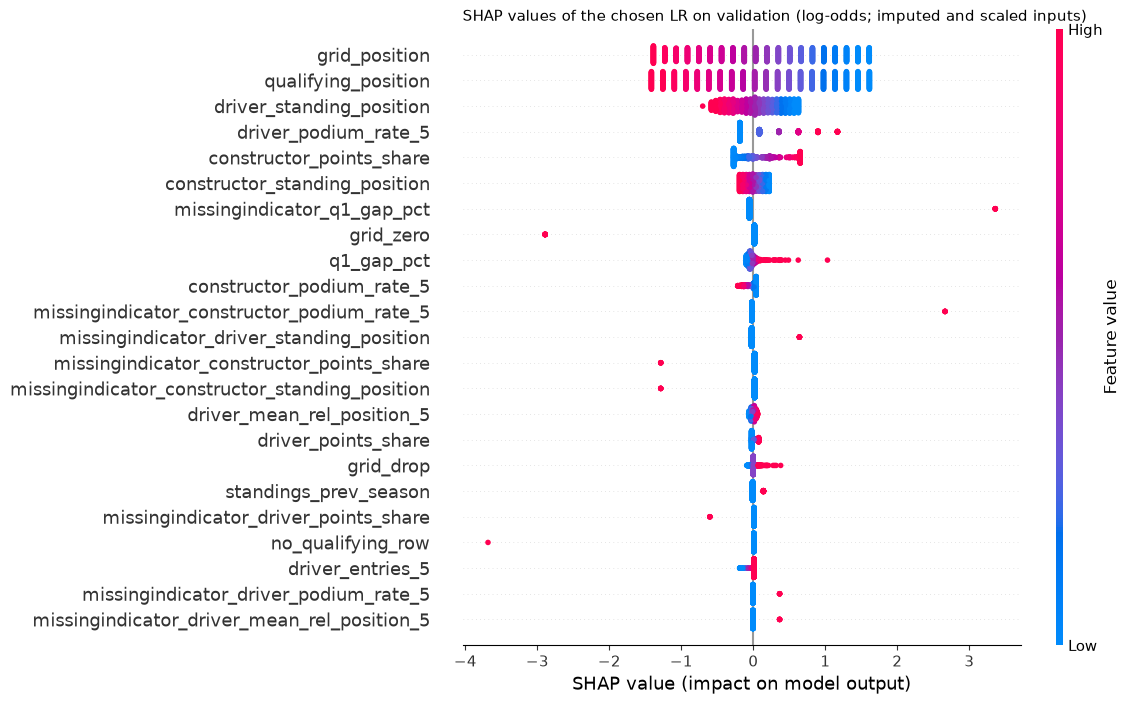

In [138]:
lr_pre = Pipeline(lr_model.steps[:-1])  # selector → imputation → scaling, fitted on train
lr_imputer = lr_model.named_steps["pre"].named_steps["impute"]
lr_columns = MODEL_FEATURES + [f"missingindicator_{MODEL_FEATURES[i]}" for i in lr_imputer.indicator_.features_]
assert len(lr_columns) == lr_model.named_steps["model"].coef_.shape[1]
X_train_t = pd.DataFrame(lr_pre.transform(X_by_split["train"]), columns=lr_columns)
X_val_t = pd.DataFrame(lr_pre.transform(X_val), columns=lr_columns)
explainer = shap.LinearExplainer(lr_model.named_steps["model"], shap.maskers.Independent(X_train_t, max_samples=1_000))
shap_validation = explainer(X_val_t)
assert shap_validation.values.shape == (780, len(lr_columns))
logit = lr_model.named_steps["model"].decision_function(X_val_t)
assert np.allclose(shap_validation.values.sum(axis=1) + shap_validation.base_values, logit, atol=1e-6)  # additivity

plt.figure()  # SHAP draws on the current figure
shap.plots.beeswarm(shap_validation, max_display=len(lr_columns), show=False)
fig = plt.gcf()
fig.set_size_inches(9, 8)
fig.axes[0].set_title("SHAP values of the chosen LR on validation (log-odds; imputed and scaled inputs)",
                      loc="left", fontsize=11)
save_figure(fig, "xai_shap_beeswarm");

,SHAP mean |group sum|,group permutation drop,ablation drop
grid,0.8651,0.1324,0.001163
qualifying,0.7783,0.1123,0.019268
standings,0.6779,0.1267,0.02052
driver_form,0.2487,0.0360,0.014158
constructor_form,0.0633,0.0205,-0.000494


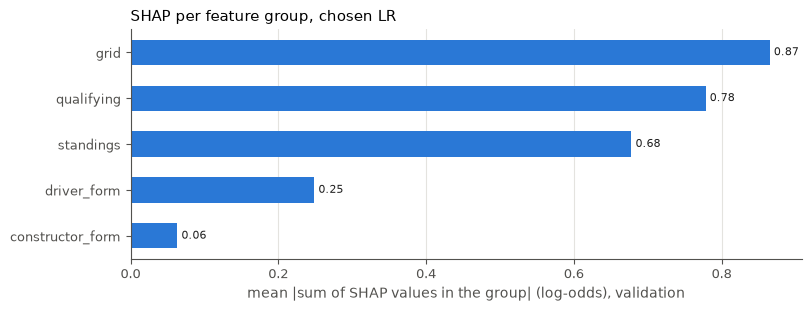

In [139]:
def column_group(column):
    """Feature group of a transformed column (missing indicators belong to their feature's group)."""
    base = column.removeprefix("missingindicator_")
    return next(group for group, columns in FEATURE_GROUPS.items() if base in columns)


group_shap = pd.DataFrame(shap_validation.values, columns=lr_columns).T.groupby(column_group).sum().T
group_shap_mean = group_shap.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.barh(group_shap_mean.index, group_shap_mean.values, color=BLUE, height=0.55)
ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=8, color=INK, padding=3)
style_axes(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_xlabel("mean |sum of SHAP values in the group| (log-odds), validation", color=MUTED)
ax.set_title("SHAP per feature group, chosen LR", loc="left", fontsize=11)
save_figure(fig, "xai_shap_by_group");
pd.DataFrame({"SHAP mean |group sum|": group_shap_mean, "group permutation drop": group_importance.mean_drop,
              "ablation drop": ablation["drop"].rename(lambda name: name.removeprefix("without "))}).sort_values(
    "SHAP mean |group sum|", ascending=False).round(4)

**Local explanations on test (rule fixed in advance, no hand-picking):** the podium from
grid ≥ 8 with the *lowest* predicted probability, and the Front-Row Start without a
podium with the *highest* predicted probability, i.e. the largest gap between prediction
and outcome in each group.

podium from the back: Pierre Gasly, 2024 São Paulo Grand Prix, grid 13, P(podium) = 0.00, podium = True


missed Front-Row Start: Max Verstappen, 2024 Australian Grand Prix, grid 1, P(podium) = 0.86, podium = False


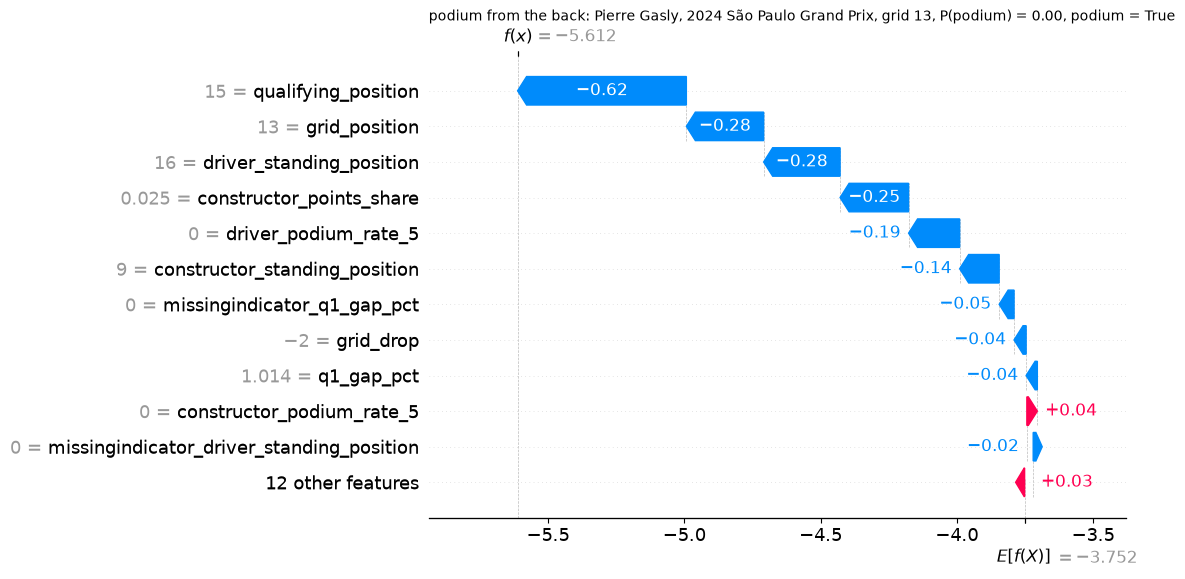

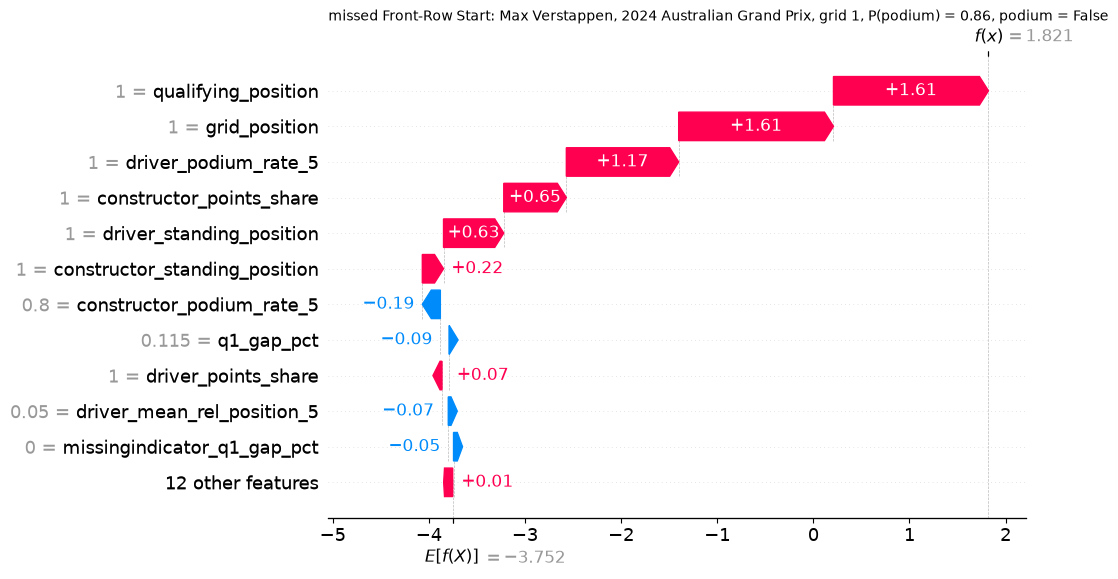

In [140]:
test_rows = splits["test"].assign(p=probabilities["test"]["LR"])
from_the_back = test_rows[test_rows.podium & test_rows.grid_position.ge(8)].sort_values("p").iloc[0]
missed_front_row = test_rows[~test_rows.podium & test_rows.grid_position.le(2)].sort_values("p").iloc[-1]
race_names = clean["races"].set_index("raceId").name
driver_names = clean["drivers"].set_index("driverId").apply(lambda d: f"{d.forename} {d.surname}", axis=1)


def raw_display_values(row):
    """Raw values for the transformed columns: the feature value, or 0/1 for a missing indicator."""
    return np.array([float(pd.isna(row[c.removeprefix("missingindicator_")])) if c.startswith("missingindicator_")
                     else float(row[c]) for c in lr_columns])


def local_waterfall(row, title, name):
    X_row = pd.DataFrame(lr_pre.transform(feature_matrix(row.to_frame().T)), columns=lr_columns)
    explanation = explainer(X_row)[0]
    explanation = shap.Explanation(values=explanation.values, base_values=explanation.base_values,
                                   data=raw_display_values(row), feature_names=lr_columns)
    plt.figure()  # SHAP draws on the current figure
    shap.plots.waterfall(explanation, max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 6)
    fig.axes[0].set_title(title, loc="left", fontsize=10)
    return save_figure(fig, name)


for row, label, name in [(from_the_back, "podium from the back", "xai_waterfall_podium_from_back"),
                         (missed_front_row, "missed Front-Row Start", "xai_waterfall_missed_front_row")]:
    title = (f"{label}: {driver_names[row.driverId]}, {row.year} {race_names[row.raceId]}, grid {int(row.grid_position)}, "
             f"P(podium) = {row.p:.2f}, podium = {bool(row.podium)}")
    print(title)
    local_waterfall(row, title, name)

**Interpretation (association, not cause):**
- **Grid and qualifying dominate**, in every view: shuffling Grid Position alone costs 0.118 validation PR-AUC, Qualifying Position alone 0.113, and in SHAP both spread from about −1.4 to +1.6 log-odds (high positions = low numbers = higher predicted probability). Next come `q1_gap_pct` (0.039), driver podium rate (0.034) and the standings (driver position 0.019, constructor points share 0.016).
- **Permutation, SHAP and ablation disagree for the grid group, and that is expected.** Shuffling the Grid Position alone costs 0.118 and the group 0.132, yet the ablation lost nothing without it (section 22). Shuffling creates impossible rows (grid no longer equals qualifying plus `grid_drop`) which the fitted model has never seen; a retrained model without the grid simply takes the same information from the Qualifying Position (ρ = 0.97). Permutation importance measures how much *this* model relies on a column; ablation measures how much the *information* is needed.
- **Per group (bar chart):** grid 0.87, qualifying 0.78, standings 0.68, driver form 0.25, constructor form 0.06 mean |log-odds|; group permutation ranks standings (0.127) just behind grid (0.132) and ahead of qualifying (0.112), then driver form (0.036) and constructor form (0.021). Constructor form is the weakest group in all three views (it is largely covered by the constructor standings).
- **Counter-intuitive signs come from collinearity:** a larger `q1_gap_pct` gets a slightly *positive* SHAP value for some rows, because the model already accounts for the Qualifying Position and the gap only adjusts it. The missing indicators carry large values for single rows (e.g. `no_qualifying_row` −3.7, `grid_zero` −2.9: none of these rows reached the podium in train), but each rests on a few dozen training rows. Neither should be read on its own.
- **Local: podium from the back.** Pierre Gasly, São Paulo 2024, from grid 13 (qualified 15th), predicted 0.00, finished 3rd. Every pre-race signal pointed down (qualifying −0.62, grid −0.28, standings position 16, constructor ninth): nothing in the data before the race suggested a podium, so this is a miss the model cannot avoid with pre-race information.
- **Local: missed Front-Row Start.** Max Verstappen, Australia 2024, pole, predicted 0.86, retired after 3 laps (status "Brakes"). Qualifying, grid, recent podiums (5 of 5) and both championship leads all push the prediction up; the cause of the miss, a mechanical failure, is post-race information the model by design cannot see.

**Non-causality statement:** these explanations describe how the fitted logistic regression turns pre-race inputs into a probability. They show associations in the 2003–2019 training data, not mechanisms: a better Qualifying Position is associated with a higher predicted podium probability, which does not mean that moving a car up the grid would by itself cause a podium.

<a id="sec-24"></a>
## 24. Inference function `predict_podium`

`predict_podium(record, history, model)` predicts one Entry from a **raw pre-race
record**. It applies the same rules and the same feature functions as training:
- **`grid == 0`:** → N (`field_size`), flag `grid_zero`.
- **No qualifying:** no Qualifying Position → the harmonised Grid Position, flag `no_qualifying_row`.
- **Round 1:** standings after the previous round, in round 1 the previous season's final
  standings; form and standings come from `history` **strictly before** the record's date.
- Anything still missing (e.g. no q1 time, no form for a debut) stays NaN and is filled
  by the model's own pipeline (median imputation with missing indicators, fitted on train).

The record holds: `date`, `year`, `round`, `driverId`, `constructorId`, `grid`,
`field_size`, and optionally `raceId`, `qualifying_position`, `q1`, `race_fastest_q1`.

In [141]:
RECORD_FIELDS = ["date", "year", "round", "driverId", "constructorId", "grid", "field_size"]
OPTIONAL_FIELDS = ["raceId", "qualifying_position", "q1", "race_fastest_q1"]


def predict_podium(record, history, model=lr_model, threshold=thresholds["LR"]):
    """Podium probability for one raw pre-race record, with the rules that were applied."""
    missing_fields = [f for f in RECORD_FIELDS if f not in record]
    if missing_fields:
        raise ValueError(f"record lacks required fields: {missing_fields}")
    target = pd.DataFrame([{**{f: np.nan for f in OPTIONAL_FIELDS}, **record}])
    target["raceId"] = target.raceId.fillna(-1).astype("int64")
    target["date"] = pd.to_datetime(target.date)
    target = target.astype({"qualifying_position": "float64", "q1": "float64", "race_fastest_q1": "float64"})
    features = build_features(target, history)  # the feature functions only read rows before `date`
    probability = float(model.predict_proba(feature_matrix(features))[0, 1])
    row = features.iloc[0]
    rules = []
    if record["grid"] == 0:
        rules.append(f"grid 0 → Grid Position {int(row.grid_position)} (N)")
    if pd.isna(target.qualifying_position[0]):
        rules.append(f"no Qualifying Position → {int(row.qualifying_position)} (harmonised grid)")
    if row.standings_prev_season:
        rules.append("round 1 → previous season's final standings")
    imputed = [f for f in MODEL_FEATURES if pd.isna(row[f])]
    if imputed:
        rules.append(f"pipeline imputes (median + indicator): {', '.join(imputed)}")
    return {"probability": probability, "podium": probability >= threshold, "threshold": threshold,
            "rules_applied": rules, "features": row[MODEL_FEATURES]}


def record_from_tables(race_id, driver_id, tables=clean, entries_=entries):
    """Raw pre-race record of an existing Entry, built only from the cleaned tables (no Modeling Table)."""
    race = tables["races"].set_index("raceId").loc[race_id]
    result = tables["results"].query("raceId == @race_id and driverId == @driver_id").iloc[0]
    quali = tables["qualifying"].query("raceId == @race_id")
    own = quali[quali.driverId.eq(driver_id)]
    return {"raceId": race_id, "date": race.date, "year": int(race.year), "round": int(race["round"]),
            "driverId": driver_id, "constructorId": int(result.constructorId), "grid": int(result.grid),
            "field_size": int(entries_.raceId.eq(race_id).sum()),
            "qualifying_position": float(own.position.iloc[0]) if len(own) else np.nan,
            "q1": float(own.q1.iloc[0]) if len(own) else np.nan, "race_fastest_q1": float(quali.q1.min())}


def show_prediction(label, record, result):
    print(f"{label}: P(podium) = {result['probability']:.3f} → podium = {result['podium']} "
          f"(threshold {result['threshold']:.3f})")
    for rule in result["rules_applied"] or ["no fallback needed"]:
        print("   -", rule)

**(a) Complete record** (Max Verstappen, Australia 2024, the missed Front-Row Start from
section 23), built from the raw tables; the probability must equal the model's prediction
for that Modeling Table row.

In [142]:
demo_row = missed_front_row
record_a = record_from_tables(demo_row.raceId, demo_row.driverId)
result_a = predict_podium(record_a, history)
show_prediction("(a) complete record", record_a, result_a)
assert np.isclose(result_a["probability"], demo_row.p)

(a) complete record: P(podium) = 0.861 → podium = True (threshold 0.198)
   - no fallback needed


**(b) The same record with qualifying missing** (no Qualifying Position, no q1 time).

In [143]:
record_b = {**record_a, "qualifying_position": np.nan, "q1": np.nan}
result_b = predict_podium(record_b, history)
show_prediction("(b) qualifying missing", record_b, result_b)
assert result_b["features"].no_qualifying_row and result_b["features"].qualifying_position == record_a["grid"]
pd.DataFrame({"(a) complete": result_a["features"], "(b) qualifying missing": result_b["features"]}).T[
    FEATURE_GROUPS["grid"] + FEATURE_GROUPS["qualifying"]]

(b) qualifying missing: P(podium) = 0.834 → podium = True (threshold 0.198)
   - no Qualifying Position → 1 (harmonised grid)
   - pipeline imputes (median + indicator): q1_gap_pct


,grid_position,grid_zero,qualifying_position,no_qualifying_row,grid_drop,q1_gap_pct
(a) complete,1,False,1,False,0,0.114686
(b) qualifying missing,1,False,1,True,0,NaN


**(c) A debut driver without history:** the first test-period Entry of a driver with no
earlier Entry (form NaN, imputed by the pipeline).

In [144]:
debut_test = splits["test"].assign(p=probabilities["test"]["LR"])
debut_test = debut_test[debut_test.driver_entries_5.eq(0)].iloc[0]
record_c = record_from_tables(debut_test.raceId, debut_test.driverId)
result_c = predict_podium(record_c, history)
show_prediction(f"(c) debut: {driver_names[debut_test.driverId]}, {debut_test.year} {race_names[debut_test.raceId]}",
                record_c, result_c)
assert result_c["features"].driver_entries_5 == 0 and np.isnan(result_c["features"].driver_podium_rate_5)
assert np.isclose(result_c["probability"], debut_test.p)

(c) debut: Guanyu Zhou, 2022 Bahrain Grand Prix: P(podium) = 0.008 → podium = False (threshold 0.198)
   - round 1 → previous season's final standings
   - pipeline imputes (median + indicator): driver_podium_rate_5, driver_mean_rel_position_5, driver_standing_position, driver_points_share


**What the demos show:**
- **(a)** The raw record gives exactly the Modeling Table prediction (0.861, asserted with `np.isclose`): training and inference compute the same features with the same functions.
- **(b)** Without qualifying data the qualifying fallback sets the Qualifying Position to the Grid Position (1), `no_qualifying_row` = 1 and `grid_drop` = 0, and the pipeline imputes the missing q1 gap; the probability falls only slightly (0.861 → 0.834), because the grid carries most of the same information.
- **(c)** For a debut (Guanyu Zhou, Bahrain 2022, round 1 and first F1 race) the form and driver standings are NaN and imputed by the pipeline with their indicators; the constructor standings come from the previous season. The prediction (0.008) again equals the Modeling Table row (asserted).

<a id="sec-25"></a>
## 25. Limitations

Collected from the decisions in the sections above and the ADRs in `docs/adr/`,
plus what the modeling run showed.

**Data, rows and split**
- **Training Window from 2003 is provisional (ADR 0001).** The planned experiment (same model trained from 1994 vs. 2003, validation PR-AUC, bootstrap over races) was **skipped for time**. The 2003 start is justified by qualifying coverage: no qualifying data before 1994, only 6–59 % of races in 1996–2002, every race from 2003, so every training row has a real Qualifying Position. A longer window might add rows but would mix in eras with patchy qualifying and larger fields.
- **Non-Starters stay in the Modeling Table.** Entries withdrawn after qualifying look like Starters before the race (35 did-not-start Entries from 2003, most with a qualifying row); they are kept because no pre-race field identifies them, and they count as non-podium rows.
- **`grid_zero` changes meaning:** before 2015 it marks 7 non-Starters, from 2015 mostly Pit-Lane Starts; pre-2015 pit-lane starts are not flagged. `grid_drop` captures both eras the same way.
- **Validation is short and special:** 39 races in 2020–2021, with a shortened 2020 season (17 races) and one-off circuits. Bootstrap intervals over races are wide, so model differences of ±0.02 PR-AUC cannot be told apart (section 20). The optional refit on 2003–2021 and an expanding-window cross-validation inside train were not run.
- **Sprints:** no sprint features. In 2023–2024 (12 sprint races in test) a pre-race signal goes unused; in the six 2021–2022 sprint races `grid_drop` reflects the sprint result, which training never shows (about 120 rows).
- **Indianapolis 500 points (ADR 0003)** stay in the original 1950–1960 `driver_standings`; irrelevant for the model (standings are only read from 2002), but relevant to any standings analysis of those years.

**Features**
- **Constructor identity (baseline only):** renames cluster at the split boundaries (AlphaTauri 2020, Aston Martin and Alpine 2021; RB and Sauber on ID 15 in 2024), so those teams start validation and test with "no history" more often than in training. The lineage challenger that would have bridged renames was dropped.
- **Team continuity is not performance continuity:** at regulation changes (2009, 2014, and 2022, the test boundary) form and standings from before say little (e.g. Honda 2008 → Brawn 2009). This is distribution shift the model cannot see.
- **Gap to pole:** in 2003–2005 single-lap qualifying ran with race fuel, so the q1 gap partly reflects fuel strategy; from 2006 front-runners often do not push in Q1, so the gap understates their pace.
- **Standings:** Force India 2018 restarts as a new entrant under the same ID (constructor points 59 → 18 from round 14); kept as recorded. Rookies and new constructor IDs in round 1 have no fallback (82 / 52 rows NaN, imputed).
- **Driver form has no time limit:** 34 rows follow a break of two or more seasons and use form from before the break.

**Models, evaluation, explanation**
- **The features improve the ranking, not the race-level pick:** PR-AUC rises clearly over the grid-only baseline, but the top-3 hit rate of the chosen LR is about the same as taking the top 3 of the grid (validation 0.684 vs. 0.692, test 0.662 vs. 0.652).
- **The choice is not robust to the split:** HGB is best on test (PR-AUC 0.720 vs. 0.706), within noise; the choice was fixed on validation and stays.
- **Pre-race information has a ceiling:** retirements (e.g. Verstappen, Australia 2024, brakes) and chaotic races (e.g. Gasly, São Paulo 2024, from grid 13) are post-race events no pre-race feature can predict.
- **Correlated features:** grid ↔ qualifying (ρ = 0.97) and standings position ↔ points share (ρ ≈ −0.9) make single-feature importance unstable; permutation importance and ablation disagree for the grid group (section 23). Single coefficients and SHAP values of the LR are not interpreted on their own.
- **E1's median control is not exactly null for a regularised model:** the order of scaling and imputation changes how the missing indicators are scaled, and with that the L2 penalty on them (section 22).
- **All explanations are associations in 2003–2019 data**, not causes.

**Descriptive questions**
- **Question 1:** with 10–24 Front-Row Starts per circuit and period, a circuit-level change cannot be established; only the pooled rise is.
- **Question 2:** the home effect is an association controlled for grid and decade only; driver skill, team and car are not controlled. "No evidence of a home advantage" is not "no home advantage".
- **Question 3:** the drop in mechanical retirements is associated with the 2022 period, not measured as an effect of the regulations (engines, budgets and the field changed at the same time); several status texts are borderline calls (tested with the broad definition).
- **Starter** is defined from post-race fields (laps, status), which the scope principle allows for descriptive questions only; 56 rows without evidence of a start are excluded.

<a id="sec-closing"></a>
## Closing: raw protection

Second check of the raw checksums after all steps: no step of the notebook changed
`data/raw/`.

In [145]:
assert file_checksums(RAW) == expected_checksums